# Marine Heatwaves off Portugal (OISST, 1981–2025): descriptive statistics by isobath

This notebook computes descriptive statistics for the monthly MHW summary tables
(`MHW_summary_table_wide_oisst.19812025.Portugal_<depth>m_bathymetry.csv`) for each
isobath (200, 400, 600, 800, 1000 m) and each zone (NW, S, SW), and then compares the isobaths.

**How to use:** put the CSV files in `DATA_DIR` (or edit `FILES` below) and *Run All*.
Any isobath file that is missing is skipped, so the notebook also runs with only one file.

**Notes on the data**
- Jan–Aug 1981 are empty (OISST starts in Sep 1981) and are dropped.
- Event counts use **`mean_n_events`** (mean number of events per grid cell) only. `number_of_events` is the
  spatial sum over grid cells (= `mean_n_events` × 25 cells in NW, 6 in S, 12 in SW), so it depends on zone size
  and is **not used**.
- `mean_n_events` counts events **starting** in a month. Some months have MHW activity
  (`activity`, `mean_intensity`) but 0 new events, because an event that began earlier is still running.
  Two flags are therefore used:
  - **onset month**: `mean_n_events > 0`
  - **active month**: `activity_degC_days_m2 > 0`
- `mean_area`, `mean_duration`, `mean_intensity` are only defined when there is an event, so
  their statistics are *conditional* on MHW months. The count/area/activity variables are
  zero‑inflated, so statistics are shown both for **all months** and for **MHW months only**.

In [1]:
import re, glob
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore", category=FutureWarning)
pd.options.mode.copy_on_write = True
from scipy import stats

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
pd.set_option("display.max_columns", 50)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False})

DATA_DIR = Path("DATA/OUTPUT")                      # folder with the CSV files
PATTERN  = "MHW_summary_table_wide_oisst.19812025.Portugal_*m_bathymetry.csv"
OUT_DIR  = Path("outputs"); OUT_DIR.mkdir(exist_ok=True)

# Either auto-detect files by pattern ...
FILES = {int(re.search(r"_(\d+)m_bathymetry", p).group(1)): Path(p)
         for p in glob.glob(str(DATA_DIR / PATTERN))}
# ... or set them explicitly, e.g.
# FILES = {200: Path("..._200m_bathymetry.csv"), 400: Path("..._400m_bathymetry.csv"), ...}

FILES = dict(sorted(FILES.items()))
print("Isobaths found:", list(FILES))

Isobaths found: [200, 400, 600, 800, 1000]


## 1. Load and tidy

In [2]:
VARS = {
    "mean_n_events":         "Mean N events (per grid cell)",
    "mean_duration_days":    "Mean duration (days)",
    "mean_intensity_degC":   "Mean intensity (°C)",
    "mean_area_km2":         "Mean area (km²)",
    "sum_area_km2":          "Total area (km²)",
    "activity_degC_days_m2": "Activity (°C·days·m²)",
}
CONDITIONAL = ["mean_duration_days", "mean_intensity_degC", "mean_area_km2"]  # defined only with events

frames = []
for depth, path in FILES.items():
    d = pd.read_csv(path)
    d["Isobath"] = depth
    frames.append(d)
df = pd.concat(frames, ignore_index=True)

# drop months before the OISST record
df = df.drop(columns="number_of_events")          # spatial sum – not used (see notes)
df = df.dropna(subset=["mean_n_events", "activity_degC_days_m2"], how="all").copy()
df["Date"]   = pd.to_datetime(dict(year=df.Year, month=df.Month, day=1))
df["Season"] = df.Month.map({12:"DJF",1:"DJF",2:"DJF",3:"MAM",4:"MAM",5:"MAM",
                             6:"JJA",7:"JJA",8:"JJA",9:"SON",10:"SON",11:"SON"})
df["Decade"] = (df.Year // 10 * 10).astype(str) + "s"
df["onset"]  = df.mean_n_events > 0
df["active"] = df.activity_degC_days_m2 > 0
df["activity_1e9"] = df.activity_degC_days_m2 / 1e9   # easier to read
ZONE_ORDER = ["NW", "SW", "S"]                      # order used in every table and plot
ZONES = [z for z in ZONE_ORDER if z in df.Zone.unique()] + sorted(set(df.Zone) - set(ZONE_ORDER))
df["Zone"] = pd.Categorical(df.Zone, categories=ZONES, ordered=True)

print(df.shape, "| zones:", ZONES, "| period:", df.Date.min().date(), "→", df.Date.max().date())
df.head()

(7980, 16) | zones: ['NW', 'SW', 'S'] | period: 1981-09-01 → 2025-12-01


,Zone,Year,Month,activity_degC_days_m2,mean_area_km2,mean_duration_days,mean_intensity_degC,mean_n_events,sum_area_km2,Isobath,Date,Season,Decade,onset,active,activity_1e9
8,NW,1981,9,0.000,NaN,NaN,NaN,0.000,0.000,200,1981-09-01,SON,1980s,False,False,0.000
9,NW,1981,10,0.000,NaN,NaN,NaN,0.000,0.000,200,1981-10-01,SON,1980s,False,False,0.000
10,NW,1981,11,0.000,NaN,NaN,NaN,0.000,0.000,200,1981-11-01,SON,1980s,False,False,0.000
11,NW,1981,12,0.000,NaN,NaN,NaN,0.000,0.000,200,1981-12-01,DJF,1980s,False,False,0.000
12,NW,1982,1,0.000,NaN,NaN,NaN,0.000,0.000,200,1982-01-01,DJF,1980s,False,False,0.000


### Data completeness

In [3]:
check = (df.groupby(["Isobath","Zone"])
           .agg(n_months=("Date","size"), first=("Date","min"), last=("Date","max"),
                onset_months=("onset","sum"), active_months=("active","sum"))
         )
check["%onset"]  = 100 * check.onset_months  / check.n_months
check["%active"] = 100 * check.active_months / check.n_months
missing = df.groupby(["Isobath","Zone"])[list(VARS)].apply(lambda g: g.isna().sum())
display(check); display(missing.add_prefix("NaN_"))

n_months      first       last  onset_months  active_months  \
Isobath Zone                                                                
200     NW         532 1981-09-01 2025-12-01           180            201   
        SW         532 1981-09-01 2025-12-01           183            210   
        S          532 1981-09-01 2025-12-01           147            174   
400     NW         532 1981-09-01 2025-12-01           188            209   
        SW         532 1981-09-01 2025-12-01           182            209   
        S          532 1981-09-01 2025-12-01           147            174   
600     NW         532 1981-09-01 2025-12-01           188            209   
        SW         532 1981-09-01 2025-12-01           186            213   
        S          532 1981-09-01 2025-12-01           157            188   
800     NW         532 1981-09-01 2025-12-01           192            213   
        SW         532 1981-09-01 2025-12-01           204            228   
        S          532 1981-09-01 2025-12-01           189            215   
1000    NW         532 1981-09-01 2025-12-01           192            213   
        SW         532 1981-09-01 2025-12-01           204            228   
        S          532 1981-09-01 2025-12-01           189            215   

              %onset  %active  
Isobath Zone                   
200     NW    33.835   37.782  
        SW    34.398   39.474  
        S     27.632   32.707  
400     NW    35.338   39.286  
        SW    34.211   39.286  
        S     27.632   32.707  
600     NW    35.338   39.286  
        SW    34.962   40.038  
        S     29.511   35.338  
800     NW    36.090   40.038  
        SW    38.346   42.857  
        S     35.526   40.414  
1000    NW    36.090   40.038  
        SW    38.346   42.857  
        S     35.526   40.414

NaN_mean_n_events  NaN_mean_duration_days  \
Isobath Zone                                              
200     NW                    0                     352   
        SW                    0                     349   
        S                     0                     385   
400     NW                    0                     344   
        SW                    0                     350   
        S                     0                     385   
600     NW                    0                     344   
        SW                    0                     346   
        S                     0                     375   
800     NW                    0                     340   
        SW                    0                     328   
        S                     0                     343   
1000    NW                    0                     340   
        SW                    0                     328   
        S                     0                     343   

              NaN_mean_intensity_degC  NaN_mean_area_km2  NaN_sum_area_km2  \
Isobath Zone                                                                 
200     NW                        331                352                 0   
        SW                        322                349                 0   
        S                         358                385                 0   
400     NW                        323                344                 0   
        SW                        323                350                 0   
        S                         358                385                 0   
600     NW                        323                344                 0   
        SW                        319                346                 0   
        S                         344                375                 0   
800     NW                        319                340                 0   
        SW                        304                328                 0   
        S                         317                343                 0   
1000    NW                        319                340                 0   
        SW                        304                328                 0   
        S                         317                343                 0   

              NaN_activity_degC_days_m2  
Isobath Zone                             
200     NW                            0  
        SW                            0  
        S                             0  
400     NW                            0  
        SW                            0  
        S                             0  
600     NW                            0  
        SW                            0  
        S                             0  
800     NW                            0  
        SW                            0  
        S                             0  
1000    NW                            0  
        SW                            0  
        S                             0

## 2. Descriptive statistics

In [4]:
def describe(s: pd.Series) -> pd.Series:
    s = s.dropna()
    n = len(s)
    if n == 0:
        return pd.Series(dtype=float)
    q1, q3 = s.quantile([.25, .75])
    return pd.Series({
        "n": n, "mean": s.mean(), "std": s.std(), "se": s.std() / np.sqrt(n),
        "CV_%": 100 * s.std() / s.mean() if s.mean() else np.nan,
        "min": s.min(), "P5": s.quantile(.05), "Q1": q1, "median": s.median(),
        "Q3": q3, "P95": s.quantile(.95), "max": s.max(), "IQR": q3 - q1,
        "skew": stats.skew(s) if n > 2 else np.nan,
        "kurtosis": stats.kurtosis(s) if n > 3 else np.nan,
        "%zero": 100 * (s == 0).mean(), "sum": s.sum(),
    })

def stats_table(data, by, variables, mask=None):
    d = data if mask is None else data[mask]
    out = {v: d.groupby(by)[v].apply(describe).unstack() for v in variables}
    return pd.concat(out, names=["Variable"]).reorder_levels([*range(1, len(by)+1), 0]).sort_index()

VARS_TAB = ["mean_n_events", "sum_area_km2", "activity_1e9"] + CONDITIONAL

### 2a. All months (zeros included) – by isobath and zone

In [5]:
T_all = stats_table(df, ["Isobath","Zone"], ["mean_n_events","sum_area_km2","activity_1e9"])
T_all

n    mean     std     se    CV_%   min    P5  \
Isobath Zone Variable                                                           
200     NW   activity_1e9  532.000  67.341 170.446  7.390 253.109 0.000 0.000   
             mean_n_events 532.000   0.163   0.328  0.014 201.152 0.000 0.000   
             sum_area_km2  532.000 320.983 645.838 28.001 201.206 0.000 0.000   
        SW   activity_1e9  532.000  30.278  71.270  3.090 235.385 0.000 0.000   
             mean_n_events 532.000   0.169   0.325  0.014 192.195 0.000 0.000   
             sum_area_km2  532.000  97.426 188.897  8.190 193.888 0.000 0.000   
        S    activity_1e9  532.000  16.741  38.192  1.656 228.140 0.000 0.000   
             mean_n_events 532.000   0.184   0.368  0.016 199.900 0.000 0.000   
             sum_area_km2  532.000  36.724  73.255  3.176 199.475 0.000 0.000   
400     NW   activity_1e9  532.000  76.680 193.714  8.399 252.626 0.000 0.000   
             mean_n_events 532.000   0.161   0.322  0.014 200.467 0.000 0.000   
             sum_area_km2  532.000 363.100 727.726 31.551 200.420 0.000 0.000   
        SW   activity_1e9  532.000  35.177  83.942  3.639 238.628 0.000 0.000   
             mean_n_events 532.000   0.168   0.332  0.014 197.779 0.000 0.000   
             sum_area_km2  532.000 112.021 222.025  9.626 198.200 0.000 0.000   
        S    activity_1e9  532.000  16.741  38.192  1.656 228.140 0.000 0.000   
             mean_n_events 532.000   0.184   0.368  0.016 199.900 0.000 0.000   
             sum_area_km2  532.000  36.724  73.255  3.176 199.475 0.000 0.000   
600     NW   activity_1e9  532.000  81.362 205.549  8.912 252.634 0.000 0.000   
             mean_n_events 532.000   0.160   0.322  0.014 200.851 0.000 0.000   
             sum_area_km2  532.000 383.745 769.527 33.363 200.531 0.000 0.000   
        SW   activity_1e9  532.000  40.028  95.721  4.150 239.135 0.000 0.000   
             mean_n_events 532.000   0.168   0.330  0.014 196.282 0.000 0.000   
             sum_area_km2  532.000 126.590 249.271 10.807 196.911 0.000 0.000   
        S    activity_1e9  532.000  21.800  48.514  2.103 222.545 0.000 0.000   
             mean_n_events 532.000   0.184   0.359  0.016 194.947 0.000 0.000   
             sum_area_km2  532.000  48.522  94.443  4.095 194.641 0.000 0.000   
800     NW   activity_1e9  532.000  86.011 217.118  9.413 252.430 0.000 0.000   
             mean_n_events 532.000   0.160   0.320  0.014 200.464 0.000 0.000   
             sum_area_km2  532.000 407.062 814.805 35.326 200.167 0.000 0.000   
        SW   activity_1e9  532.000  51.996 123.885  5.371 238.260 0.000 0.000   
             mean_n_events 532.000   0.166   0.322  0.014 194.062 0.000 0.000   
             sum_area_km2  532.000 160.704 312.622 13.554 194.533 0.000 0.000   
        S    activity_1e9  532.000  37.813  81.238  3.522 214.840 0.000 0.000   
             mean_n_events 532.000   0.172   0.322  0.014 187.212 0.000 0.000   
             sum_area_km2  532.000  78.801 147.578  6.398 187.279 0.000 0.000   
1000    NW   activity_1e9  532.000  86.011 217.118  9.413 252.430 0.000 0.000   
             mean_n_events 532.000   0.160   0.320  0.014 200.464 0.000 0.000   
             sum_area_km2  532.000 407.062 814.805 35.326 200.167 0.000 0.000   
        SW   activity_1e9  532.000  51.996 123.885  5.371 238.260 0.000 0.000   
             mean_n_events 532.000   0.166   0.322  0.014 194.062 0.000 0.000   
             sum_area_km2  532.000 160.704 312.622 13.554 194.533 0.000 0.000   
        S    activity_1e9  532.000  37.813  81.238  3.522 214.840 0.000 0.000   
             mean_n_events 532.000   0.172   0.322  0.014 187.212 0.000 0.000   
             sum_area_km2  532.000  78.801 147.578  6.398 187.279 0.000 0.000   

                              Q1  median      Q3       P95       max     IQR  \
Isobath Zone Variable                                                          
200     NW   activity_1e9  0.000   0.000  35.913   429.371 1,239.

### 2b. MHW months only – by isobath and zone
Event metrics restricted to months with MHW activity (`active`). `mean_duration` and `mean_area` exist only in onset months; `mean_intensity` also in continuation months.

In [6]:
T_mhw = stats_table(df, ["Isobath","Zone"], VARS_TAB, mask=df.active)
T_mhw

n    mean     std     se    CV_%  \
Isobath Zone Variable                                                     
200     NW   activity_1e9        201.000 178.235 239.308 16.879 134.265   
             mean_area_km2       180.000  79.005   8.652  0.645  10.951   
             mean_duration_days  180.000  12.457  12.483  0.930 100.204   
             mean_intensity_degC 201.000   1.551   0.352  0.025  22.668   
             mean_n_events       201.000   0.431   0.411  0.029  95.299   
...                                  ...     ...     ...    ...     ...   
1000    S    mean_area_km2       189.000  30.537   3.141  0.228  10.285   
             mean_duration_days  189.000  12.517  12.725  0.926 101.660   
             mean_intensity_degC 215.000   1.446   0.371  0.025  25.660   
             mean_n_events       215.000   0.425   0.385  0.026  90.649   
             sum_area_km2        215.000 194.988 176.863 12.062  90.705   

                                    min     P5     Q1  median      Q3     P95  \
Isobath Zone Variable                                                           
200     NW   activity_1e9         0.871  3.075 17.037  74.689 246.933 666.552   
             mean_area_km2       62.311 62.311 75.687  78.461  84.052  94.176   
             mean_duration_days   5.000  5.000  6.000   7.750  13.721  34.471   
             mean_intensity_degC  0.886  1.029  1.235   1.581   1.769   2.103   
             mean_n_events        0.000  0.000  0.080   0.280   0.720   1.120   
...                                 ...    ...    ...     ...     ...     ...   
1000    S    mean_area_km2       21.914 24.161 29.402  31.012  32.585  35.392   
             mean_duration_days   5.000  5.000  6.000   8.000  14.214  28.295   
             mean_intensity_degC  0.750  0.900  1.139   1.422   1.714   2.070   
             mean_n_events        0.000  0.000  0.067   0.333   0.733   1.087   
             sum_area_km2         0.000  0.000 35.392 136.529 333.723 503.112   

                                       max     IQR   skew  kurtosis  %zero  \
Isobath Zone Variable                                                        
200     NW   activity_1e9        1,239.087 229.895  2.062     4.347  0.000   
             mean_area_km2          95.850   8.365 -0.104    -0.316  0.000   
             mean_duration_days     86.000   7.721  3.250    12.108  0.000   
             mean_intensity_degC     2.716   0.535  0.305    -0.021  0.000   
             mean_n_events           1.720   0.640  0.903    -0.020 10.448   
...                                    ...     ...    ...       ...    ...   
1000    S    mean_area_km2          35.392   3.182 -0.879     0.707  0.000   
             mean_duration_days    114.750   8.214  4.694    29.138  0.000   
             mean_intensity_degC     2.351   0.575  0.223    -0.806  0.000   
             mean_n_events           1.600   0.667  0.763    -0.410 12.093   
             sum_area_km2          721.381 298.331  0.740    -0.464 12.093   

                                        sum  
Isobath Zone Variable                        
200     NW   activity_1e9        35,825.317  
             mean_area_km2       14,220.939  
             mean_duration_days   2,242.329  
             mean_intensity_degC    311.761  
             mean_n_events           86.720  
...                                     ...  
1000    S    mean_area_km2        5,771.571  
             mean_duration_days   2,365.805  
             mean_intensity_degC    310.872  
             mean_n_events           91.400  
             sum_area_km2        41,922.384  

[90 rows x 17 columns]

### 2c. Compact summary (mean ± sd, median [IQR]) – MHW months

In [7]:
def fmt(g):
    return f"{g.mean():.2f} ± {g.std():.2f}  |  {g.median():.2f} [{g.quantile(.25):.2f}–{g.quantile(.75):.2f}]"

compact = (df[df.active].groupby(["Isobath","Zone"])[VARS_TAB]
           .agg(lambda s: fmt(s.dropna()) if s.notna().any() else "–")
           .rename(columns={**VARS, "activity_1e9": "Activity (10⁹ °C·days·m²)"}))
compact

Mean N events (per grid cell)  \
Isobath Zone                                     
200     NW    0.43 ± 0.41  |  0.28 [0.08–0.72]   
        SW    0.43 ± 0.40  |  0.25 [0.08–0.67]   
        S     0.56 ± 0.45  |  0.50 [0.17–1.00]   
400     NW    0.41 ± 0.40  |  0.28 [0.07–0.66]   
        SW    0.43 ± 0.41  |  0.21 [0.07–0.71]   
        S     0.56 ± 0.45  |  0.50 [0.17–1.00]   
600     NW    0.41 ± 0.40  |  0.26 [0.06–0.65]   
        SW    0.42 ± 0.41  |  0.25 [0.06–0.75]   
        S     0.52 ± 0.44  |  0.50 [0.12–0.88]   
800     NW    0.40 ± 0.40  |  0.24 [0.06–0.64]   
        SW    0.39 ± 0.40  |  0.24 [0.05–0.67]   
        S     0.43 ± 0.39  |  0.33 [0.07–0.73]   
1000    NW    0.40 ± 0.40  |  0.24 [0.06–0.64]   
        SW    0.39 ± 0.40  |  0.24 [0.05–0.67]   
        S     0.43 ± 0.39  |  0.33 [0.07–0.73]   

                                           Total area (km²)  \
Isobath Zone                                                  
200     NW      849.57 ± 810.00  |  538.80 [171.59–1428.45]   
        SW        246.81 ± 231.54  |  162.58 [53.06–406.06]   
        S           112.28 ± 89.10  |  99.44 [35.39–198.88]   
400     NW      924.25 ± 911.50  |  602.59 [168.26–1522.85]   
        SW        285.14 ± 276.12  |  171.87 [55.59–497.05]   
        S           112.28 ± 89.10  |  99.44 [35.39–198.88]   
600     NW      976.81 ± 964.19  |  650.86 [181.66–1546.36]   
        SW        316.18 ± 308.88  |  192.07 [55.59–559.36]   
        S         137.31 ± 114.33  |  131.46 [35.39–230.90]   
800     NW    1016.70 ± 1019.88  |  649.99 [181.66–1546.36]   
        SW        374.98 ± 384.60  |  209.76 [58.95–632.23]   
        S         194.99 ± 176.86  |  136.53 [35.39–333.72]   
1000    NW    1016.70 ± 1019.88  |  649.99 [181.66–1546.36]   
        SW        374.98 ± 384.60  |  209.76 [58.95–632.23]   
        S         194.99 ± 176.86  |  136.53 [35.39–333.72]   

                             Activity (10⁹ °C·days·m²)  \
Isobath Zone                                             
200     NW    178.24 ± 239.31  |  74.69 [17.04–246.93]   
        SW       76.70 ± 96.58  |  37.42 [9.57–112.85]   
        S         51.18 ± 52.00  |  33.86 [9.45–78.72]   
400     NW    195.19 ± 269.36  |  75.97 [15.48–266.52]   
        SW      89.54 ± 114.44  |  41.89 [9.68–132.49]   
        S         51.18 ± 52.00  |  33.86 [9.45–78.72]   
600     NW    207.10 ± 285.82  |  83.56 [17.04–296.05]   
        SW      99.98 ± 130.11  |  46.29 [9.57–147.72]   
        S         61.69 ± 64.88  |  37.63 [8.84–92.84]   
800     NW    214.83 ± 300.45  |  85.31 [16.58–296.37]   
        SW    121.32 ± 165.69  |  47.58 [11.55–188.24]   
        S       93.57 ± 105.52  |  49.01 [9.87–152.08]   
1000    NW    214.83 ± 300.45  |  85.31 [16.58–296.37]   
        SW    121.32 ± 165.69  |  47.58 [11.55–188.24]   
        S       93.57 ± 105.52  |  49.01 [9.87–152.08]   

                             Mean duration (days)  \
Isobath Zone                                        
200     NW    12.46 ± 12.48  |  7.75 [6.00–13.72]   
        SW     12.17 ± 9.87  |  8.57 [6.00–13.75]   
        S     12.68 ± 11.81  |  8.50 [6.00–14.80]   
400     NW    12.43 ± 12.44  |  7.80 [6.00–13.43]   
        SW    12.36 ± 10.09  |  8.54 [6.00–13.85]   
        S     12.68 ± 11.81  |  8.50 [6.00–14.80]   
600     NW    12.43 ± 12.41  |  7.81 [6.00–13.37]   
        SW    12.21 ± 10.36  |  8.34 [6.00–13.29]   
        S     12.39 ± 11.20  |  8.50 [6.00–14.75]   
800     NW    12.17 ± 11.67  |  8.00 [6.00–13.08]   
        SW    12.11 ± 10.66  |  8.58 [6.00–13.05]   
        S     12.52 ± 12.73  |  8.00 [6.00–14.21]   
1000    NW    12.17 ± 11.67  |  8.00 [6.00–13.08]   
        SW    12.11 ± 10.66  |  8.58 [6.00–13.05]   
        S     12.52 ± 12.73  |  8.00 [6.00–14.21]   

                           Mean intensity (°C)  \
Isobath Zone                                     
200     NW    1.55 ± 0.35  |  1.58 [1.23–1.77]   
        SW    1.46 ± 0.33  |  1.46 [1.19–1.68]   
     

## 3. Annual statistics
Monthly values are aggregated to years: `mean_n_events` is **added up over the 12 months**, giving the mean number of events per grid cell per year (a sum over time, not over grid cells); area/activity are summed; duration, intensity and area are **averaged** over onset/active months. 1981 is incomplete (Sep–Dec) and is excluded here.

In [8]:
EVENTS_ANNUAL = "sum"     # "sum" = mean N events per grid cell per YEAR; "mean" = per MONTH (= sum / 12)
ann_src = df[df.Year >= 1982]
annual = (ann_src.groupby(["Isobath","Zone","Year"])
          .agg(mean_n_events=("mean_n_events", EVENTS_ANNUAL),
               onset_months=("onset","sum"),
               active_months=("active","sum"),
               total_area_km2=("sum_area_km2","sum"),
               activity_1e9=("activity_1e9","sum"),
               mean_duration_days=("mean_duration_days","mean"),
               mean_intensity_degC=("mean_intensity_degC","mean"),
               max_intensity_degC=("mean_intensity_degC","max"),
               mean_area_km2=("mean_area_km2","mean"))
          .reset_index())

ANN_VARS = ["mean_n_events","active_months","total_area_km2","activity_1e9",
            "mean_duration_days","mean_intensity_degC","max_intensity_degC"]
T_annual = stats_table(annual, ["Isobath","Zone"], ANN_VARS)
T_annual

n    mean     std      se    CV_%   min  \
Isobath Zone Variable                                                           
200     NW   active_months       44.000   4.568   2.583   0.389  56.534 0.000   
             activity_1e9        44.000 814.212 963.300 145.223 118.311 0.000   
             max_intensity_degC  43.000   1.884   0.294   0.045  15.586 1.221   
             mean_duration_days  43.000  10.899   5.722   0.873  52.502 5.333   
             mean_intensity_degC 43.000   1.552   0.180   0.027  11.609 1.153   
...                                 ...     ...     ...     ...     ...   ...   
1000    S    max_intensity_degC  40.000   1.852   0.310   0.049  16.748 0.962   
             mean_duration_days  40.000  11.114   6.389   1.010  57.487 5.250   
             mean_intensity_degC 40.000   1.458   0.215   0.034  14.713 0.922   
             mean_n_events       44.000   2.076   1.666   0.251  80.244 0.000   
             total_area_km2      44.000 952.054 756.894 114.106  79.501 0.000   

                                     P5      Q1  median        Q3       P95  \
Isobath Zone Variable                                                         
200     NW   active_months        1.000   3.000   4.000     7.000     9.000   
             activity_1e9        18.215 160.341 606.245   990.186 2,686.256   
             max_intensity_degC   1.459   1.727   1.836     2.075     2.320   
             mean_duration_days   5.510   6.909   8.773    12.750    22.461   
             mean_intensity_degC  1.252   1.453   1.539     1.670     1.850   
...                                 ...     ...     ...       ...       ...   
1000    S    max_intensity_degC   1.246   1.725   1.925     2.010     2.276   
             mean_duration_days   5.511   7.340   9.330    11.884    24.860   
             mean_intensity_degC  1.089   1.357   1.473     1.561     1.766   
             mean_n_events        0.000   0.717   1.733     3.300     5.103   
             total_area_km2       0.000 326.558 824.190 1,500.482 2,307.998   

                                       max       IQR   skew  kurtosis  %zero  \
Isobath Zone Variable                                                          
200     NW   active_months          10.000     4.000  0.314    -0.664  2.273   
             activity_1e9        4,859.079   829.846  2.313     6.146  2.273   
             max_intensity_degC      2.716     0.348  0.523     0.938  0.000   
             mean_duration_days     28.117     5.842  1.352     0.914  0.000   
             mean_intensity_degC     1.939     0.216  0.041    -0.284  0.000   
...                                    ...       ...    ...       ...    ...   
1000    S    max_intensity_degC      2.351     0.285 -1.087     1.190  0.000   
             mean_duration_days     33.001     4.544  1.856     3.064  0.000   
             mean_intensity_degC     1.857     0.204 -0.486     0.372  0.000   
             mean_n_events           5.533     2.583  0.526    -0.910  9.091   
             total_area_km2      2,445.640 1,173.924  0.514    -0.939  9.091   

                                        sum  
Isobath Zone Variable                        
200     NW   active_months          201.000  
             activity_1e9        35,825.317  
             max_intensity_degC      81.027  
             mean_duration_days     468.671  
             mean_intensity_degC     66.744  
...                                     ...  
1000    S    max_intensity_degC      74.100  
             mean_duration_days     444.568  
             mean_intensity_degC     58.334  
             mean_n_events           91.333  
             total_area_km2      41,890.360  

[105 rows x 17 columns]

### Years with the most MHW activity

In [9]:
top = (annual.sort_values("activity_1e9", ascending=False)
       .groupby(["Isobath","Zone"]).head(5)
       .sort_values(["Isobath","Zone","activity_1e9"], ascending=[True,True,False])
       [["Isobath","Zone","Year","mean_n_events","active_months","activity_1e9","mean_intensity_degC"]])
top

,Isobath,Zone,Year,mean_n_events,active_months,activity_1e9,mean_intensity_degC
41,200,NW,2023,4.960,10,"4,859.079",1.670
24,200,NW,2006,4.080,8,"3,305.070",1.797
32,200,NW,2014,3.200,9,"2,754.082",1.852
15,200,NW,1997,3.360,9,"2,301.907",1.558
40,200,NW,2022,4.720,7,"1,729.853",1.607
...,...,...,...,...,...,...,...
657,1000,S,2023,5.200,10,"2,222.859",1.443
658,1000,S,2024,2.800,8,"1,526.489",1.282
651,1000,S,2017,4.533,9,"1,385.759",1.506
645,1000,S,2011,4.800,9,"1,344.914",1.534


### 3b. Half-decade (5-year) statistics
Periods start in 1982 (first complete year): 1982–86, 1987–91, …, 2017–21, and 2022–25 (4 years only). Statistics are computed over the annual values in each period, so they are comparable even for the shorter last period.

In [10]:
def pentad_label(y, start=1982, width=5, last=2025):
    a = start + (y - start) // width * width
    return f"{a}–{min(a + width - 1, last)}"
annual["Pentad"] = annual.Year.apply(pentad_label)
PENTADS = sorted(annual.Pentad.unique())

pentad = (annual.groupby(["Isobath","Zone","Pentad"])
          .agg(n_years=("Year","size"),
               events_mean=("mean_n_events","mean"), events_sd=("mean_n_events","std"),
               active_months_mean=("active_months","mean"), active_months_sd=("active_months","std"),
               duration_mean=("mean_duration_days","mean"), duration_sd=("mean_duration_days","std"),
               intensity_mean=("mean_intensity_degC","mean"), intensity_sd=("mean_intensity_degC","std"),
               intensity_max=("max_intensity_degC","max"),
               activity_sum=("activity_1e9","sum"), activity_mean=("activity_1e9","mean"), activity_sd=("activity_1e9","std")))
pentad["pct_active"] = 100 * pentad.active_months_mean / 12
pentad

n_years  events_mean  events_sd  active_months_mean  \
Isobath Zone Pentad                                                           
200     NW   1982–1986        5        0.632      0.600               2.000   
             1987–1991        5        1.952      1.795               5.400   
             1992–1996        5        0.936      1.083               2.600   
             1997–2001        5        1.856      1.408               4.400   
             2002–2006        5        2.296      1.060               4.800   
...                         ...          ...        ...                 ...   
1000    S    2002–2006        5        1.813      1.755               4.200   
             2007–2011        5        2.893      1.153               7.200   
             2012–2016        5        3.027      1.346               5.400   
             2017–2021        5        2.653      2.054               6.800   
             2022–2025        4        4.317      1.278               8.750   

                        active_months_sd  duration_mean  duration_sd  \
Isobath Zone Pentad                                                    
200     NW   1982–1986             1.225          6.935        1.408   
             1987–1991             3.209         11.453        6.751   
             1992–1996             2.702          7.805        2.247   
             1997–2001             2.608         11.040        6.431   
             2002–2006             1.924         13.317        7.799   
...                                  ...            ...          ...   
1000    S    2002–2006             2.387          7.916        2.236   
             2007–2011             1.483          9.488        2.293   
             2012–2016             2.074         12.818        4.941   
             2017–2021             3.194         13.450        6.762   
             2022–2025             1.500         25.032        7.339   

                        intensity_mean  intensity_sd  intensity_max  \
Isobath Zone Pentad                                                   
200     NW   1982–1986           1.519         0.226          1.879   
             1987–1991           1.600         0.195          2.091   
             1992–1996           1.429         0.050          1.785   
             1997–2001           1.535         0.238          2.012   
             2002–2006           1.619         0.185          2.324   
...                                ...           ...            ...   
1000    S    2002–2006           1.435         0.335          2.005   
             2007–2011           1.472         0.187          2.273   
             2012–2016           1.474         0.084          2.351   
             2017–2021           1.386         0.196          2.134   
             2022–2025           1.394         0.096          2.150   

                        activity_sum  activity_mean  activity_sd  pct_active  
Isobath Zone Pentad                                                           
200     NW   1982–1986       721.527        144.305      171.632      16.667  
             1987–1991     3,231.478        646.296      530.545      45.000  
             1992–1996     1,234.844        246.969      273.513      21.667  
             1997–2001     4,010.890        802.178      914.136      36.667  
             2002–2006     5,526.522      1,105.304    1,292.420      40.000  
...                              ...            ...          ...         ...  
1000    S    2002–2006     1,630.019        326.004      427.133      35.000  
             2007–2011     2,881.132        576.226      473.855      60.000  
             2012–2016     3,532.277        706.455      383.141      45.000  
             2017–2021     3,215.414        643.083      539.460      56.667  
             2022–2025     5,808.675      1,452.169      594.358      72.917  

[135 rows x 14 columns]

In [11]:
# Full descriptive statistics of annual values per half-decade
T_pentad = stats_table(annual, ["Isobath","Zone","Pentad"], ["mean_n_events","active_months","mean_duration_days","mean_intensity_degC","activity_1e9"])
T_pentad

n      mean     std      se  \
Isobath Zone Pentad    Variable                                              
200     NW   1982–1986 active_months       5.000     2.000   1.225   0.548   
                       activity_1e9        5.000   144.305 171.632  76.756   
                       mean_duration_days  5.000     6.935   1.408   0.630   
                       mean_intensity_degC 5.000     1.519   0.226   0.101   
                       mean_n_events       5.000     0.632   0.600   0.268   
...                                          ...       ...     ...     ...   
1000    S    2022–2025 active_months       4.000     8.750   1.500   0.750   
                       activity_1e9        4.000 1,452.169 594.358 297.179   
                       mean_duration_days  4.000    25.032   7.339   3.670   
                       mean_intensity_degC 4.000     1.394   0.096   0.048   
                       mean_n_events       4.000     4.317   1.278   0.639   

                                              CV_%     min      P5        Q1  \
Isobath Zone Pentad    Variable                                                
200     NW   1982–1986 active_months        61.237   1.000   1.000     1.000   
                       activity_1e9        118.937   7.644  18.321    61.029   
                       mean_duration_days   20.302   5.333   5.367     5.500   
                       mean_intensity_degC  14.883   1.153   1.213     1.454   
                       mean_n_events        94.979   0.080   0.128     0.320   
...                                            ...     ...     ...       ...   
1000    S    2022–2025 active_months        17.143   7.000   7.150     7.750   
                       activity_1e9         40.929 802.424 870.596 1,143.283   
                       mean_duration_days   29.319  16.138  17.085    20.872   
                       mean_intensity_degC   6.912   1.282   1.292     1.334   
                       mean_n_events        29.610   2.800   2.940     3.500   

                                              median        Q3       P95  \
Isobath Zone Pentad    Variable                                            
200     NW   1982–1986 active_months           2.000     2.000     3.600   
                       activity_1e9           64.119   151.623   380.014   
                       mean_duration_days      7.750     7.750     8.222   
                       mean_intensity_degC     1.609     1.676     1.697   
                       mean_n_events           0.480     0.640     1.440   
...                                              ...       ...       ...   
1000    S    2022–2025 active_months           9.000    10.000    10.000   
                       activity_1e9        1,391.696 1,700.582 2,118.404   
                       mean_duration_days     25.495    29.655    32.332   
                       mean_intensity_degC     1.398     1.457     1.491   
                       mean_n_events           4.467     5.283     5.483   

                                                 max     IQR   skew  kurtosis  \
Isobath Zone Pentad    Variable                                                 
200     NW   1982–1986 active_months           4.000   1.000  0.913    -0.500   
                       activity_1e9          437.112  90.595  1.186    -0.195   
                       mean_duration_days      8.341   2.250 -0.320    -1.759   
                       mean_intensity_degC     1.702   0.222 -0.930    -0.639   
                       mean_n_events           1.640   0.320  1.062    -0.267   
...                                              ...     ...    ...       ...   
1000    S    2022–2025 active_months          10.000   2.250 -0.214    -1.720   
                       activity_1e9        2,222.859 557.299  0.323    -1.104   
                       mean_duration_days     33.001   8.783 -0.167    -1.393   
                       mean_intensity_degC     1.499   0.123 -0.094    -1.503   
                       mean_n_

### 3c. Annual anomalies
Each year relative to the 1991–2020 climatological mean (WMO standard normal) for the same isobath and zone.

In [12]:
BASE = (1991, 2020)
anom_vars = ["mean_n_events","active_months","mean_duration_days","mean_intensity_degC","activity_1e9"]
base = annual[annual.Year.between(*BASE)].groupby(["Isobath","Zone"])[anom_vars].mean()
bm = annual.merge(base.reset_index(), on=["Isobath","Zone"], suffixes=("", "_base"))
anom = bm[["Isobath","Zone","Year"]].assign(**{v: bm[v] - bm[v + "_base"] for v in anom_vars})
display(base.rename(columns=lambda c: c + "_1991-2020_mean"))
anom.head()

mean_n_events_1991-2020_mean  active_months_1991-2020_mean  \
Isobath Zone                                                               
200     NW                           1.843                         4.433   
        SW                           2.042                         4.700   
        S                            2.383                         3.900   
400     NW                           1.808                         4.567   
        SW                           2.019                         4.700   
        S                            2.383                         3.900   
600     NW                           1.801                         4.567   
        SW                           2.033                         4.800   
        S                            2.383                         4.300   
800     NW                           1.793                         4.633   
        SW                           2.016                         5.100   
        S                            2.169                         4.967   
1000    NW                           1.793                         4.633   
        SW                           2.016                         5.100   
        S                            2.169                         4.967   

              mean_duration_days_1991-2020_mean  \
Isobath Zone                                      
200     NW                               10.687   
        SW                               10.850   
        S                                10.639   
400     NW                               10.571   
        SW                               10.790   
        S                                10.639   
600     NW                               10.552   
        SW                               10.625   
        S                                10.619   
800     NW                               10.425   
        SW                               10.661   
        S                                10.111   
1000    NW                               10.425   
        SW                               10.661   
        S                                10.111   

              mean_intensity_degC_1991-2020_mean  activity_1e9_1991-2020_mean  
Isobath Zone                                                                   
200     NW                                 1.572                      760.974  
        SW                                 1.464                      371.825  
        S                                  1.618                      212.801  
400     NW                                 1.547                      852.915  
        SW                                 1.461                      431.105  
        S                                  1.618                      212.801  
600     NW                                 1.540                      901.005  
        SW                                 1.449                      490.509  
        S                                  1.573                      273.150  
800     NW                                 1.520                      946.997  
        SW                                 1.417                      624.200  
        S                                  1.431                      433.805  
1000    NW                                 1.520                      946.997  
        SW                                 1.417                      624.200  
        S                                  1.431                      433.805

,Isobath,Zone,Year,mean_n_events,active_months,mean_duration_days,mean_intensity_degC,activity_1e9
0,200,NW,1982,-1.763,-2.433,-5.187,-0.419,-753.329
1,200,NW,1983,-0.203,-0.433,-2.347,-0.118,-323.861
2,200,NW,1984,-1.523,-3.433,-2.937,0.037,-699.945
3,200,NW,1985,-1.363,-3.433,-5.354,0.103,-696.855
4,200,NW,1986,-1.203,-2.433,-2.937,0.130,-609.350


## 4. Trends (1982–2025)
Mann–Kendall-type test (Kendall τ vs year) with Theil–Sen slope, robust to non‑normality and outliers. Slopes are given per decade.

In [13]:
def trend(y, x):
    m = ~np.isnan(y)
    x, y = x[m], y[m]
    if len(y) < 8:
        return pd.Series(dtype=float)
    tau, p = stats.kendalltau(x, y)
    slope, intercept, lo, hi = stats.theilslopes(y, x)
    return pd.Series({"n_years": len(y), "Sen_slope_per_decade": 10*slope,
                      "CI95_low": 10*lo, "CI95_high": 10*hi, "Kendall_tau": tau, "p_value": p})

rows = []
for (iso, z), g in annual.groupby(["Isobath","Zone"]):
    for v in ANN_VARS:
        r = trend(g[v].to_numpy(float), g.Year.to_numpy(float))
        if len(r):
            rows.append({"Isobath": iso, "Zone": z, "Variable": v, **r})
T_trend = pd.DataFrame(rows).set_index(["Isobath","Zone","Variable"])
T_trend["sig"] = pd.cut(T_trend.p_value, [-1, .001, .01, .05, 1], labels=["***","**","*",""])
T_trend

n_years  Sen_slope_per_decade  CI95_low  \
Isobath Zone Variable                                                       
200     NW   mean_n_events         44.000                 0.632     0.312   
             active_months         44.000                 0.909     0.000   
             total_area_km2        44.000             1,250.446   650.122   
             activity_1e9          44.000               216.946    74.849   
             mean_duration_days    43.000                 1.030     0.280   
...                                   ...                   ...       ...   
1000    S    total_area_km2        44.000               359.729   220.100   
             activity_1e9          44.000               230.943   123.670   
             mean_duration_days    40.000                 2.279     1.143   
             mean_intensity_degC   40.000                -0.049    -0.101   
             max_intensity_degC    40.000                 0.038    -0.021   

                                  CI95_high  Kendall_tau  p_value  sig  
Isobath Zone Variable                                                   
200     NW   mean_n_events            0.829        0.388    0.000  ***  
             active_months            1.429        0.311    0.004   **  
             total_area_km2       1,654.778        0.395    0.000  ***  
             activity_1e9           341.200        0.340    0.001   **  
             mean_duration_days       2.093        0.285    0.007   **  
...                                     ...          ...      ...  ...  
1000    S    total_area_km2         541.032        0.437    0.000  ***  
             activity_1e9           326.646        0.511    0.000  ***  
             mean_duration_days       3.600        0.467    0.000  ***  
             mean_intensity_degC      0.001       -0.210    0.056       
             max_intensity_degC       0.107        0.159    0.149       

[105 rows x 7 columns]

## 5. Seasonality and decadal change

In [14]:
seasonal = (df.groupby(["Isobath","Zone","Season"])
            .agg(months=("Date","size"), pct_active=("active","mean"),
                 mean_n_events=("mean_n_events","mean"),   # per month,
                 mean_intensity=("mean_intensity_degC","mean"),
                 mean_duration=("mean_duration_days","mean"),
                 activity_1e9=("activity_1e9","mean")))
seasonal["pct_active"] *= 100
seasonal = seasonal.reindex(["DJF","MAM","JJA","SON"], level="Season")
seasonal

months  pct_active  mean_n_events  mean_intensity  \
Isobath Zone Season                                                      
200     NW   DJF        133      32.331          0.149           1.174   
             MAM        132      35.606          0.151           1.494   
             JJA        132      49.242          0.216           1.702   
             SON        135      34.074          0.137           1.748   
        SW   DJF        133      30.075          0.150           1.169   
             MAM        132      34.091          0.153           1.297   
             JJA        132      45.455          0.191           1.583   
             SON        135      48.148          0.182           1.651   
        S    DJF        133      26.316          0.122           1.167   
             MAM        132      30.303          0.207           1.420   
             JJA        132      37.879          0.218           2.061   
             SON        135      36.296          0.190           1.781   
400     NW   DJF        133      33.083          0.147           1.158   
             MAM        132      35.606          0.147           1.480   
             JJA        132      52.273          0.209           1.648   
             SON        135      36.296          0.139           1.697   
        SW   DJF        133      28.571          0.147           1.175   
             MAM        132      34.091          0.150           1.292   
             JJA        132      46.970          0.189           1.574   
             SON        135      47.407          0.184           1.651   
        S    DJF        133      26.316          0.122           1.167   
             MAM        132      30.303          0.207           1.420   
             JJA        132      37.879          0.218           2.061   
             SON        135      36.296          0.190           1.781   
600     NW   DJF        133      33.083          0.146           1.155   
             MAM        132      35.606          0.145           1.474   
             JJA        132      52.273          0.207           1.641   
             SON        135      36.296          0.143           1.682   
        SW   DJF        133      30.075          0.147           1.163   
             MAM        132      34.091          0.151           1.285   
             JJA        132      46.970          0.190           1.560   
             SON        135      48.889          0.186           1.634   
        S    DJF        133      27.068          0.122           1.147   
             MAM        132      33.333          0.209           1.323   
             JJA        132      43.182          0.220           1.927   
             SON        135      37.778          0.186           1.723   
800     NW   DJF        133      34.586          0.145           1.143   
             MAM        132      36.364          0.145           1.461   
             JJA        132      53.030          0.205           1.629   
             SON        135      36.296          0.144           1.672   
        SW   DJF        133      32.331          0.141           1.131   
             MAM        132      37.121          0.154           1.248   
             JJA        132      50.758          0.188           1.513   
             SON        135      51.111          0.181           1.605   
        S    DJF        133      30.827          0.110           1.114   
             MAM        132      36.364          0.189           1.224   
             JJA        132      49.242          0.216           1.722   
             SON        135      45.185          0.172           1.549   
1000    NW   DJF        133      34.586          0.145           1.143   
             MAM        132      36.364          0.145           1.461   
             JJA        132      53.030          0.205           1.629   
             SON        135      36.296          0.144           1.672   
        SW   DJF        1

In [15]:
decadal = (df.groupby(["Isobath","Zone","Decade"])
           .agg(months=("Date","size"), mean_n_events=("mean_n_events","mean"),
                pct_active=("active","mean"),
                mean_intensity=("mean_intensity_degC","mean"),
                mean_duration=("mean_duration_days","mean"),
                activity_1e9=("activity_1e9","sum")))
decadal["pct_active"] *= 100
decadal["mean_n_events_yr"] = 12 * decadal.mean_n_events   # per year (mean monthly value × 12)
decadal

months  mean_n_events  pct_active  mean_intensity  \
Isobath Zone Decade                                                      
200     NW   1980s      100          0.072      28.000           1.492   
             1990s      120          0.155      31.667           1.504   
             2000s      120          0.162      39.167           1.553   
             2010s      120          0.163      40.833           1.648   
             2020s       72          0.306      54.167           1.515   
...                     ...            ...         ...             ...   
1000    S    1980s      100          0.063      21.000           1.624   
             1990s      120          0.124      30.000           1.386   
             2000s      120          0.142      38.333           1.412   
             2010s      120          0.241      50.000           1.506   
             2020s       72          0.338      72.222           1.376   

                     mean_duration  activity_1e9  mean_n_events_yr  
Isobath Zone Decade                                                 
200     NW   1980s           8.486     1,898.233             0.859  
             1990s          13.560     7,123.552             1.864  
             2000s          10.900     7,440.599             1.940  
             2010s          10.614     8,525.012             1.952  
             2020s          17.866    10,837.920             3.667  
...                            ...           ...               ...  
1000    S    1980s           7.419       887.573             0.752  
             1990s           8.727     2,060.818             1.493  
             2000s           8.162     2,562.967             1.700  
             2010s          12.844     7,511.800             2.887  
             2020s          20.325     7,093.566             4.056  

[75 rows x 7 columns]

## 6. Comparison between isobaths and zones
Kruskal–Wallis tests on MHW months (non‑parametric, since distributions are skewed). With a single isobath file only the zone comparison is run.

*Caveat:* isobaths are nested/overlapping spatial domains of the same ocean, so the samples are not independent — read p‑values as indicative.

In [16]:
def kruskal(data, group, v):
    groups = [g[v].dropna().to_numpy() for _, g in data.groupby(group)]
    groups = [g for g in groups if len(g) > 1]
    if len(groups) < 2:
        return pd.Series({"H": np.nan, "p_value": np.nan, "groups": len(groups)})
    H, p = stats.kruskal(*groups)
    return pd.Series({"H": H, "p_value": p, "groups": len(groups)})

act = df[df.active]
res = []
for v in VARS_TAB:
    for z in ZONES:                                     # isobath effect within each zone
        res.append({"Test": "between isobaths", "Within": z, "Variable": v,
                    **kruskal(act[act.Zone == z], "Isobath", v)})
    for iso in FILES:                                   # zone effect within each isobath
        res.append({"Test": "between zones", "Within": f"{iso} m", "Variable": v,
                    **kruskal(act[act.Isobath == iso], "Zone", v)})
T_kw = pd.DataFrame(res).dropna(subset=["H"]).set_index(["Test","Within","Variable"])
T_kw

H  p_value  groups
Test             Within Variable                                    
between isobaths NW     mean_n_events         1.322    0.858   5.000
                 SW     mean_n_events         3.670    0.452   5.000
                 S      mean_n_events        18.413    0.001   5.000
between zones    200 m  mean_n_events        10.906    0.004   3.000
                 400 m  mean_n_events        13.229    0.001   3.000
                 600 m  mean_n_events         7.059    0.029   3.000
                 800 m  mean_n_events         1.977    0.372   3.000
                 1000 m mean_n_events         1.977    0.372   3.000
between isobaths NW     sum_area_km2          2.180    0.703   5.000
                 SW     sum_area_km2         11.115    0.025   5.000
                 S      sum_area_km2         29.349    0.000   5.000
between zones    200 m  sum_area_km2        123.226    0.000   3.000
                 400 m  sum_area_km2        125.911    0.000   3.000
                 600 m  sum_area_km2        121.181    0.000   3.000
                 800 m  sum_area_km2        101.590    0.000   3.000
                 1000 m sum_area_km2        101.590    0.000   3.000
between isobaths NW     activity_1e9          0.642    0.958   5.000
                 SW     activity_1e9          5.945    0.203   5.000
                 S      activity_1e9         16.522    0.002   5.000
between zones    200 m  activity_1e9         31.093    0.000   3.000
                 400 m  activity_1e9         30.413    0.000   3.000
                 600 m  activity_1e9         27.723    0.000   3.000
                 800 m  activity_1e9         13.574    0.001   3.000
                 1000 m activity_1e9         13.574    0.001   3.000
between isobaths NW     mean_duration_days    0.007    1.000   5.000
                 SW     mean_duration_days    0.223    0.994   5.000
                 S      mean_duration_days    0.067    0.999   5.000
between zones    200 m  mean_duration_days    1.298    0.523   3.000
                 400 m  mean_duration_days    1.621    0.445   3.000
                 600 m  mean_duration_days    1.127    0.569   3.000
                 800 m  mean_duration_days    1.129    0.569   3.000
                 1000 m mean_duration_days    1.129    0.569   3.000
between isobaths NW     mean_intensity_degC   3.313    0.507   5.000
                 SW     mean_intensity_degC   5.698    0.223   5.000
                 S      mean_intensity_degC  36.852    0.000   5.000
between zones    200 m  mean_intensity_degC  15.808    0.000   3.000
                 400 m  mean_intensity_degC  15.218    0.000   3.000
                 600 m  mean_intensity_degC   8.807    0.012   3.000
                 800 m  mean_intensity_degC   6.665    0.036   3.000
                 1000 m mean_intensity_degC   6.665    0.036   3.000
between isobaths NW     mean_area_km2         4.829    0.305   5.000
                 SW     mean_area_km2        10.726    0.030   5.000
                 S      mean_area_km2       279.099    0.000   5.000
between zones    200 m  mean_area_km2       444.603    0.000   3.000
                 400 m  mean_area_km2       452.199    0.000   3.000
                 600 m  mean_area_km2       465.716    0.000   3.000
                 800 m  mean_area_km2       512.197    0.000   3.000
                 1000 m mean_area_km2       512.197    0.000   3.000

In [17]:
# Mean of each annual metric by isobath (columns) and zone (rows) – quick side-by-side view
pivot_iso = annual.pivot_table(index=["Zone"], columns="Isobath",
                               values=["mean_n_events","active_months","mean_intensity_degC",
                                       "mean_duration_days","activity_1e9"], aggfunc="mean")
pivot_iso

active_months                         activity_1e9                  \
Isobath          200   400   600   800   1000         200     400     600    
Zone                                                                         
NW              4.568 4.750 4.750 4.841 4.841      814.212 927.136 983.742   
SW              4.727 4.705 4.795 5.136 5.136      365.008 424.231 482.660   
S               3.909 3.909 4.227 4.841 4.841      202.303 202.303 263.472   

                            mean_duration_days                              \
Isobath      800       1000               200    400    600    800    1000   
Zone                                                                         
NW      1,039.951 1,039.951             10.899 10.835 10.831 10.682 10.682   
SW        627.360   627.360             11.315 11.348 11.238 11.031 11.031   
S         457.092   457.092             11.221 11.221 11.163 11.114 11.114   

        mean_intensity_degC                         mean_n_events              \
Isobath                200   400   600   800   1000          200   400   600    
Zone                                                                            
NW                    1.552 1.530 1.523 1.509 1.509         1.971 1.942 1.936   
SW                    1.451 1.449 1.438 1.409 1.409         2.028 2.015 2.021   
S                     1.627 1.627 1.581 1.458 1.458         2.223 2.223 2.224   

                     
Isobath  800   1000  
Zone                 
NW      1.930 1.930  
SW      1.996 1.996  
S       2.076 2.076

## 7. Figures

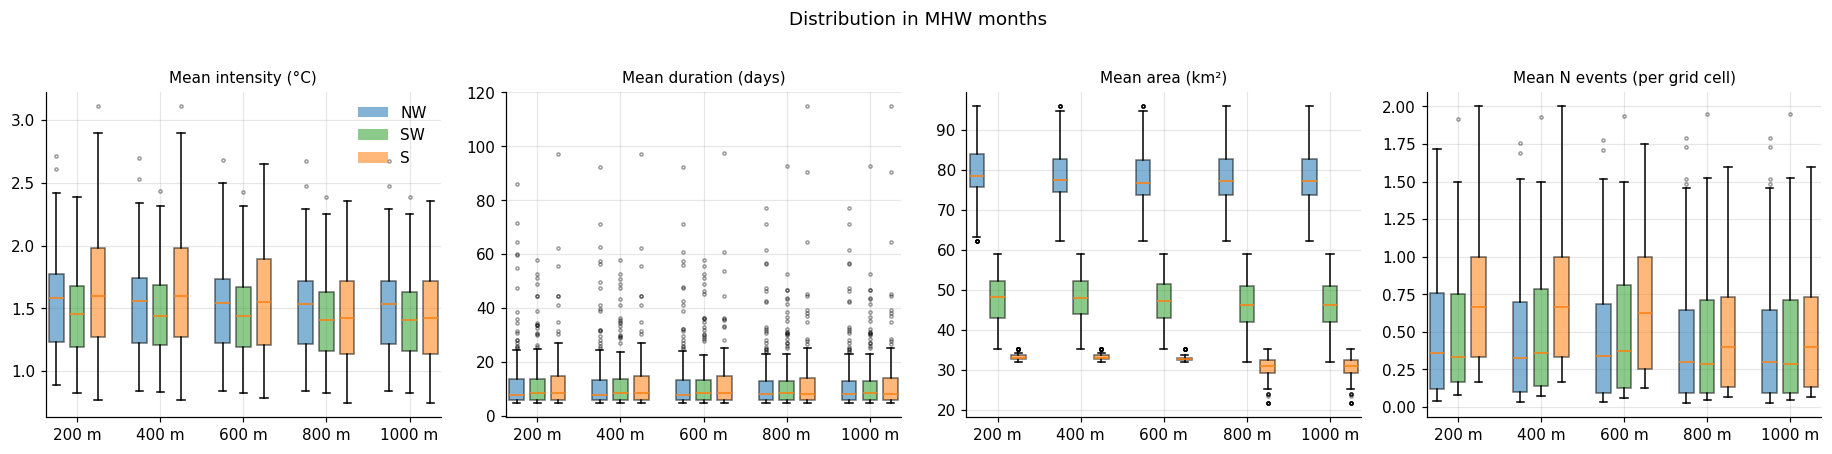

In [18]:
FIG = OUT_DIR / "figures"; FIG.mkdir(exist_ok=True)
iso_list = list(FILES)
colors = {"NW": "#1f77b4", "SW": "#2ca02c", "S": "#ff7f0e"}

# 7a. Distributions on MHW months (boxplots by zone, one panel per variable, grouped by isobath)
plot_vars = ["mean_intensity_degC", "mean_duration_days", "mean_area_km2", "mean_n_events"]
fig, axes = plt.subplots(1, len(plot_vars), figsize=(4.2*len(plot_vars), 4))
for ax, v in zip(axes, plot_vars):
    src = act if v != "mean_n_events" else df[df.onset]
    pos, data, cols, ticks = [], [], [], []
    for i, iso in enumerate(iso_list):
        for j, z in enumerate(ZONES):
            pos.append(i*(len(ZONES)+1) + j); cols.append(colors[z])
            data.append(src[(src.Isobath == iso) & (src.Zone == z)][v].dropna())
        ticks.append(i*(len(ZONES)+1) + (len(ZONES)-1)/2)
    bp = ax.boxplot(data, positions=pos, widths=.7, patch_artist=True, showfliers=True,
                    flierprops=dict(markersize=2, alpha=.4))
    for b, c in zip(bp["boxes"], cols): b.set(facecolor=c, alpha=.55)
    ax.set_xticks(ticks, [f"{i} m" for i in iso_list]); ax.set_title(VARS[v], fontsize=10)
axes[0].legend([plt.Rectangle((0,0),1,1,fc=colors[z],alpha=.55) for z in ZONES], ZONES, frameon=False)
fig.suptitle("Distribution in MHW months", y=1.02); fig.tight_layout()
fig.savefig(FIG / "boxplots_mhw_months.png", bbox_inches="tight"); plt.show()

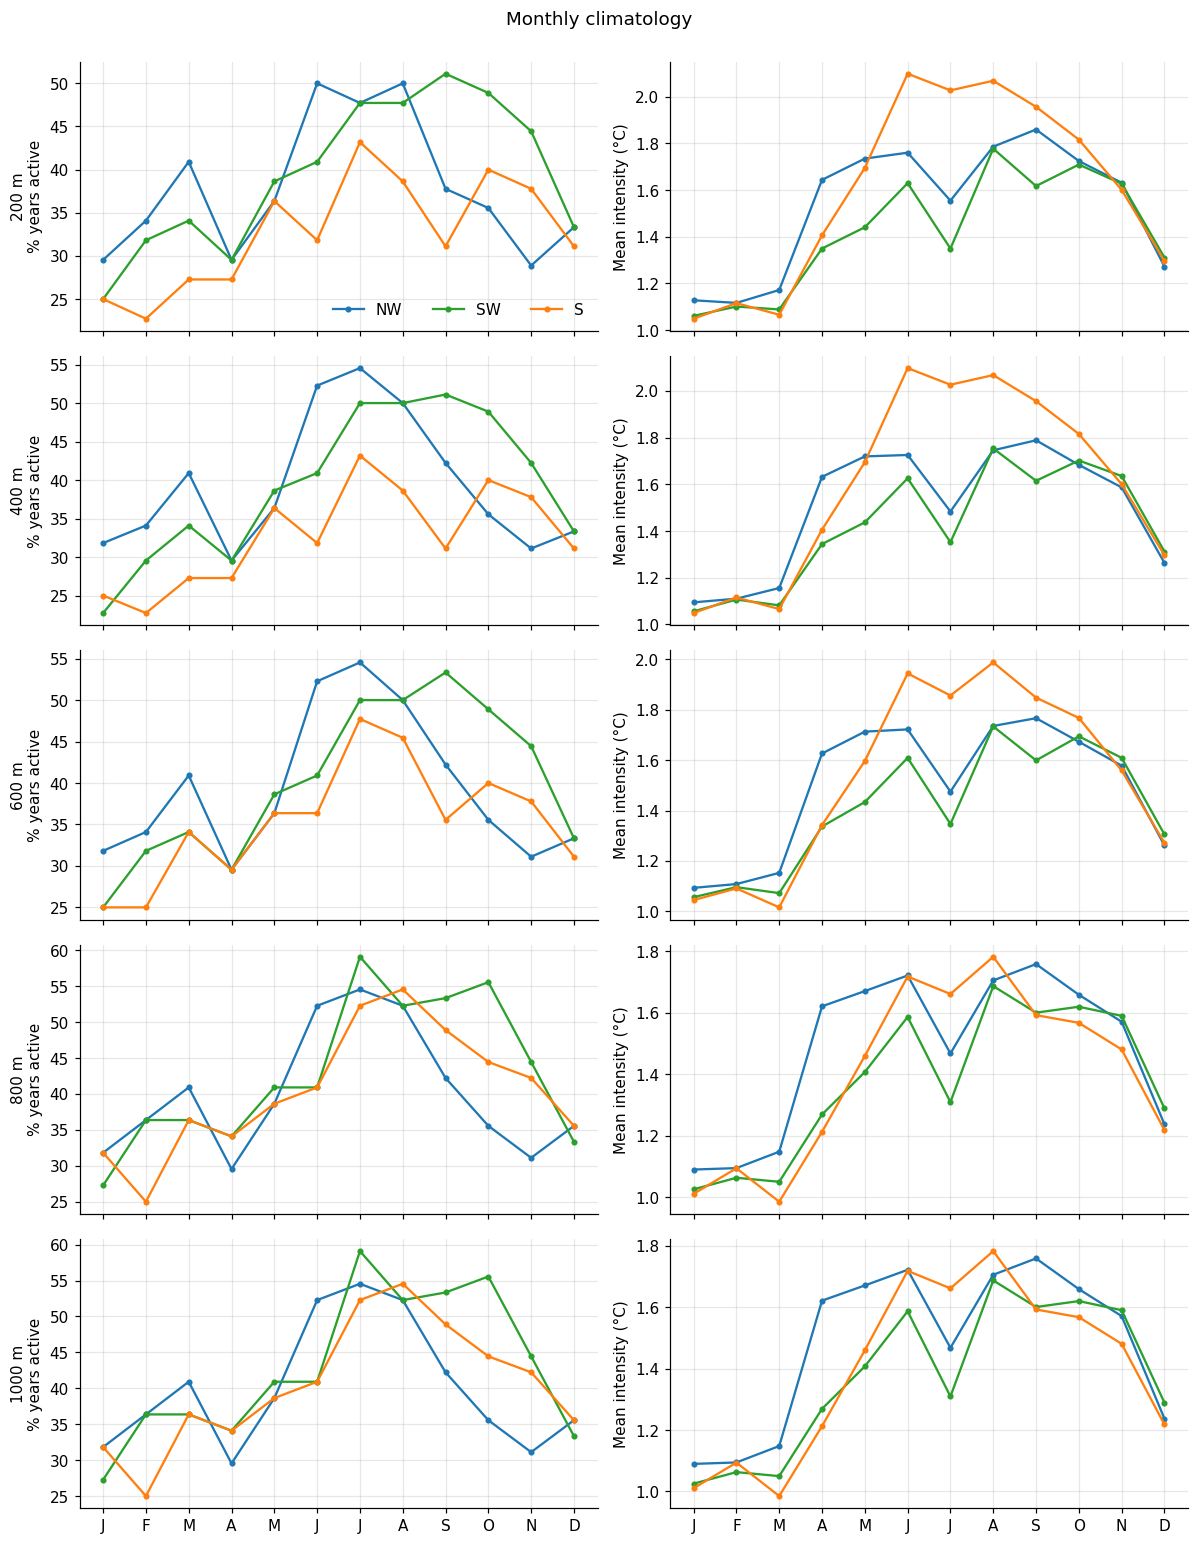

In [19]:
# 7b. Monthly climatology: % of years with MHW activity and mean intensity
fig, axes = plt.subplots(len(iso_list), 2, figsize=(11, 2.8*len(iso_list)), squeeze=False, sharex=True)
clim = df.groupby(["Isobath","Zone","Month"]).agg(pct=("active","mean"), I=("mean_intensity_degC","mean")).reset_index()
for r, iso in enumerate(iso_list):
    for z in ZONES:
        c = clim[(clim.Isobath == iso) & (clim.Zone == z)]
        axes[r,0].plot(c.Month, 100*c.pct, marker="o", ms=3, color=colors[z], label=z)
        axes[r,1].plot(c.Month, c.I, marker="o", ms=3, color=colors[z], label=z)
    axes[r,0].set_ylabel(f"{iso} m\n% years active"); axes[r,1].set_ylabel("Mean intensity (°C)")
axes[0,0].legend(frameon=False, ncol=3)
for ax in axes[-1]: ax.set_xticks(range(1,13), list("JFMAMJJASOND"))
fig.suptitle("Monthly climatology", y=1.0); fig.tight_layout()
fig.savefig(FIG / "monthly_climatology.png", bbox_inches="tight"); plt.show()

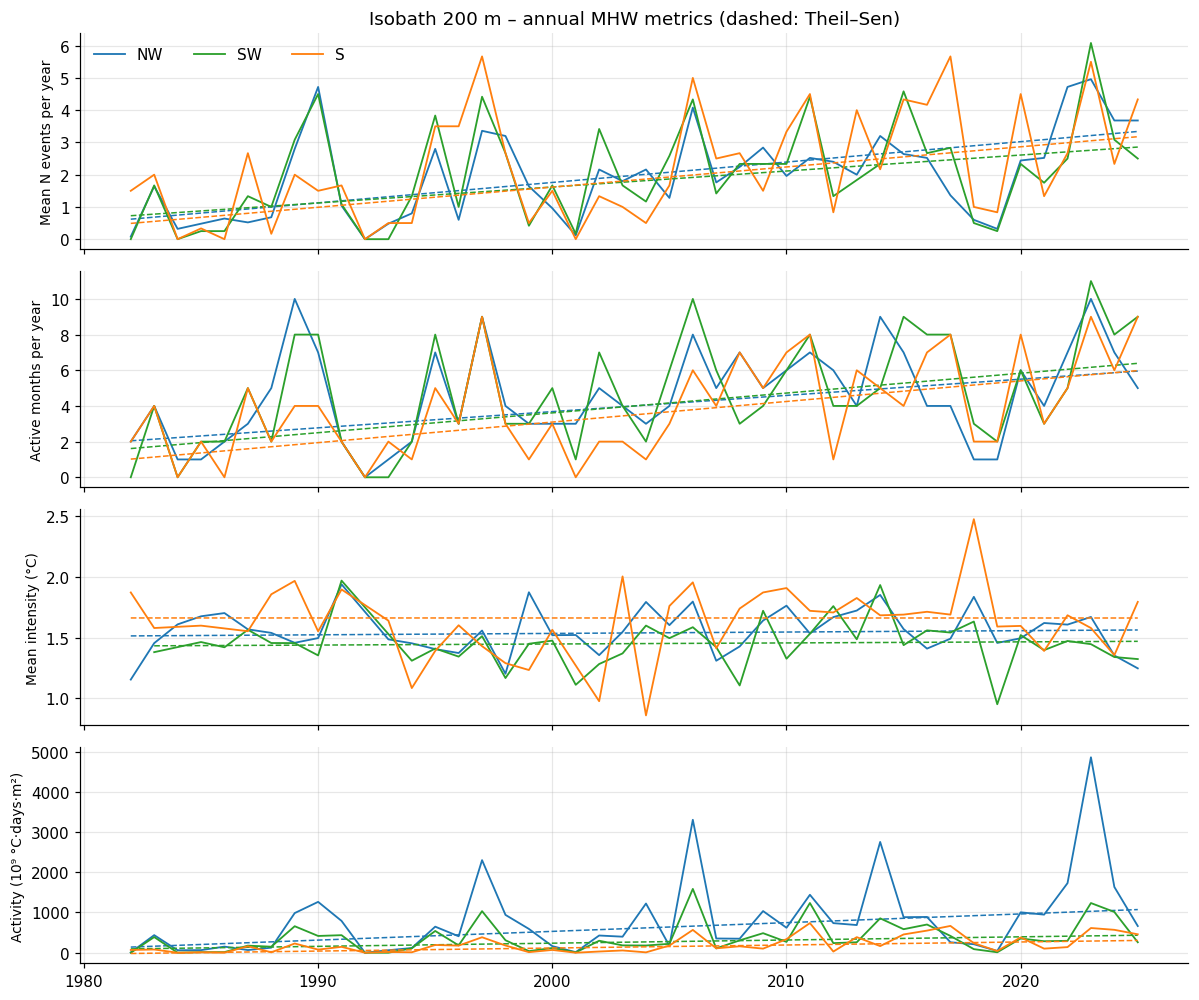

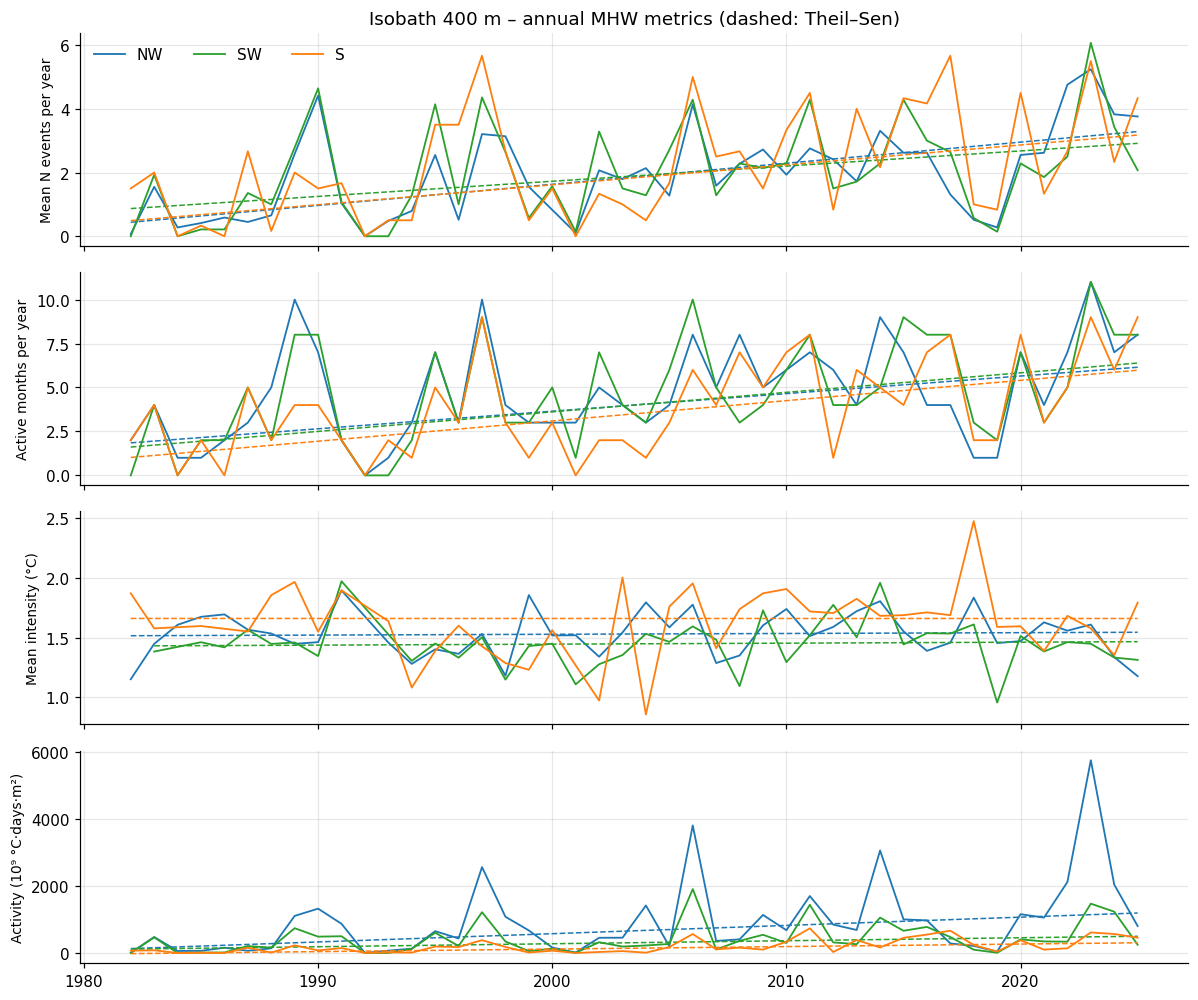

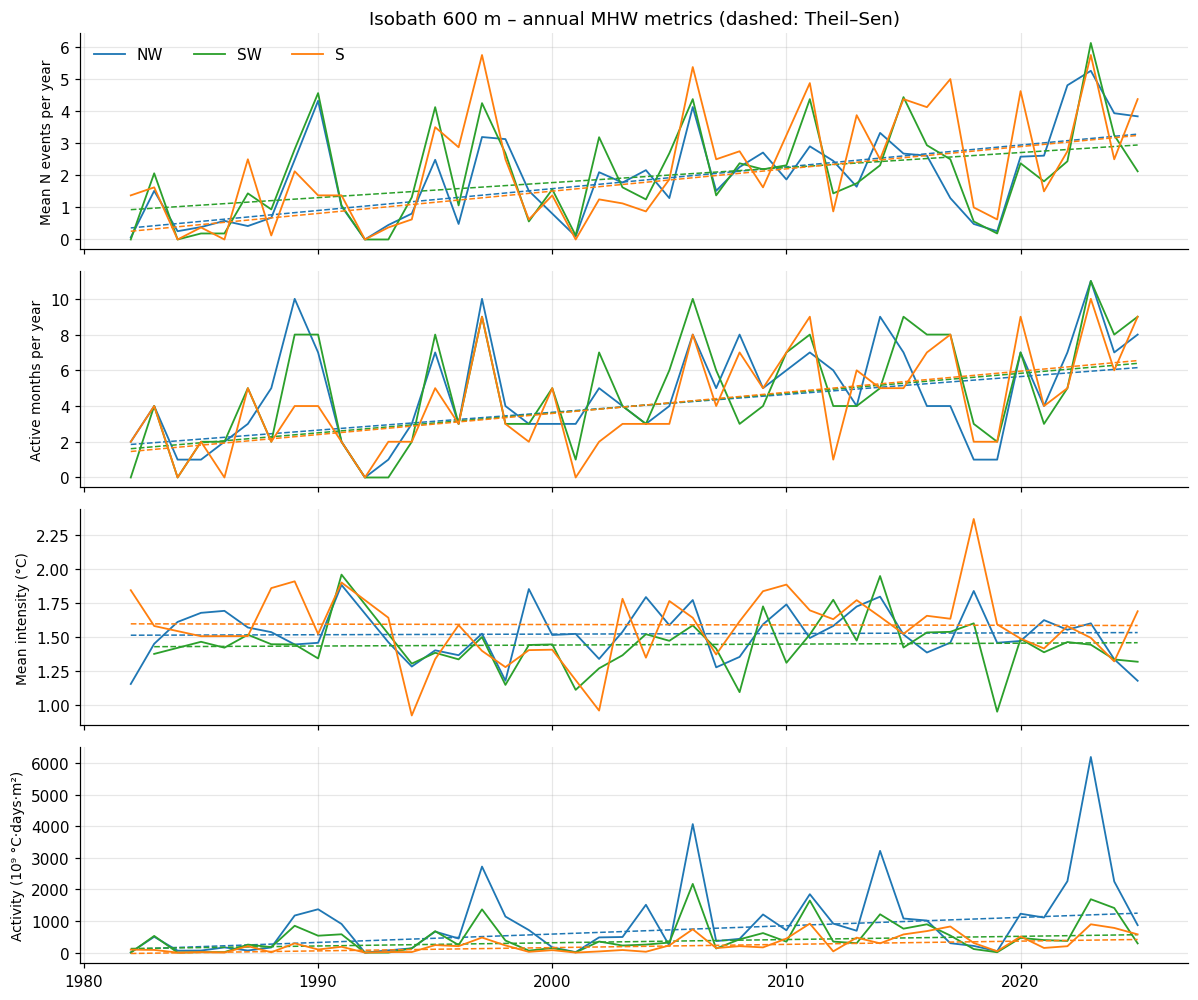

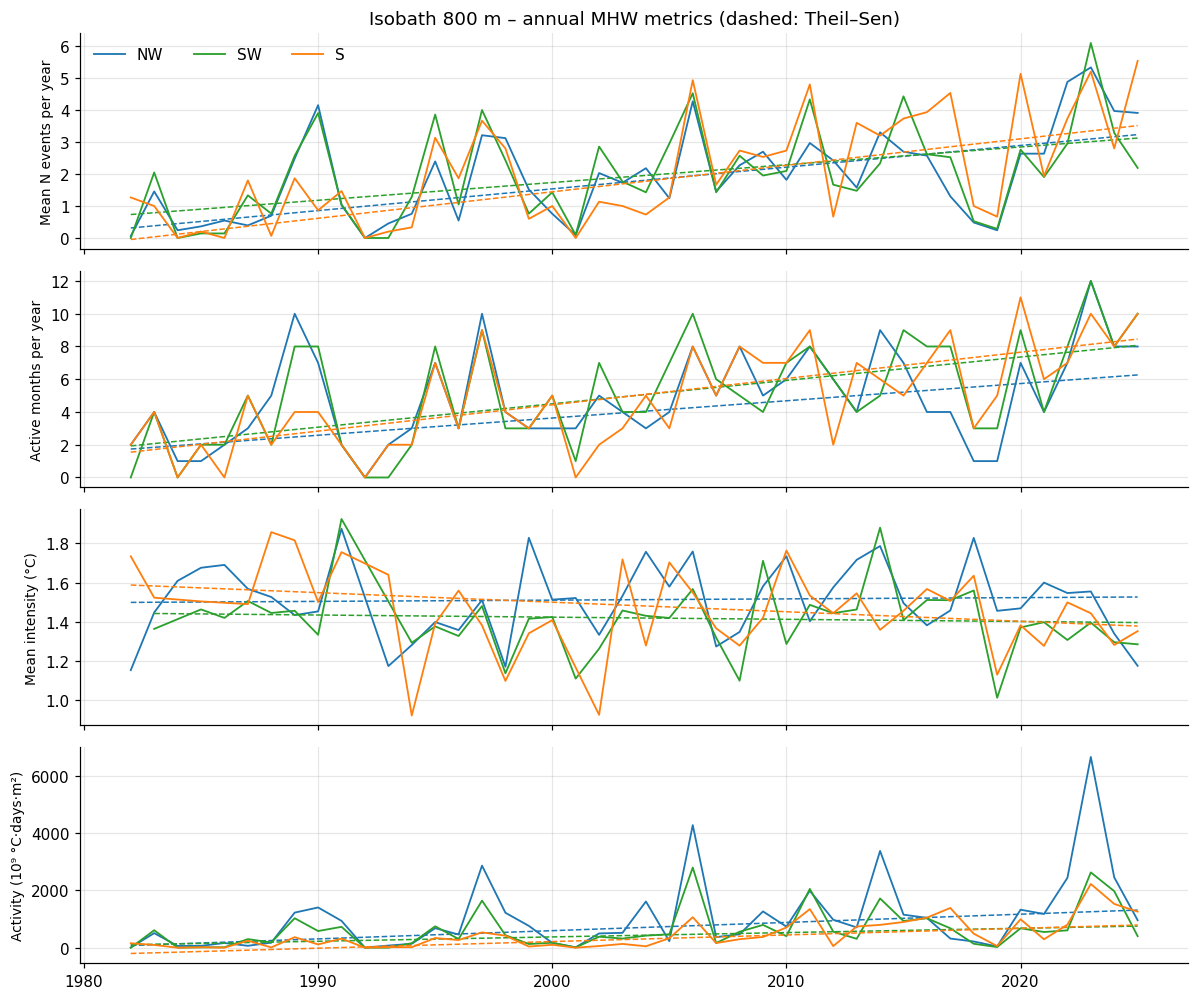

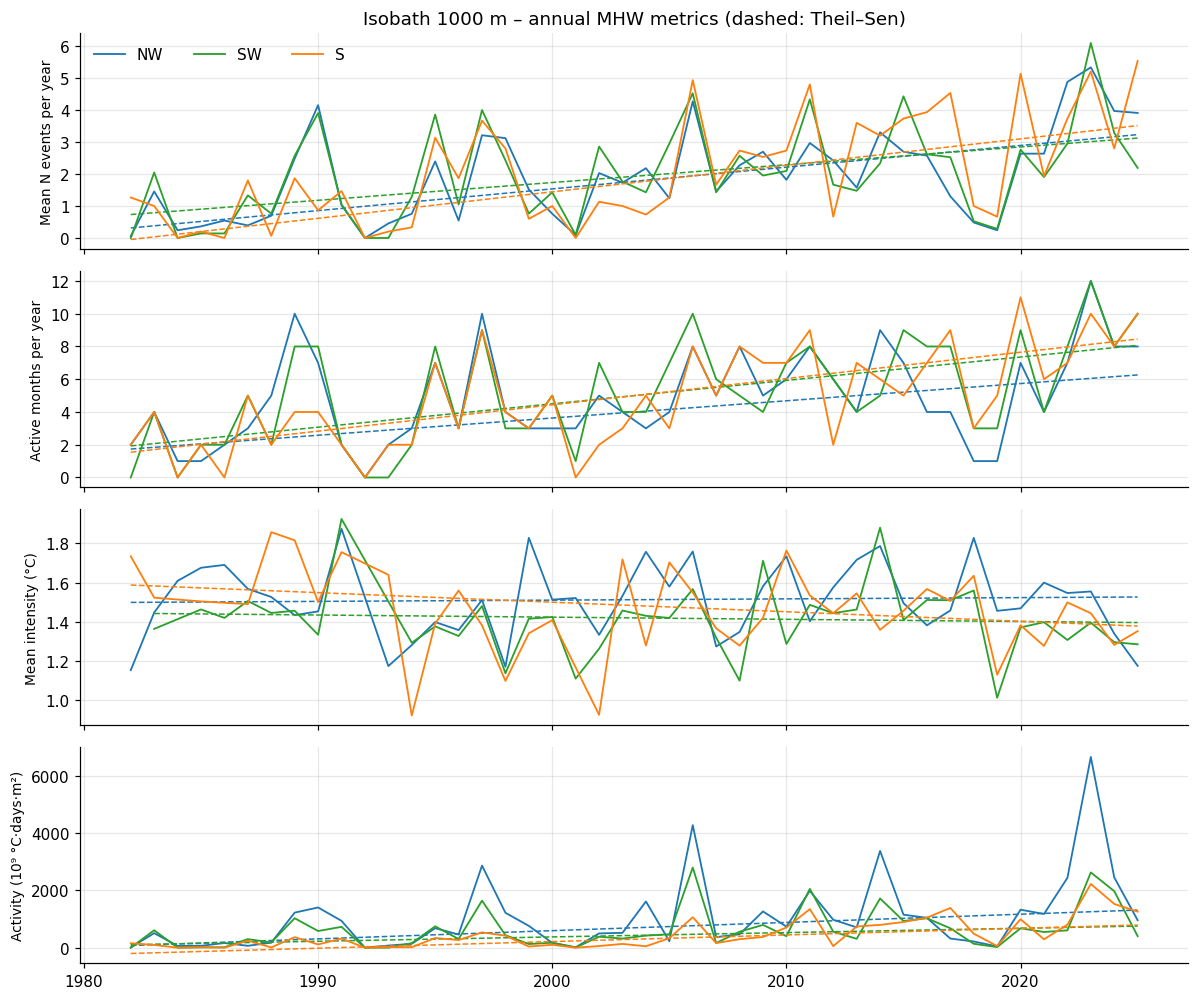

In [20]:
# 7c. Annual time series with Theil–Sen trend
show = ["mean_n_events", "active_months", "mean_intensity_degC", "activity_1e9"]
labels = {"mean_n_events": "Mean N events per year", "active_months": "Active months per year",
          "mean_intensity_degC": "Mean intensity (°C)", "activity_1e9": "Activity (10⁹ °C·days·m²)"}
for iso in iso_list:
    fig, axes = plt.subplots(len(show), 1, figsize=(11, 2.3*len(show)), sharex=True)
    for ax, v in zip(axes, show):
        for z in ZONES:
            g = annual[(annual.Isobath == iso) & (annual.Zone == z)].dropna(subset=[v])
            ax.plot(g.Year, g[v], color=colors[z], lw=1.2, label=z)
            if len(g) > 8:
                s, i, *_ = stats.theilslopes(g[v], g.Year)
                ax.plot(g.Year, i + s*g.Year, color=colors[z], ls="--", lw=1)
        ax.set_ylabel(labels[v], fontsize=9)
    axes[0].legend(frameon=False, ncol=3); axes[0].set_title(f"Isobath {iso} m – annual MHW metrics (dashed: Theil–Sen)")
    fig.tight_layout(); fig.savefig(FIG / f"annual_timeseries_{iso}m.png", bbox_inches="tight"); plt.show()

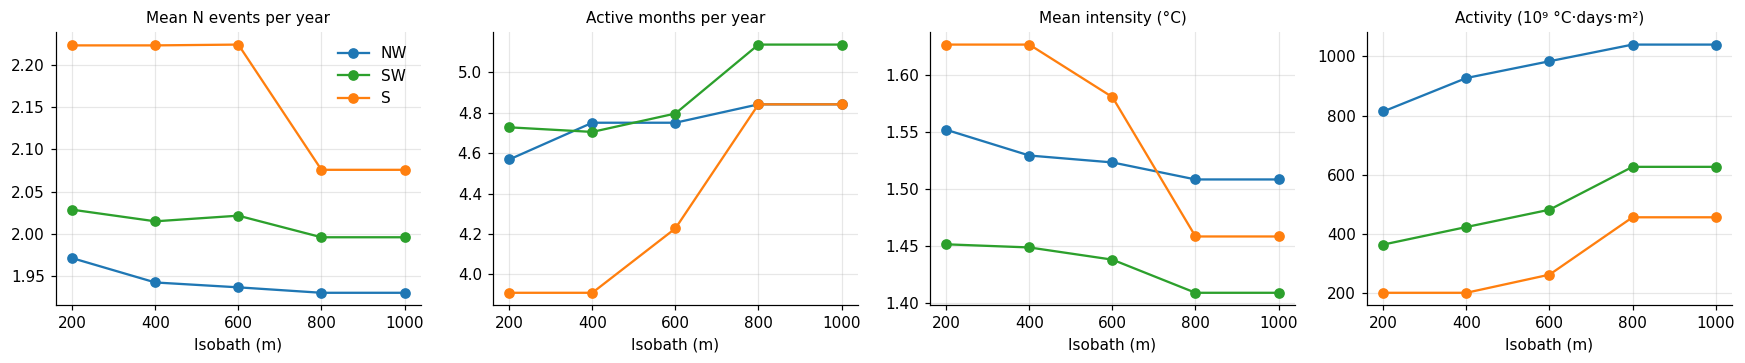

In [21]:
# 7d. Isobath comparison of annual means (only meaningful with >1 isobath)
if len(iso_list) > 1:
    m = annual.groupby(["Isobath","Zone"])[show].mean().reset_index()
    fig, axes = plt.subplots(1, len(show), figsize=(4*len(show), 3.4))
    for ax, v in zip(axes, show):
        for z in ZONES:
            g = m[m.Zone == z]; ax.plot(g.Isobath, g[v], marker="o", color=colors[z], label=z)
        ax.set_xlabel("Isobath (m)"); ax.set_title(labels[v], fontsize=10); ax.set_xticks(iso_list)
    axes[0].legend(frameon=False); fig.tight_layout()
    fig.savefig(FIG / "isobath_comparison.png", bbox_inches="tight"); plt.show()
else:
    print("Only one isobath loaded – add the 400/600/800/1000 m files to compare.")

### 7e. Mean ± SD and median of the descriptive statistics (MHW months)

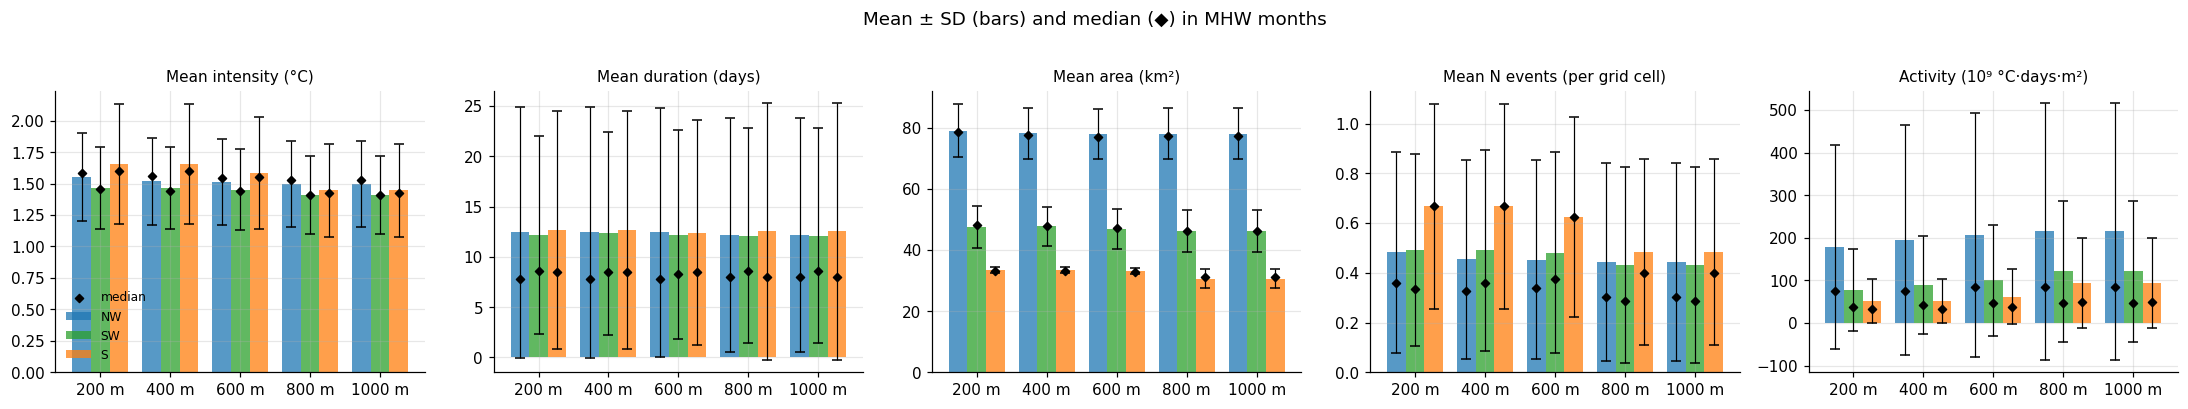

In [22]:
bar_vars = ["mean_intensity_degC", "mean_duration_days", "mean_area_km2", "mean_n_events", "activity_1e9"]
bar_lab  = {**VARS, "activity_1e9": "Activity (10⁹ °C·days·m²)"}
fig, axes = plt.subplots(1, len(bar_vars), figsize=(4*len(bar_vars), 3.6))
w = 0.8 / len(ZONES)
for ax, v in zip(axes, bar_vars):
    src = df[df.onset] if v == "mean_n_events" else act
    for j, z in enumerate(ZONES):
        g = src[src.Zone == z].groupby("Isobath")[v]
        mu, sd, med = g.mean().reindex(iso_list), g.std().reindex(iso_list), g.median().reindex(iso_list)
        x = np.arange(len(iso_list)) + (j - (len(ZONES)-1)/2) * w
        ax.bar(x, mu, w, yerr=sd, capsize=3, color=colors[z], alpha=.75, label=z, error_kw=dict(lw=.8))
        ax.scatter(x, med, marker="D", s=14, color="k", zorder=3, label="median" if j == 0 else None)
    ax.set_xticks(range(len(iso_list)), [f"{i} m" for i in iso_list]); ax.set_title(bar_lab[v], fontsize=10)
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("Mean ± SD (bars) and median (◆) in MHW months", y=1.02); fig.tight_layout()
fig.savefig(FIG / "mean_sd_bars.png", bbox_inches="tight"); plt.show()

### 7f. Histograms (MHW months)

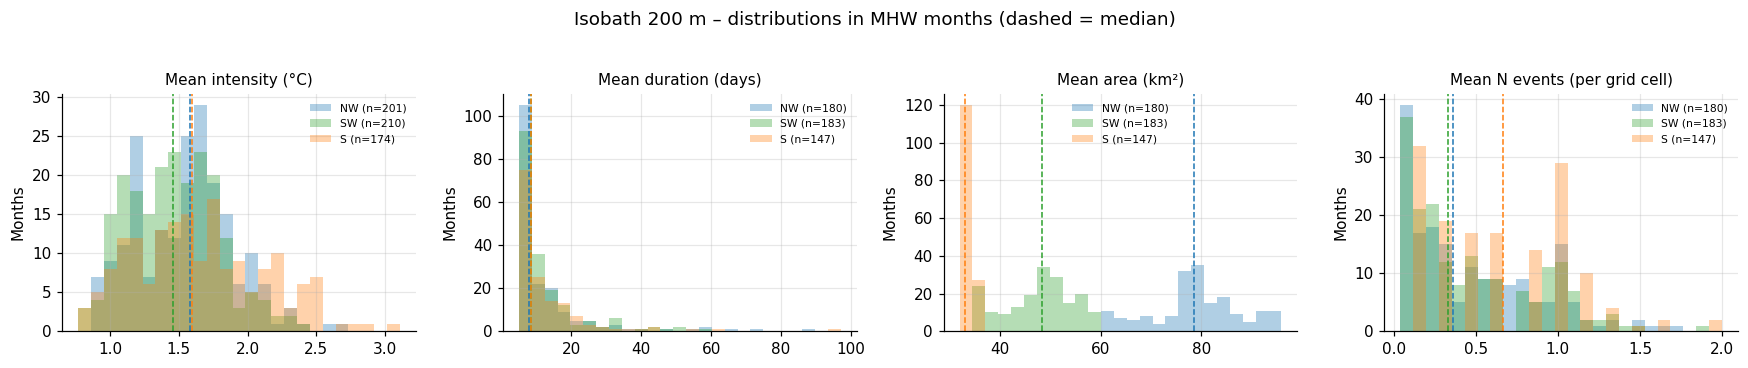

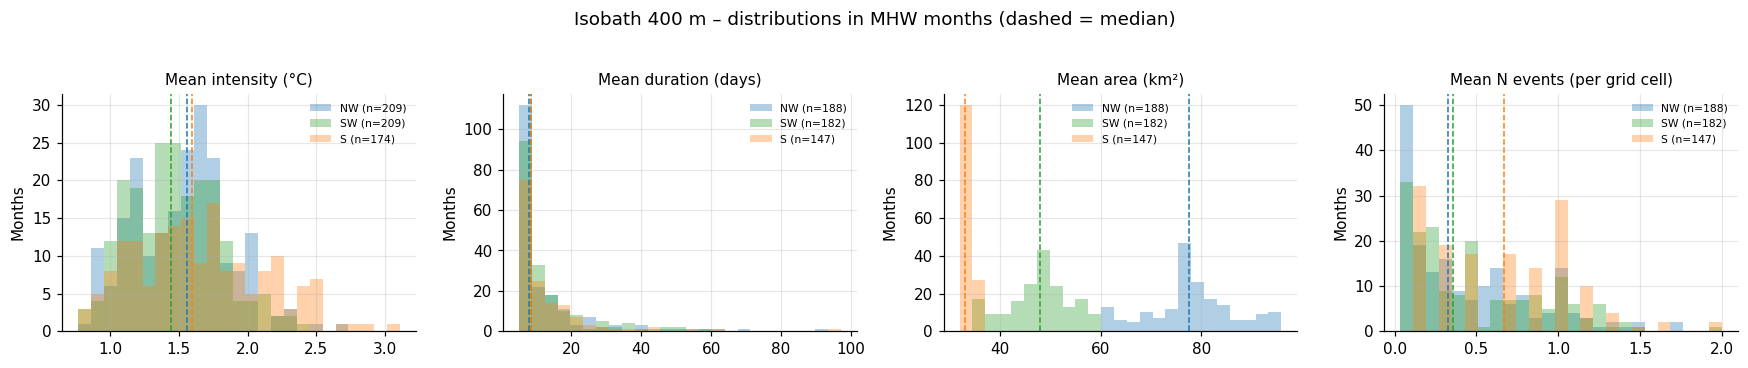

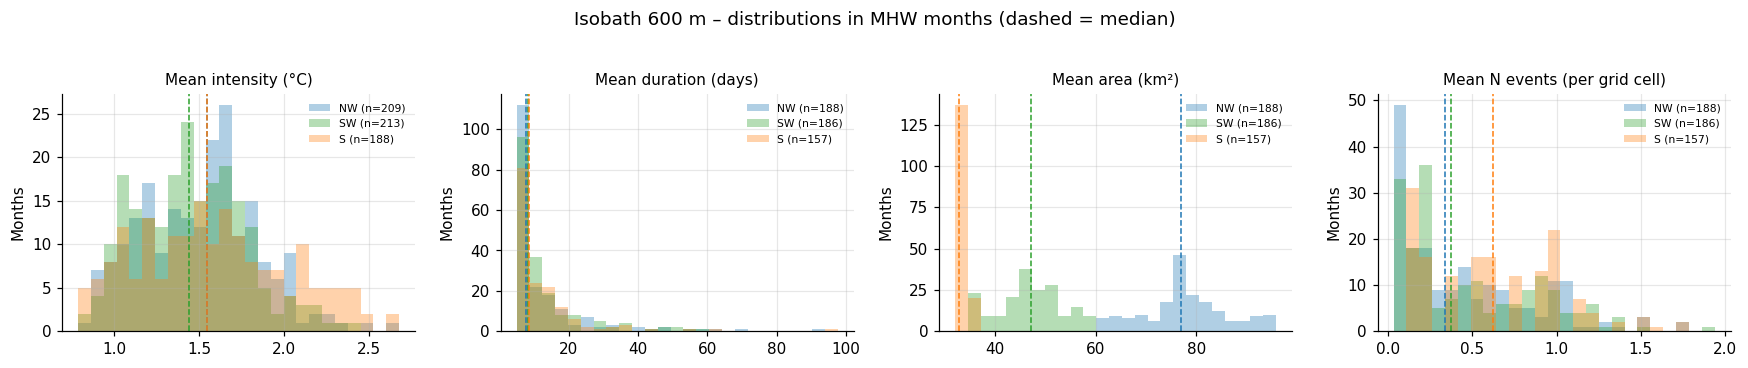

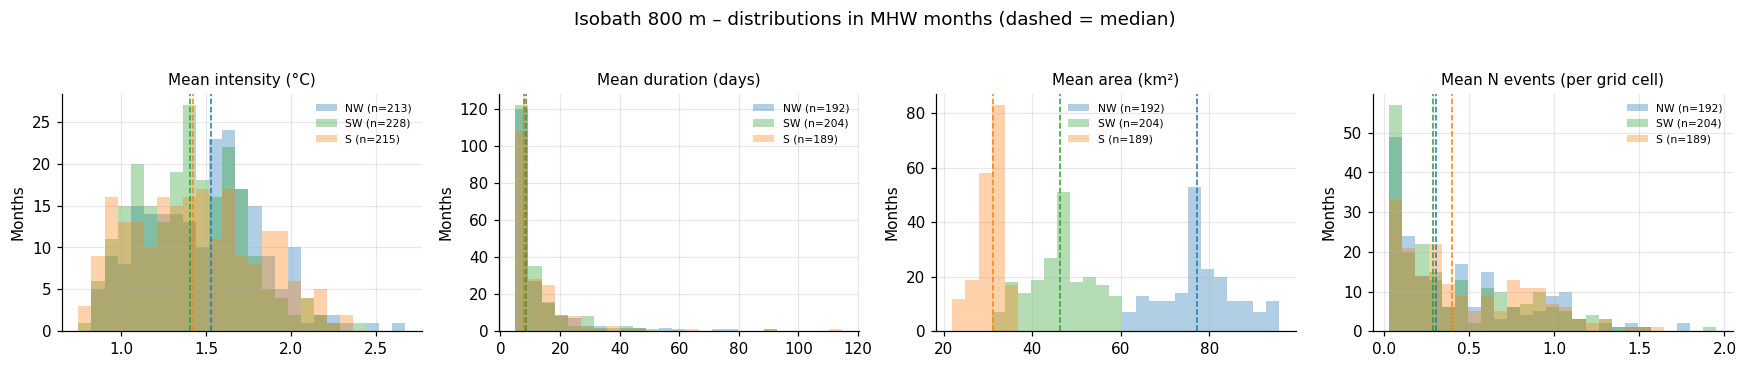

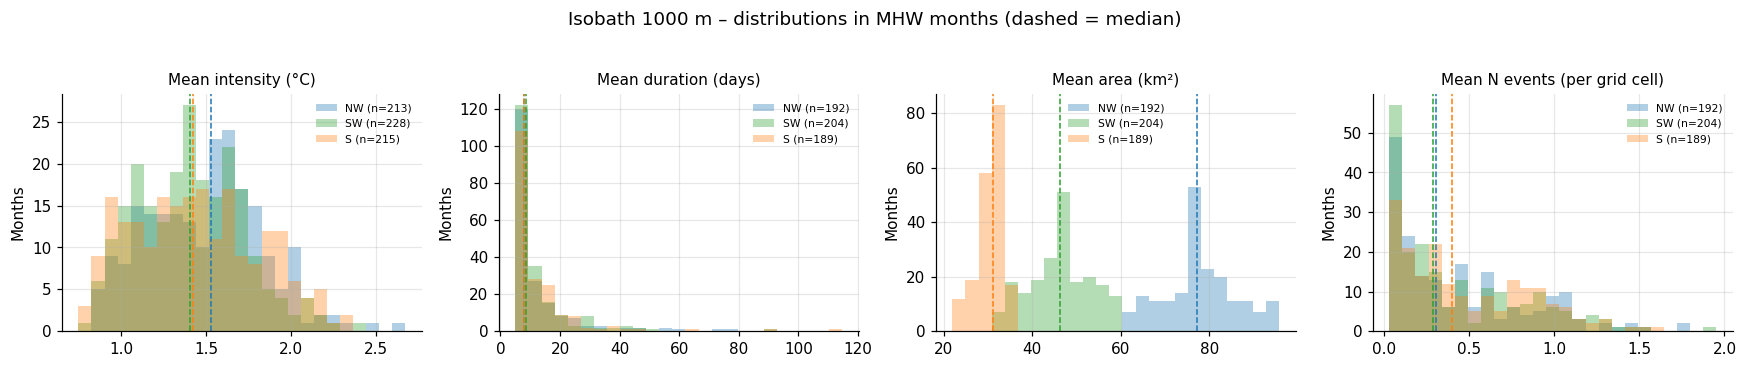

In [23]:
hist_vars = ["mean_intensity_degC", "mean_duration_days", "mean_area_km2", "mean_n_events"]
for iso in iso_list:
    fig, axes = plt.subplots(1, len(hist_vars), figsize=(4*len(hist_vars), 3.2))
    a = act[act.Isobath == iso]
    for ax, v in zip(axes, hist_vars):
        src = a[a.onset] if v == "mean_n_events" else a
        allv = src[v].dropna()
        bins = np.histogram_bin_edges(allv, bins=25)
        for z in ZONES:
            s = src[src.Zone == z][v].dropna()
            ax.hist(s, bins=bins, histtype="stepfilled", alpha=.35, color=colors[z], label=f"{z} (n={len(s)})")
            ax.axvline(s.median(), color=colors[z], ls="--", lw=1)
        ax.set_title(VARS[v], fontsize=10); ax.set_ylabel("Months")
        ax.legend(frameon=False, fontsize=7)
    fig.suptitle(f"Isobath {iso} m – distributions in MHW months (dashed = median)", y=1.03); fig.tight_layout()
    fig.savefig(FIG / f"histograms_{iso}m.png", bbox_inches="tight"); plt.show()

### 7g. Year × month heatmaps
MHW activity (log scale) and mean intensity for every month of the record.

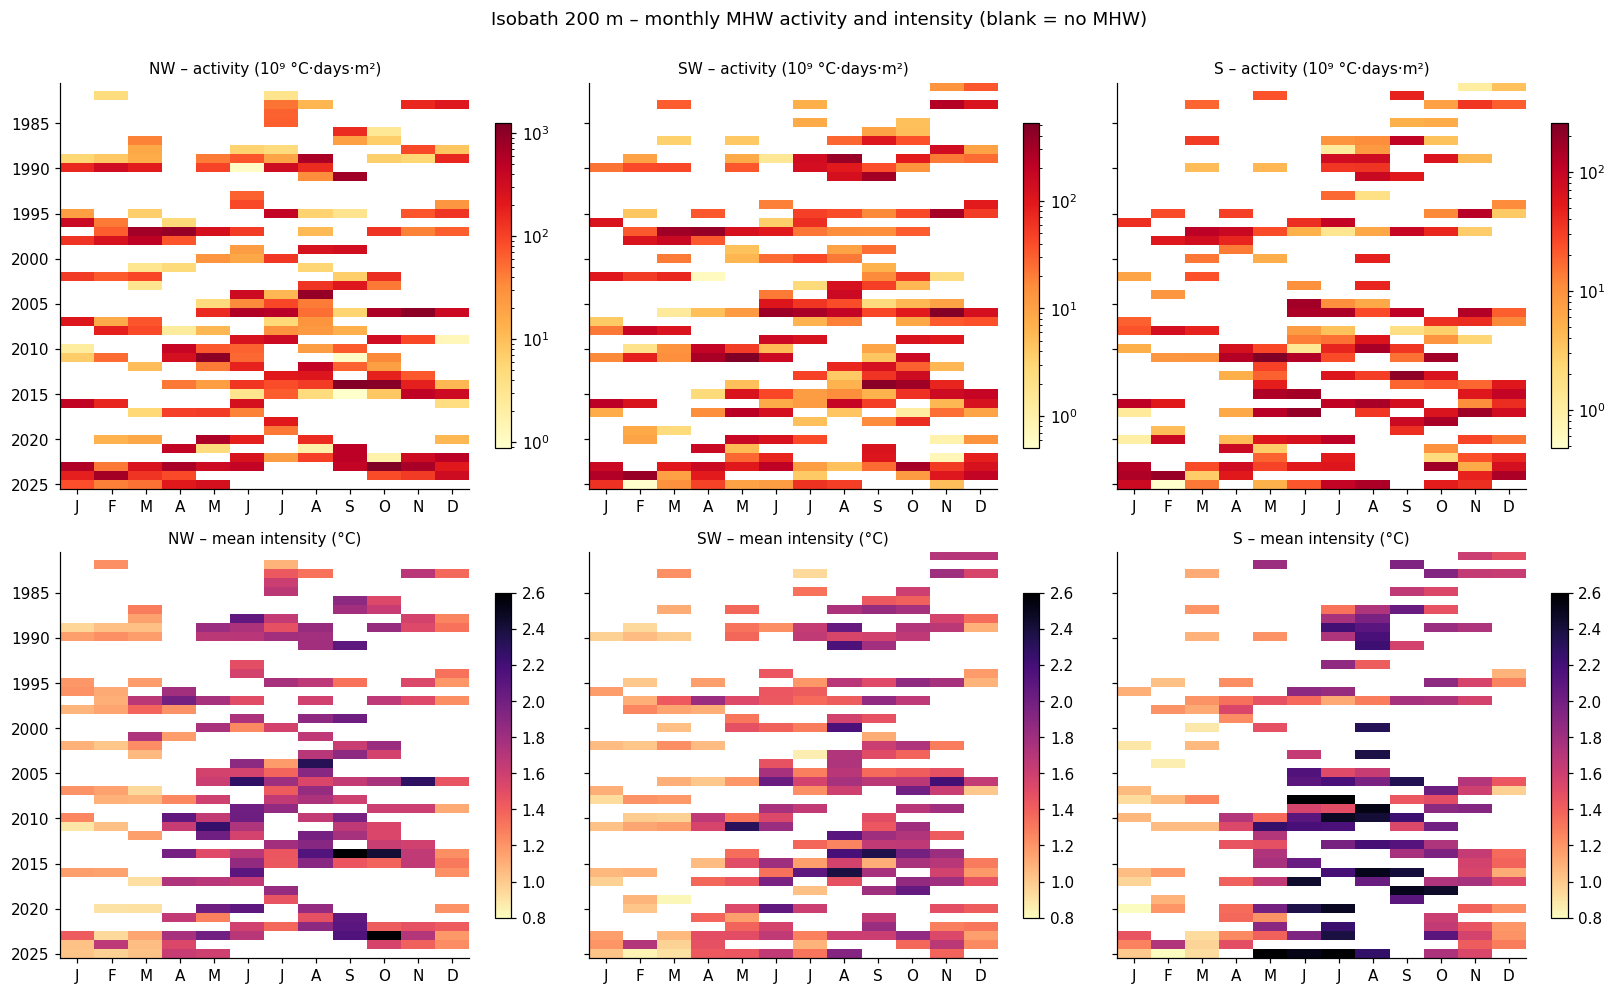

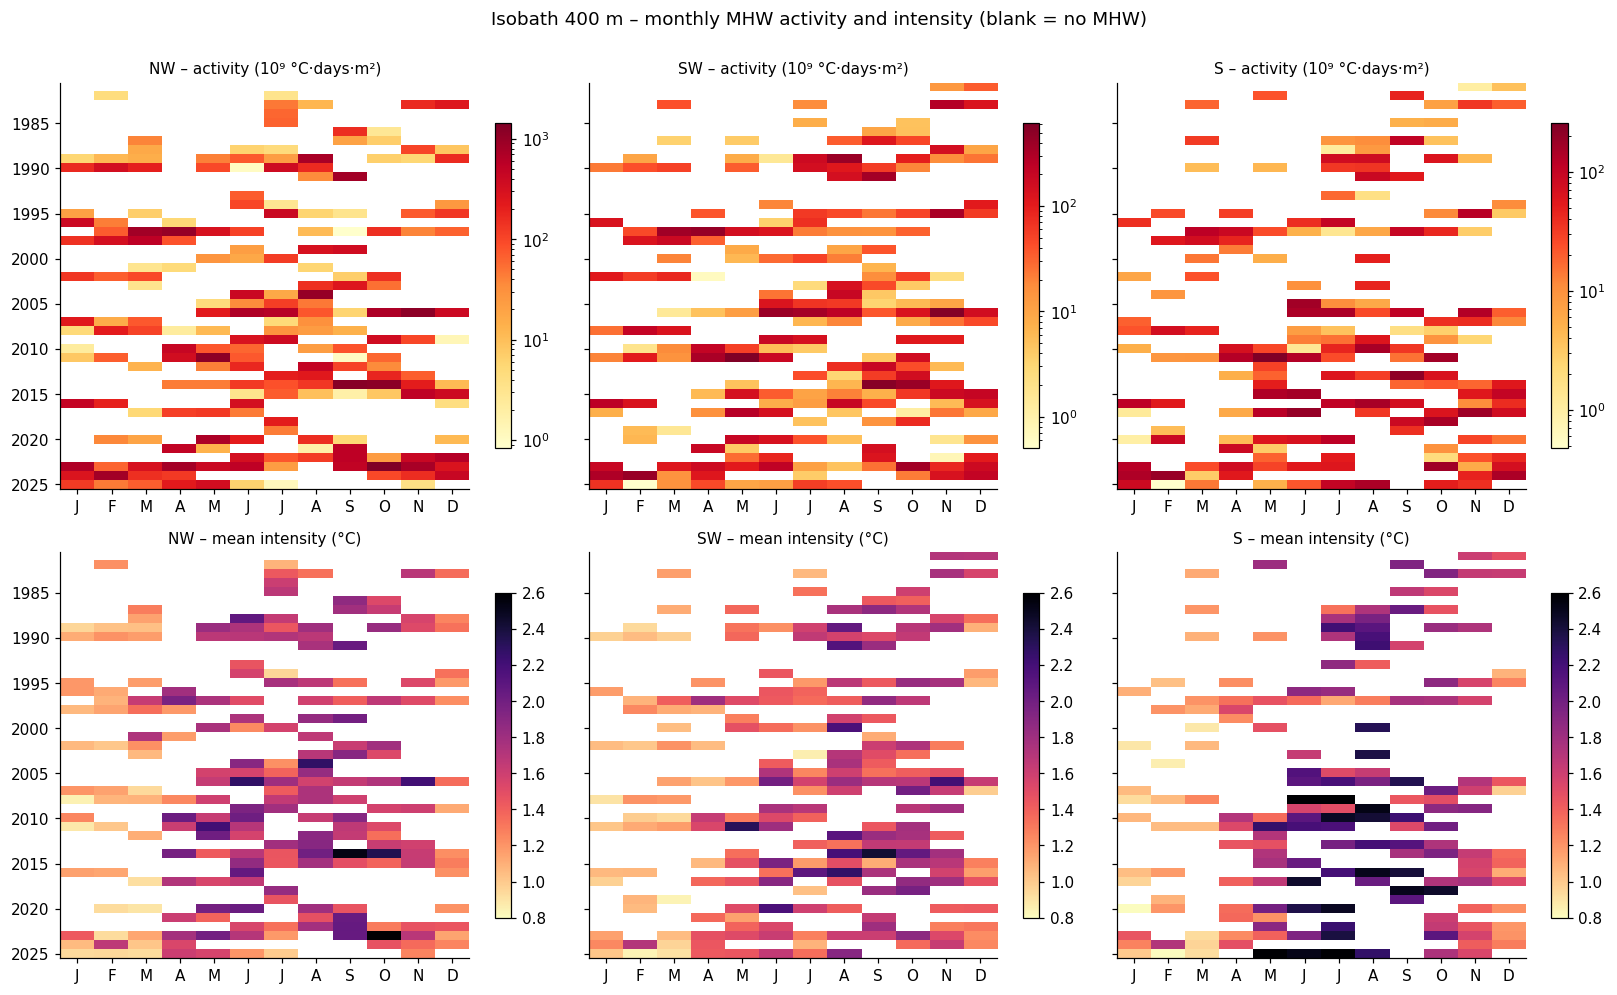

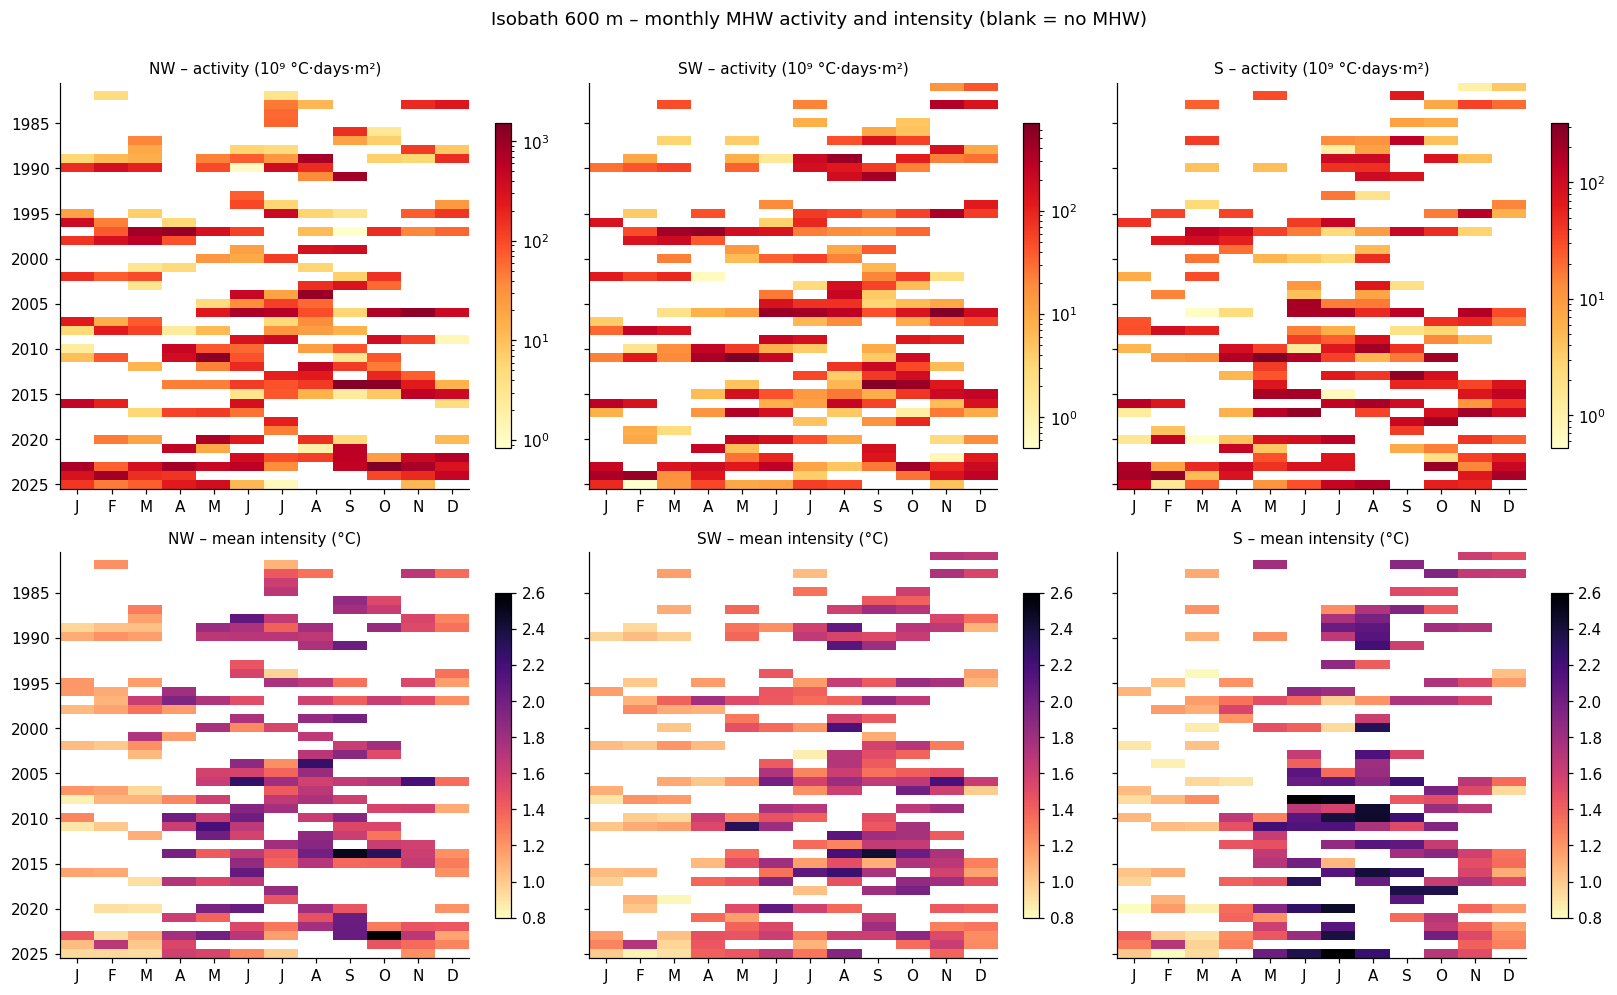

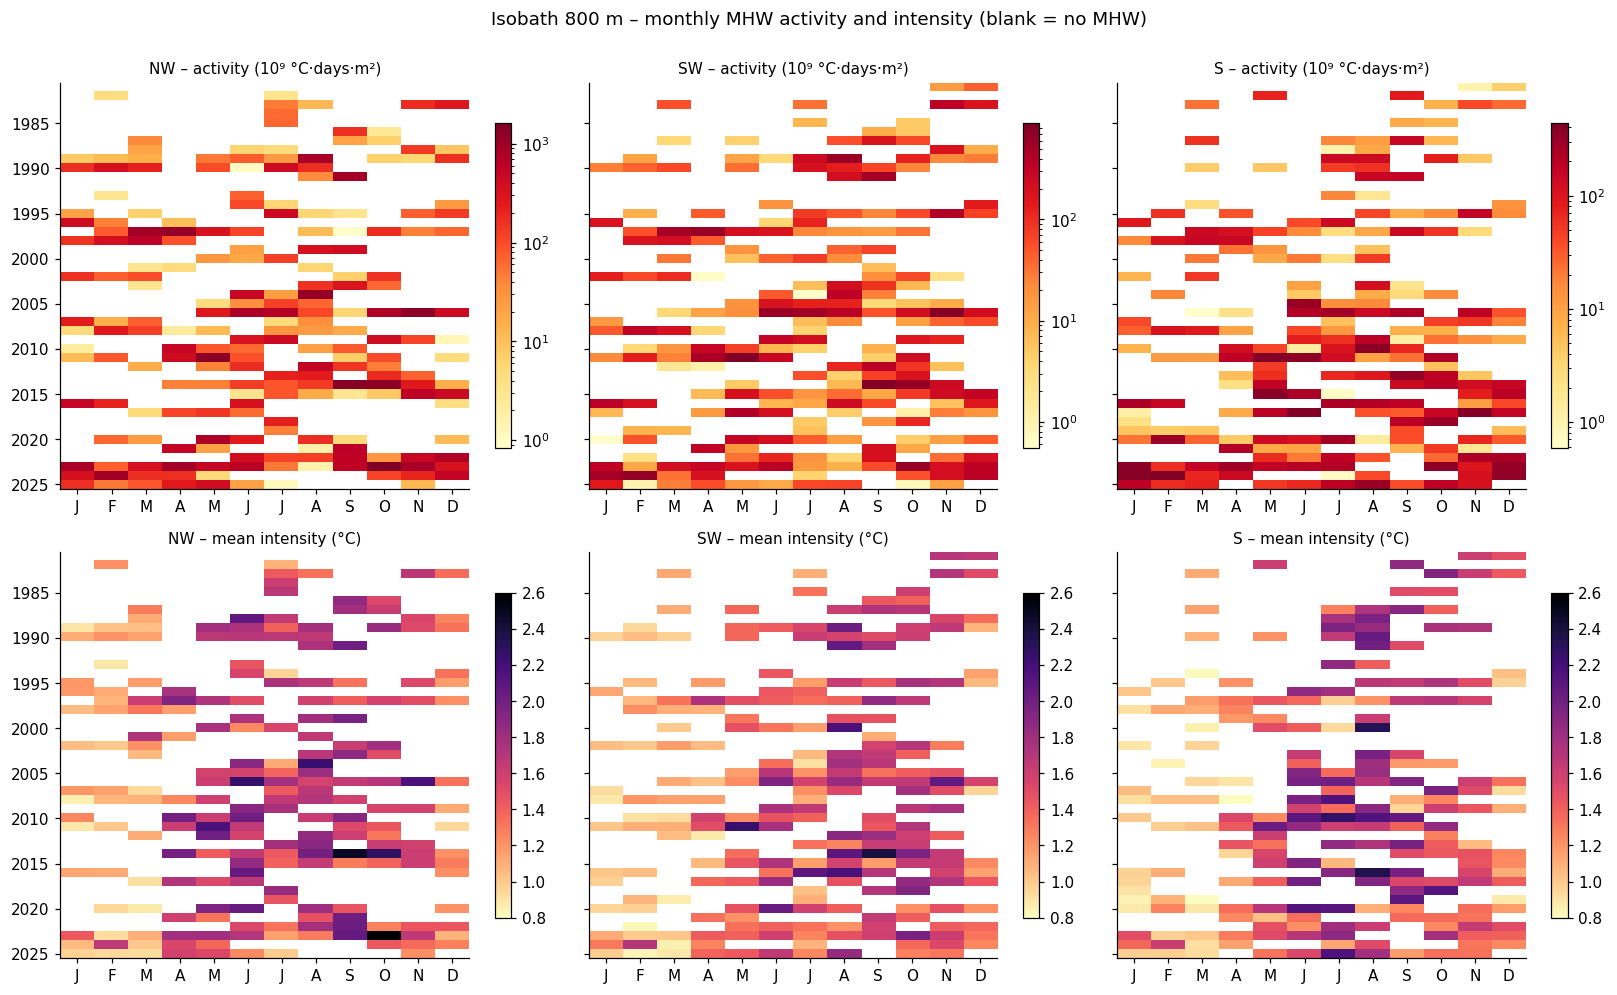

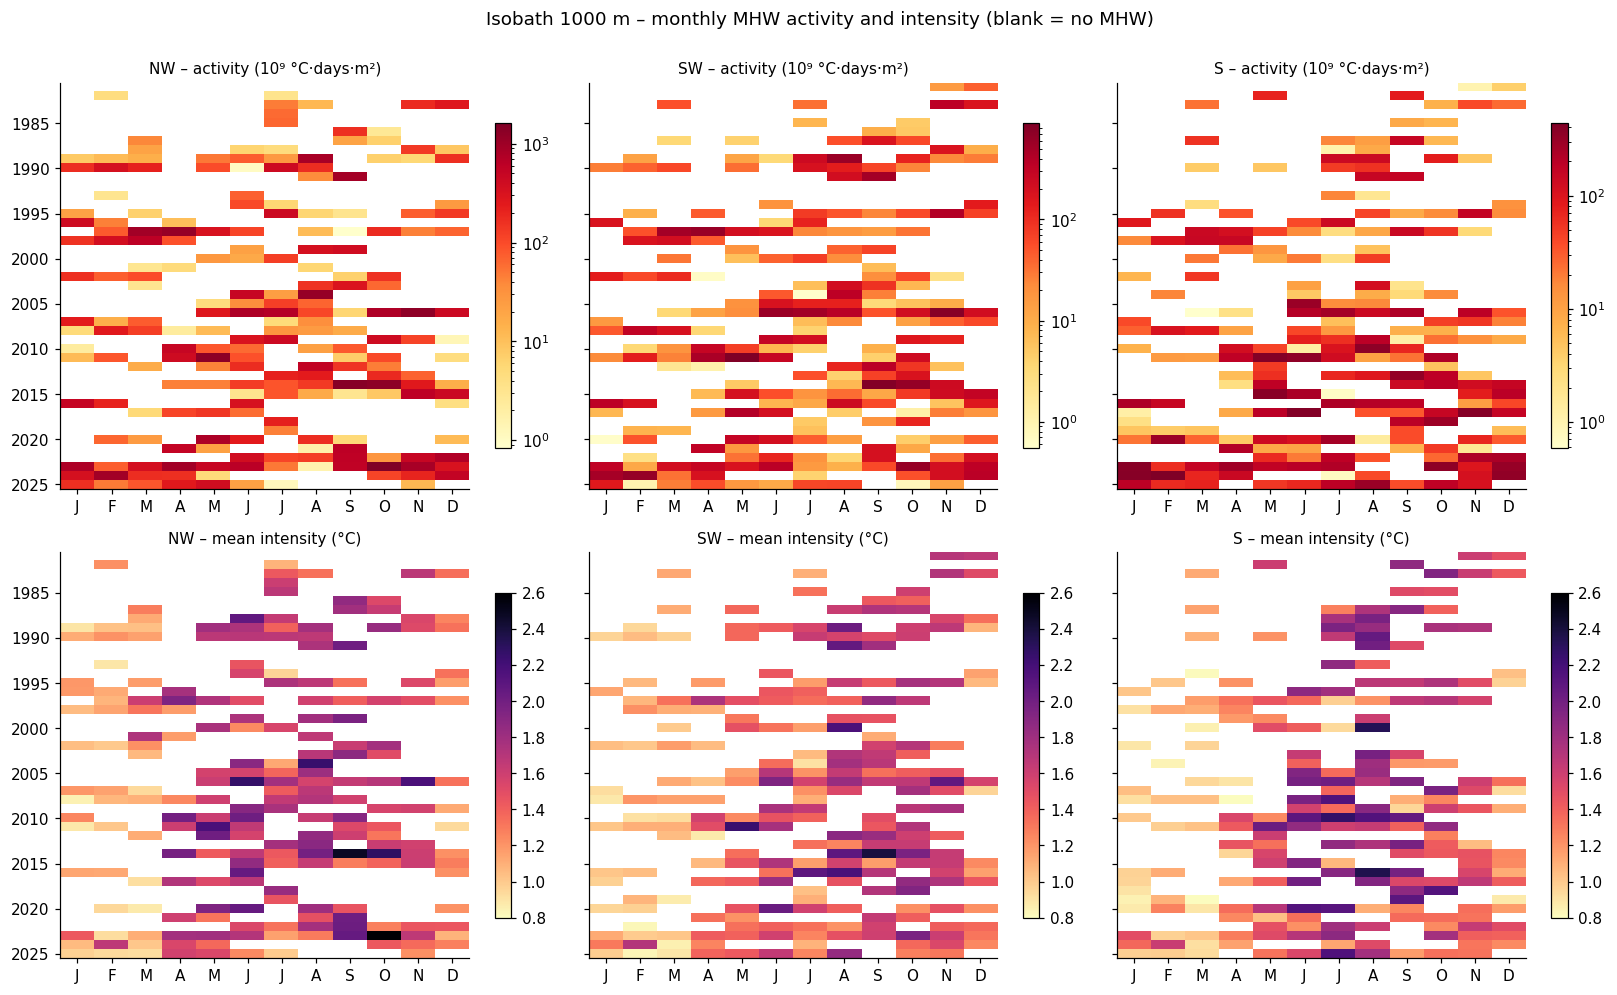

In [24]:
from matplotlib.colors import LogNorm
for iso in iso_list:
    fig, axes = plt.subplots(2, len(ZONES), figsize=(5*len(ZONES), 9), sharey=True)
    for j, z in enumerate(ZONES):
        g = df[(df.Isobath == iso) & (df.Zone == z)]
        A = g.pivot(index="Year", columns="Month", values="activity_1e9").replace(0, np.nan)
        I = g.pivot(index="Year", columns="Month", values="mean_intensity_degC")
        im0 = axes[0, j].imshow(A, aspect="auto", cmap="YlOrRd", norm=LogNorm(),
                                extent=[.5, 12.5, A.index.max()+.5, A.index.min()-.5])
        im1 = axes[1, j].imshow(I, aspect="auto", cmap="magma_r", vmin=.8, vmax=2.6,
                                extent=[.5, 12.5, I.index.max()+.5, I.index.min()-.5])
        axes[0, j].set_title(f"{z} – activity (10⁹ °C·days·m²)", fontsize=10)
        axes[1, j].set_title(f"{z} – mean intensity (°C)", fontsize=10)
        for ax in axes[:, j]:
            ax.set_xticks(range(1, 13), list("JFMAMJJASOND")); ax.grid(False)
        fig.colorbar(im0, ax=axes[0, j], shrink=.8); fig.colorbar(im1, ax=axes[1, j], shrink=.8)
    fig.suptitle(f"Isobath {iso} m – monthly MHW activity and intensity (blank = no MHW)", y=1.0)
    fig.tight_layout(); fig.savefig(FIG / f"heatmap_year_month_{iso}m.png", bbox_inches="tight"); plt.show()

### 7h. Seasonal statistics

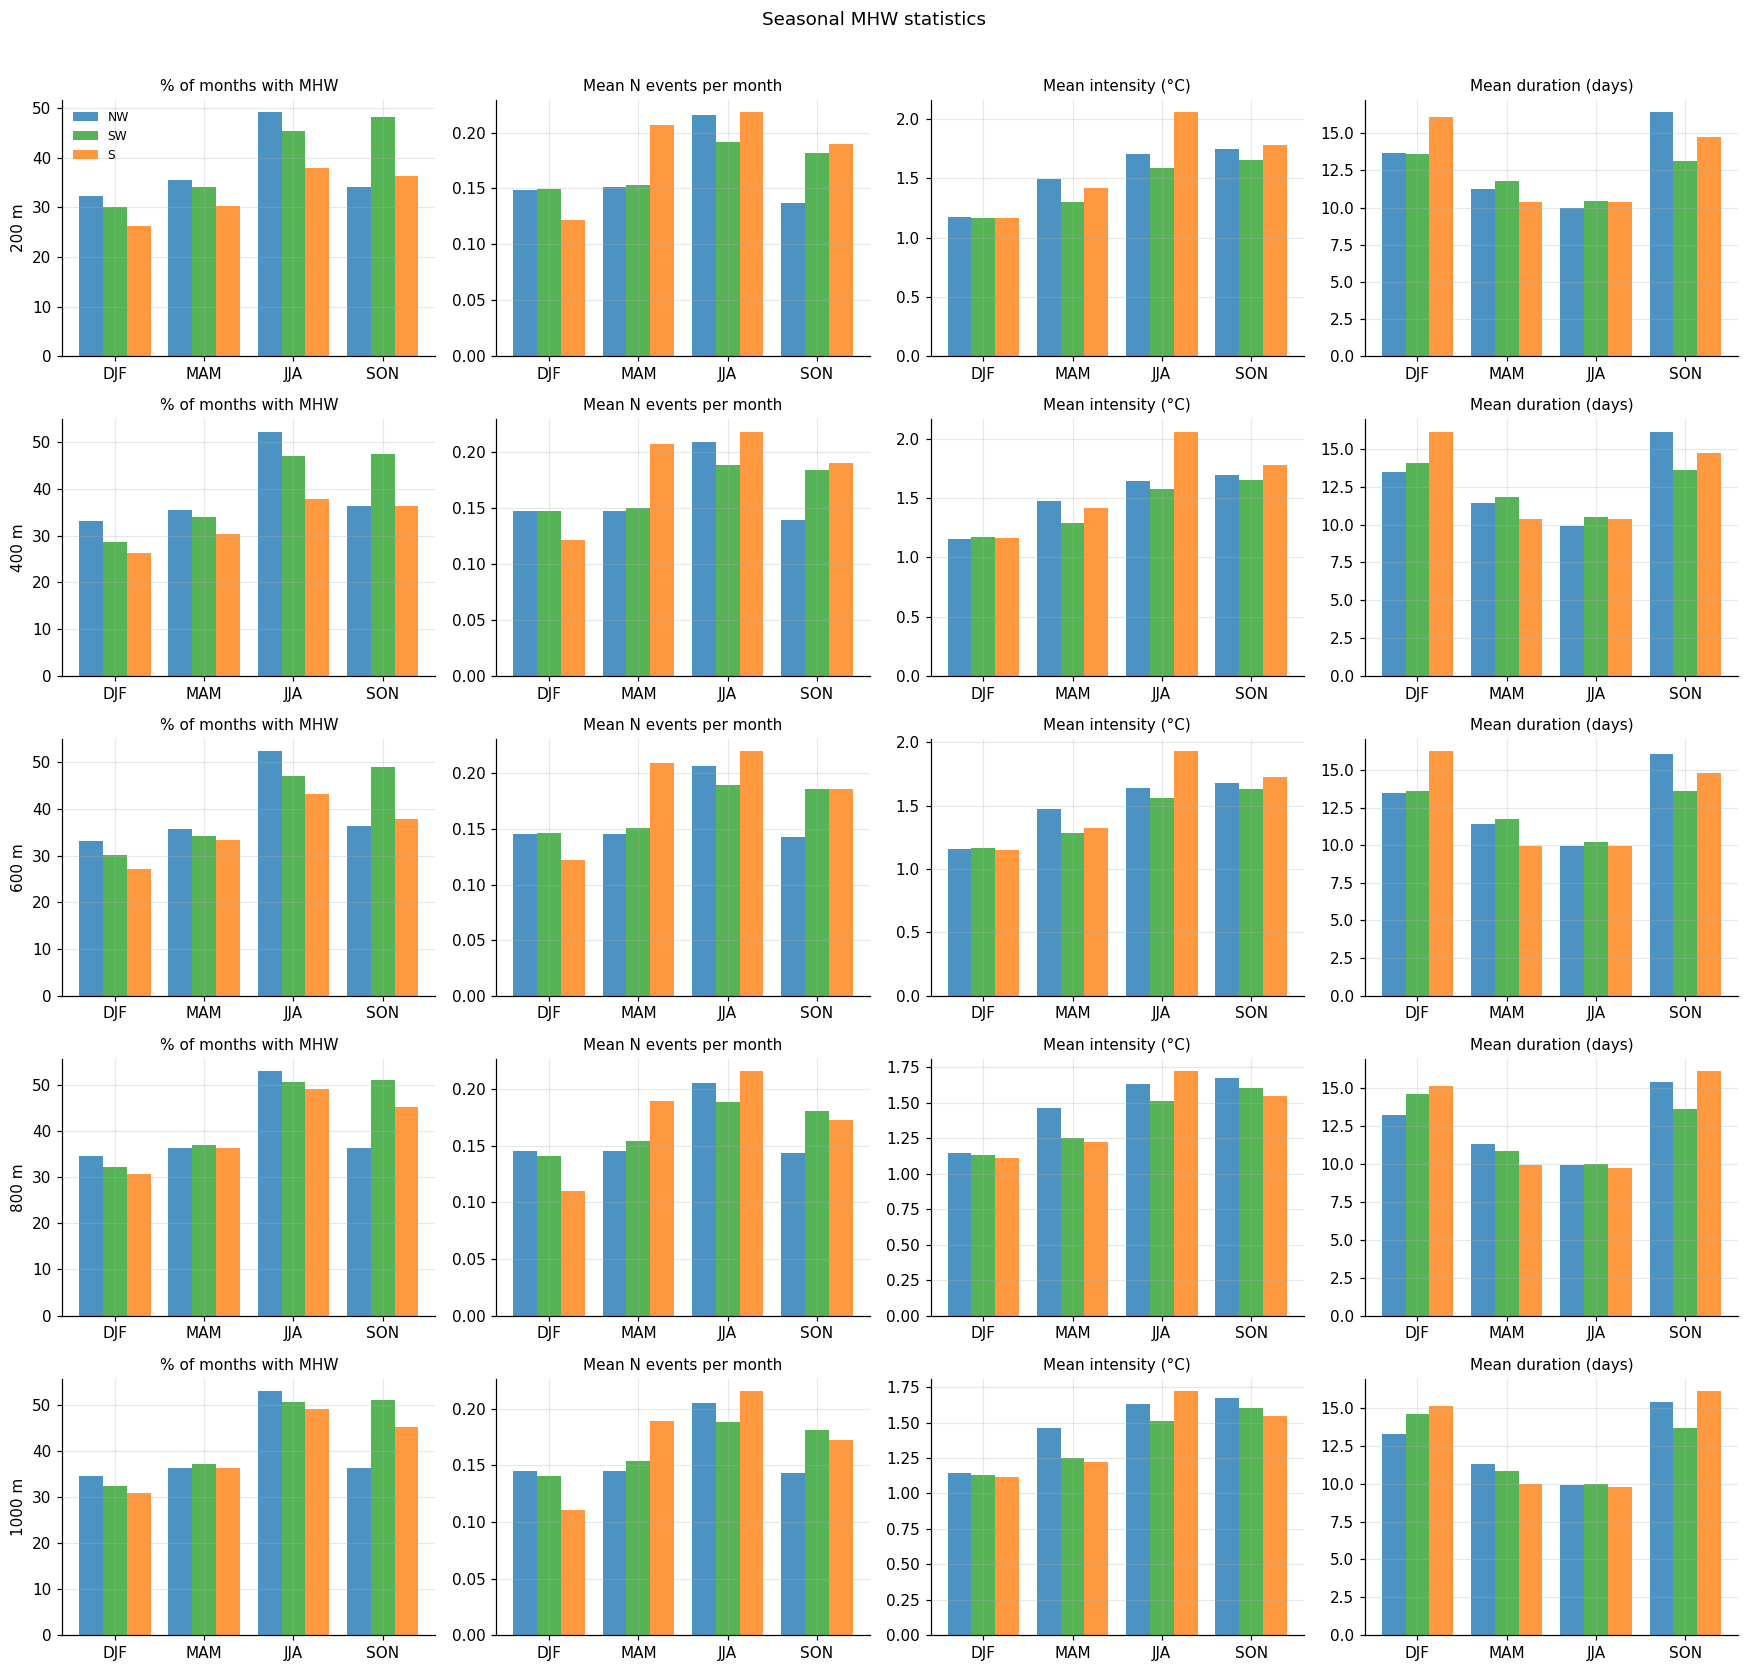

In [25]:
S = seasonal.reset_index()
seas = ["DJF", "MAM", "JJA", "SON"]
panels = [("pct_active", "% of months with MHW"), ("mean_n_events", "Mean N events per month"),
          ("mean_intensity", "Mean intensity (°C)"), ("mean_duration", "Mean duration (days)")]
fig, axes = plt.subplots(len(iso_list), len(panels), figsize=(4*len(panels), 3*len(iso_list)), squeeze=False)
w = 0.8 / len(ZONES)
for r, iso in enumerate(iso_list):
    for c, (v, lab) in enumerate(panels):
        ax = axes[r, c]
        for j, z in enumerate(ZONES):
            g = S[(S.Isobath == iso) & (S.Zone == z)].set_index("Season").reindex(seas)
            ax.bar(np.arange(4) + (j-(len(ZONES)-1)/2)*w, g[v], w, color=colors[z], alpha=.8, label=z)
        ax.set_xticks(range(4), seas); ax.set_title(lab, fontsize=10)
        if c == 0: ax.set_ylabel(f"{iso} m")
axes[0, 0].legend(frameon=False, fontsize=8)
fig.suptitle("Seasonal MHW statistics", y=1.01); fig.tight_layout()
fig.savefig(FIG / "seasonal_bars.png", bbox_inches="tight"); plt.show()

### 7i. Decadal change

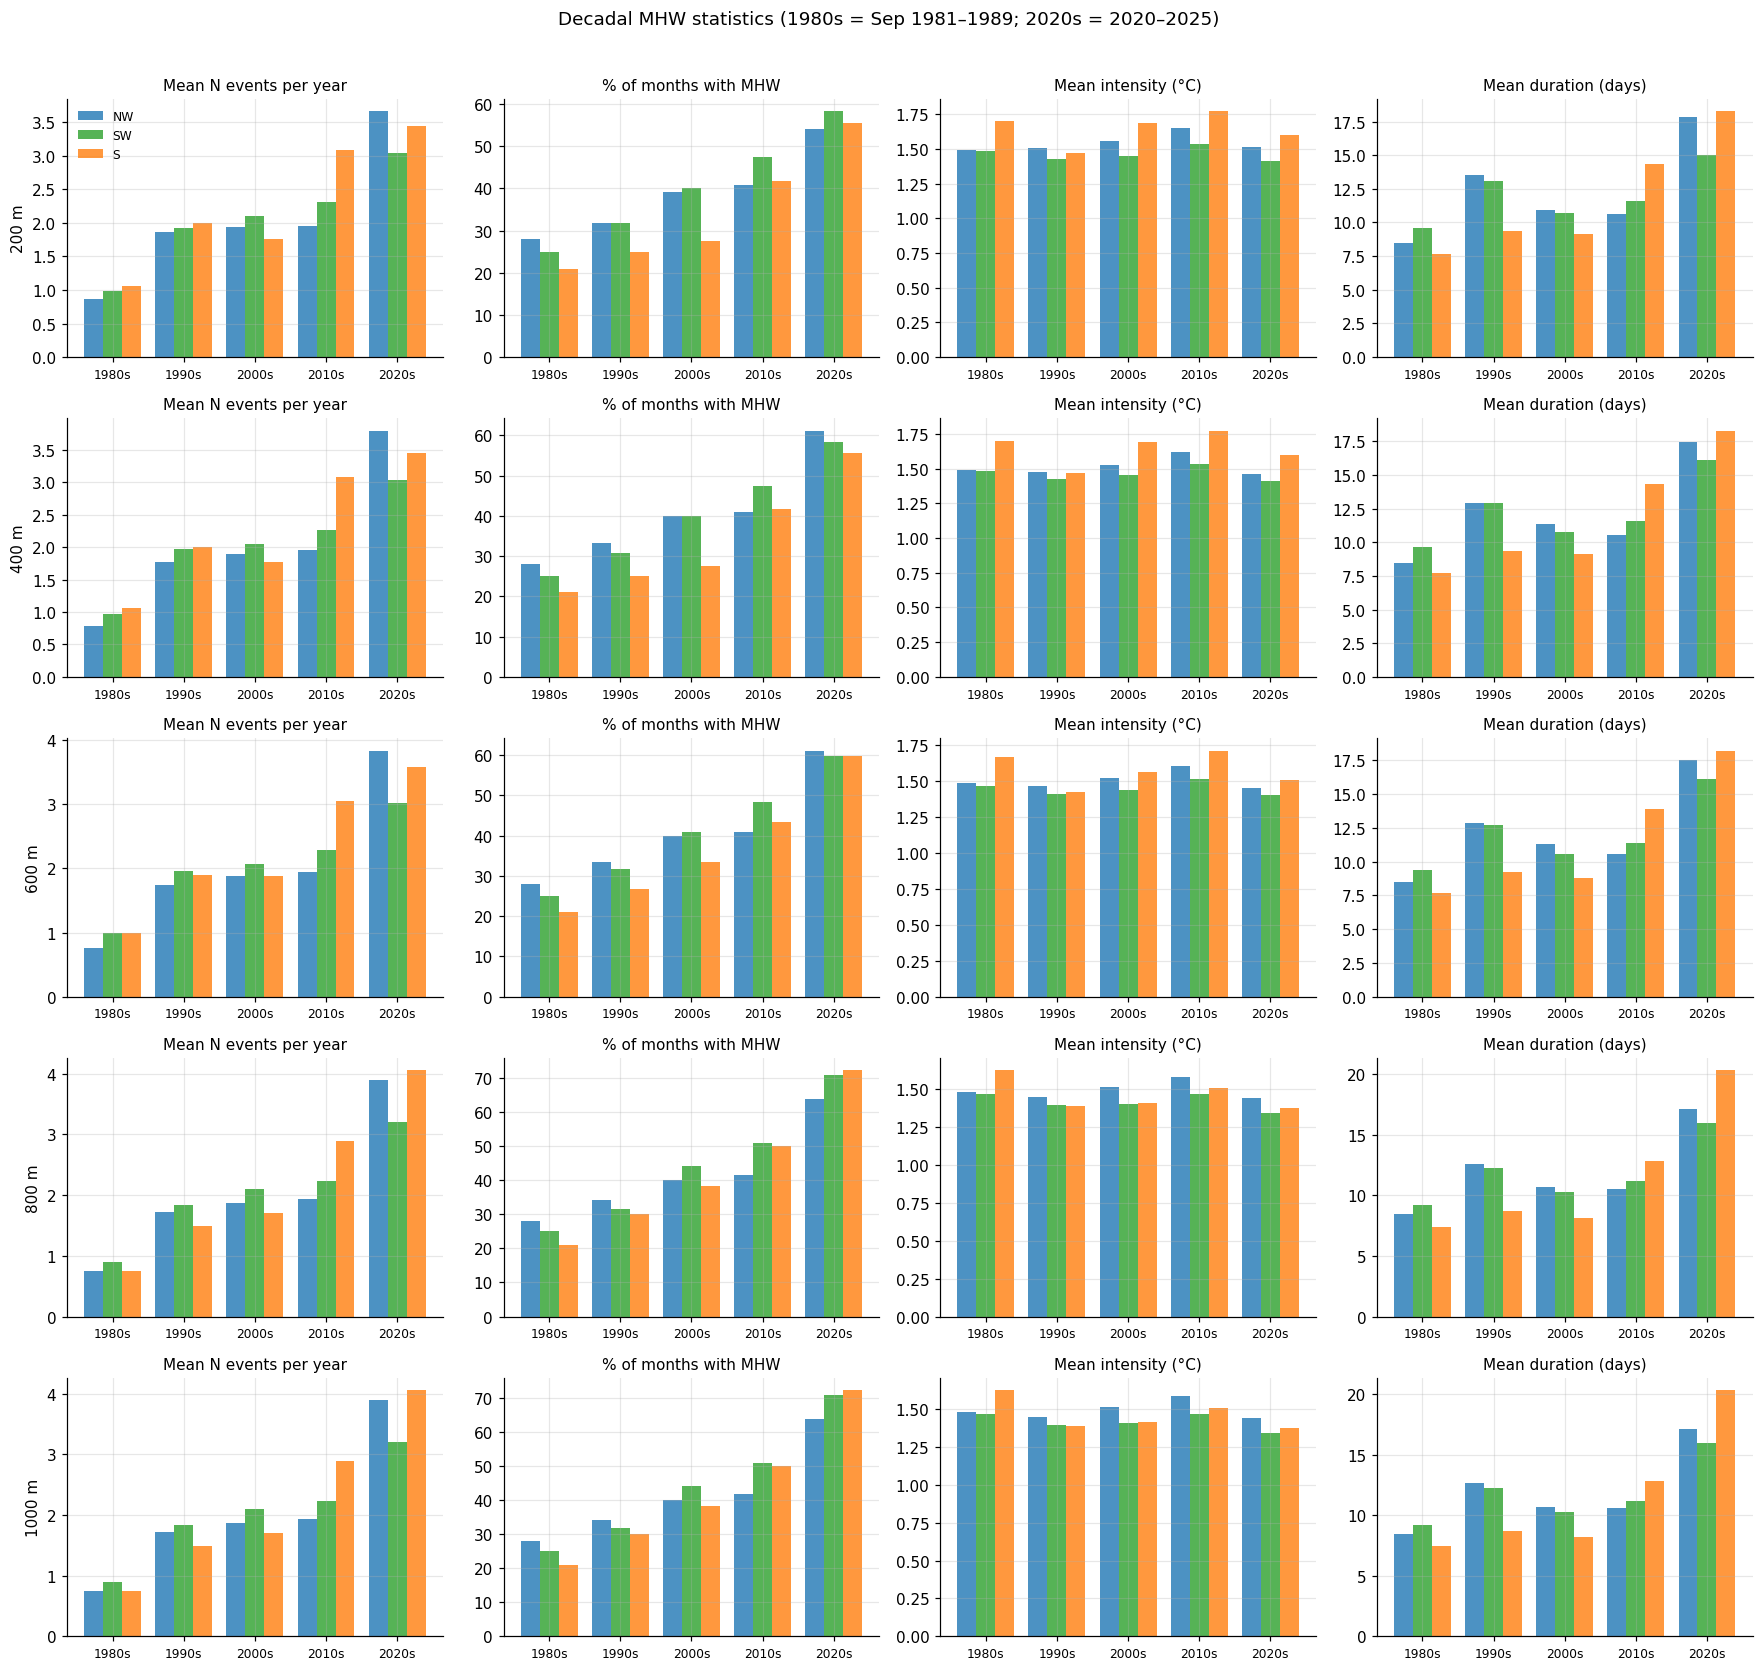

In [26]:
D = decadal.reset_index()
dec = sorted(D.Decade.unique())
panels = [("mean_n_events_yr", "Mean N events per year"), ("pct_active", "% of months with MHW"),
          ("mean_intensity", "Mean intensity (°C)"), ("mean_duration", "Mean duration (days)")]
fig, axes = plt.subplots(len(iso_list), len(panels), figsize=(4*len(panels), 3*len(iso_list)), squeeze=False)
for r, iso in enumerate(iso_list):
    for c, (v, lab) in enumerate(panels):
        ax = axes[r, c]
        for j, z in enumerate(ZONES):
            g = D[(D.Isobath == iso) & (D.Zone == z)].set_index("Decade").reindex(dec)
            ax.bar(np.arange(len(dec)) + (j-(len(ZONES)-1)/2)*w, g[v], w, color=colors[z], alpha=.8, label=z)
        ax.set_xticks(range(len(dec)), dec, fontsize=8); ax.set_title(lab, fontsize=10)
        if c == 0: ax.set_ylabel(f"{iso} m")
axes[0, 0].legend(frameon=False, fontsize=8)
fig.suptitle("Decadal MHW statistics (1980s = Sep 1981–1989; 2020s = 2020–2025)", y=1.01); fig.tight_layout()
fig.savefig(FIG / "decadal_bars.png", bbox_inches="tight"); plt.show()

### 7j. Trend slopes (Theil–Sen per decade, 95% CI)
Filled markers = significant (p < 0.05).

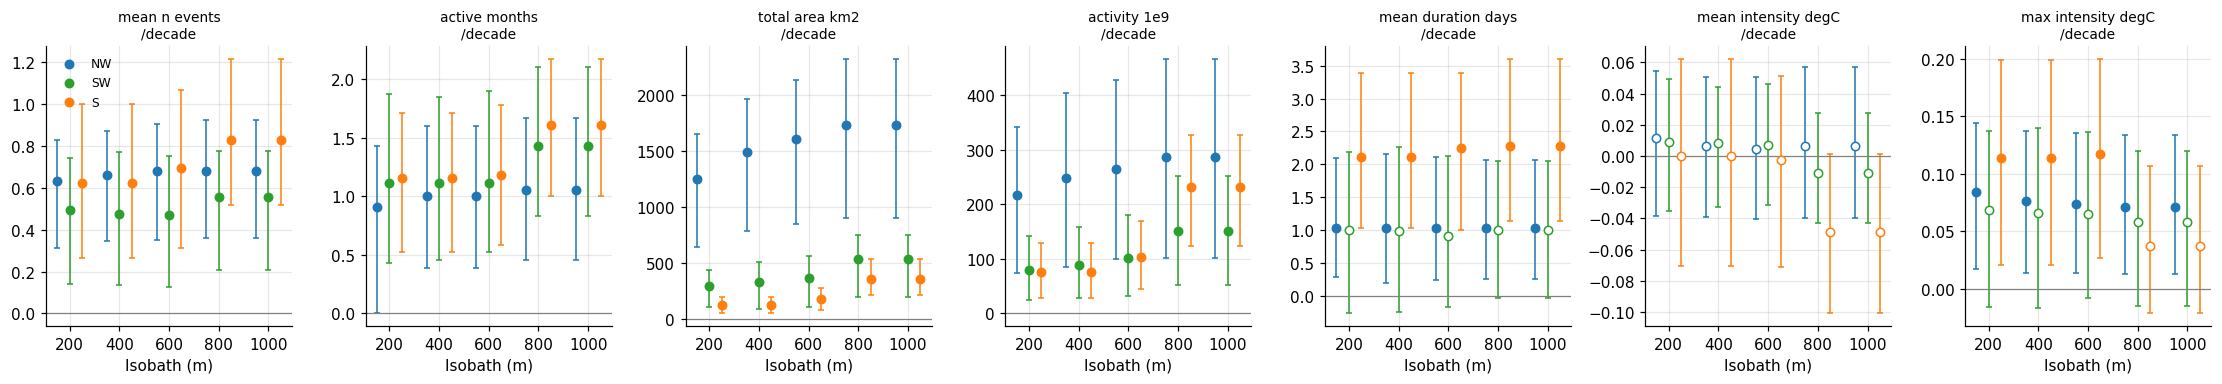

In [27]:
TT = T_trend.reset_index()
tvars = [v for v in ANN_VARS if v in TT.Variable.unique()]
fig, axes = plt.subplots(1, len(tvars), figsize=(2.9*len(tvars), 3.6))
for ax, v in zip(axes, tvars):
    for j, z in enumerate(ZONES):
        g = TT[(TT.Variable == v) & (TT.Zone == z)].set_index("Isobath").reindex(iso_list)
        x = np.arange(len(iso_list)) + (j-(len(ZONES)-1)/2)*0.25
        ax.errorbar(x, g.Sen_slope_per_decade,
                    yerr=[g.Sen_slope_per_decade - g.CI95_low, g.CI95_high - g.Sen_slope_per_decade],
                    fmt="none", ecolor=colors[z], lw=1, capsize=2)
        sig = g.p_value < .05
        ax.scatter(x[sig], g.Sen_slope_per_decade[sig], color=colors[z], s=30, zorder=3, label=z)
        ax.scatter(x[~sig], g.Sen_slope_per_decade[~sig], facecolor="white", edgecolor=colors[z], s=30, zorder=3)
    ax.axhline(0, color="grey", lw=.8)
    ax.set_xticks(range(len(iso_list)), [f"{i}" for i in iso_list]); ax.set_xlabel("Isobath (m)")
    ax.set_title(v.replace("_", " ") + "\n/decade", fontsize=9)
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "trend_slopes.png", bbox_inches="tight"); plt.show()

### 7k. Correlation between MHW metrics (Spearman, onset months)

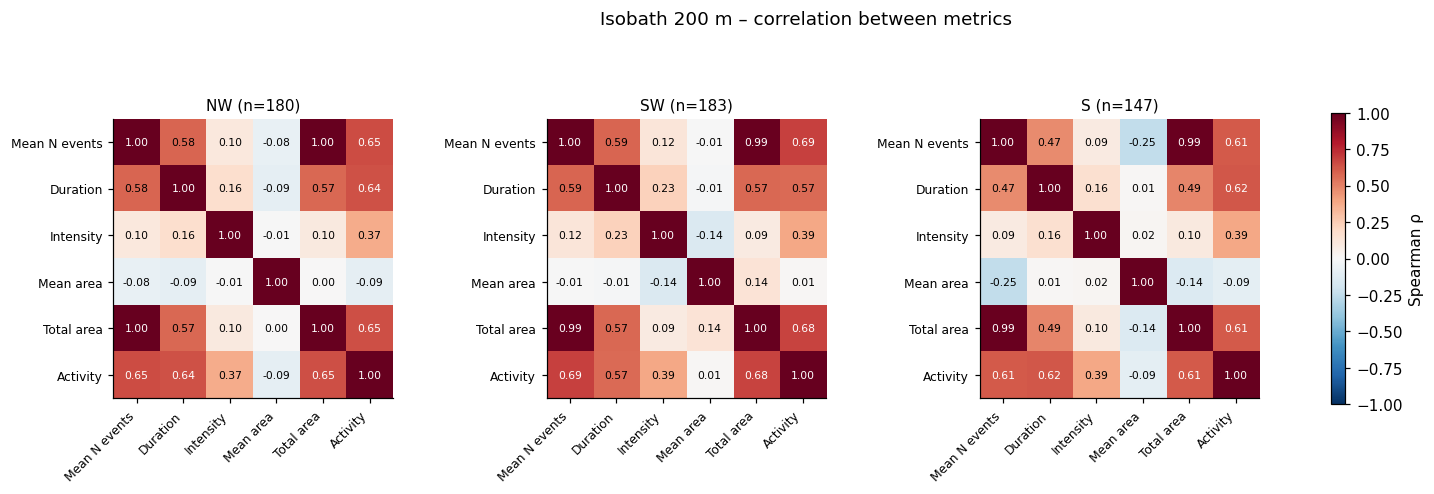

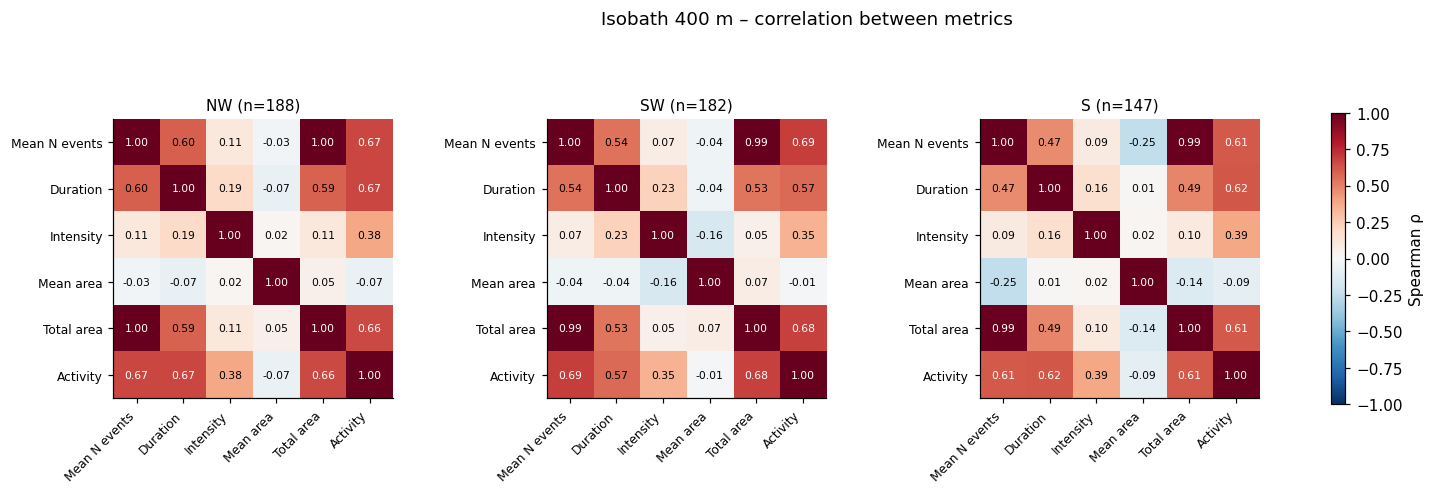

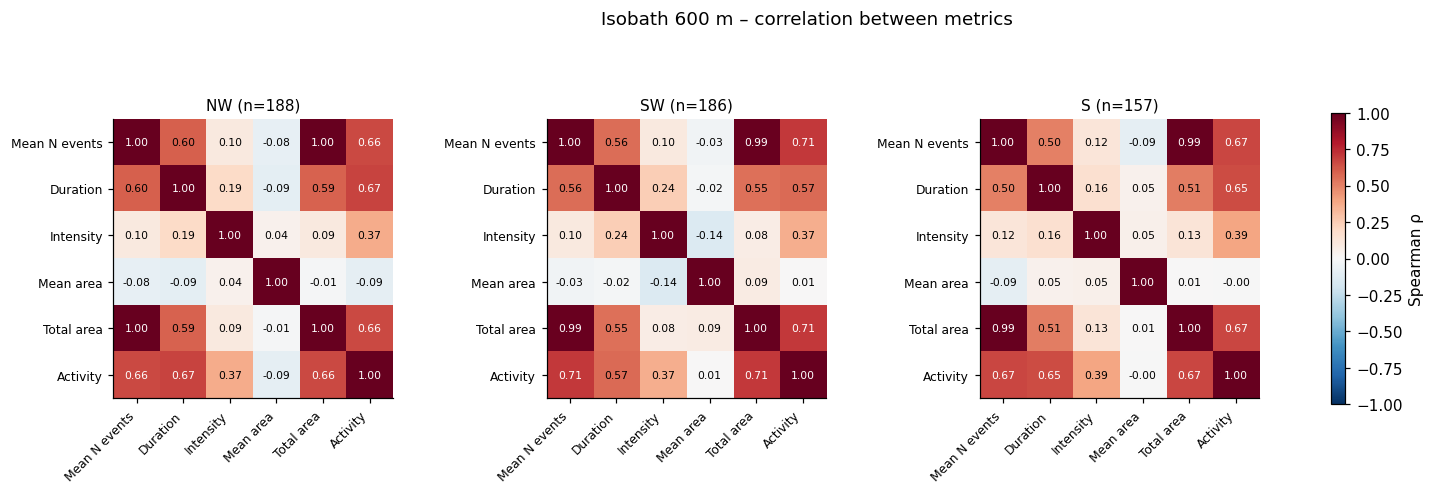

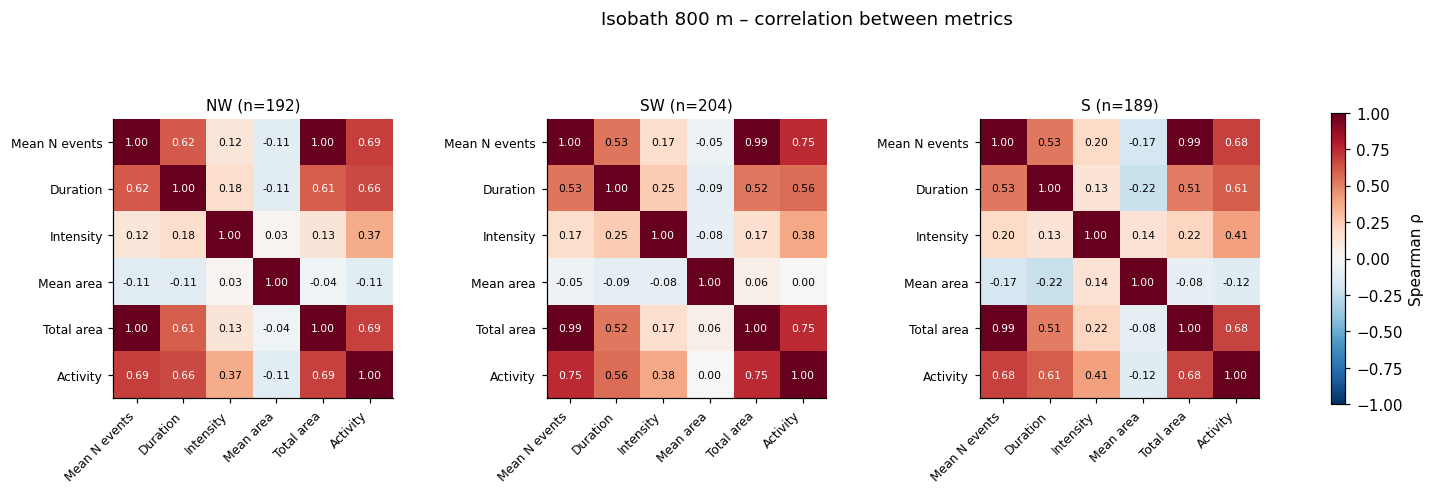

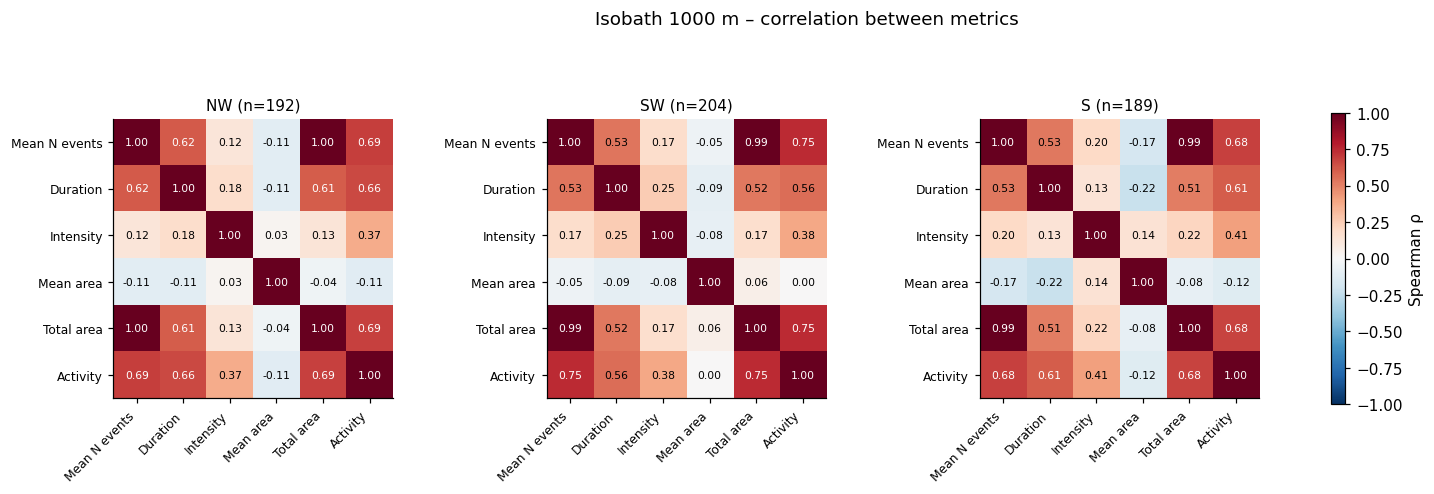

In [28]:
cvars = ["mean_n_events", "mean_duration_days", "mean_intensity_degC", "mean_area_km2", "sum_area_km2", "activity_1e9"]
clab = ["Mean N events", "Duration", "Intensity", "Mean area", "Total area", "Activity"]
for iso in iso_list:
    fig, axes = plt.subplots(1, len(ZONES), figsize=(5.6*len(ZONES), 4.3), gridspec_kw=dict(wspace=.55))
    for ax, z in zip(axes, ZONES):
        g = df[(df.Isobath == iso) & (df.Zone == z) & df.onset][cvars]
        R = g.corr(method="spearman")
        im = ax.imshow(R, cmap="RdBu_r", vmin=-1, vmax=1)
        for (a, b), val in np.ndenumerate(R.values):
            ax.text(b, a, f"{val:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if abs(val) > .6 else "black")
        ax.set_xticks(range(len(clab)), clab, rotation=45, ha="right", fontsize=8)
        ax.set_yticks(range(len(clab)), clab, fontsize=8); ax.grid(False)
        ax.set_title(f"{z} (n={len(g)})", fontsize=10)
    fig.colorbar(im, ax=axes, shrink=.8, label="Spearman ρ")
    fig.suptitle(f"Isobath {iso} m – correlation between metrics", y=1.02)
    fig.savefig(FIG / f"correlation_{iso}m.png", bbox_inches="tight"); plt.show()

### 7l. Cumulative distribution of MHW intensity

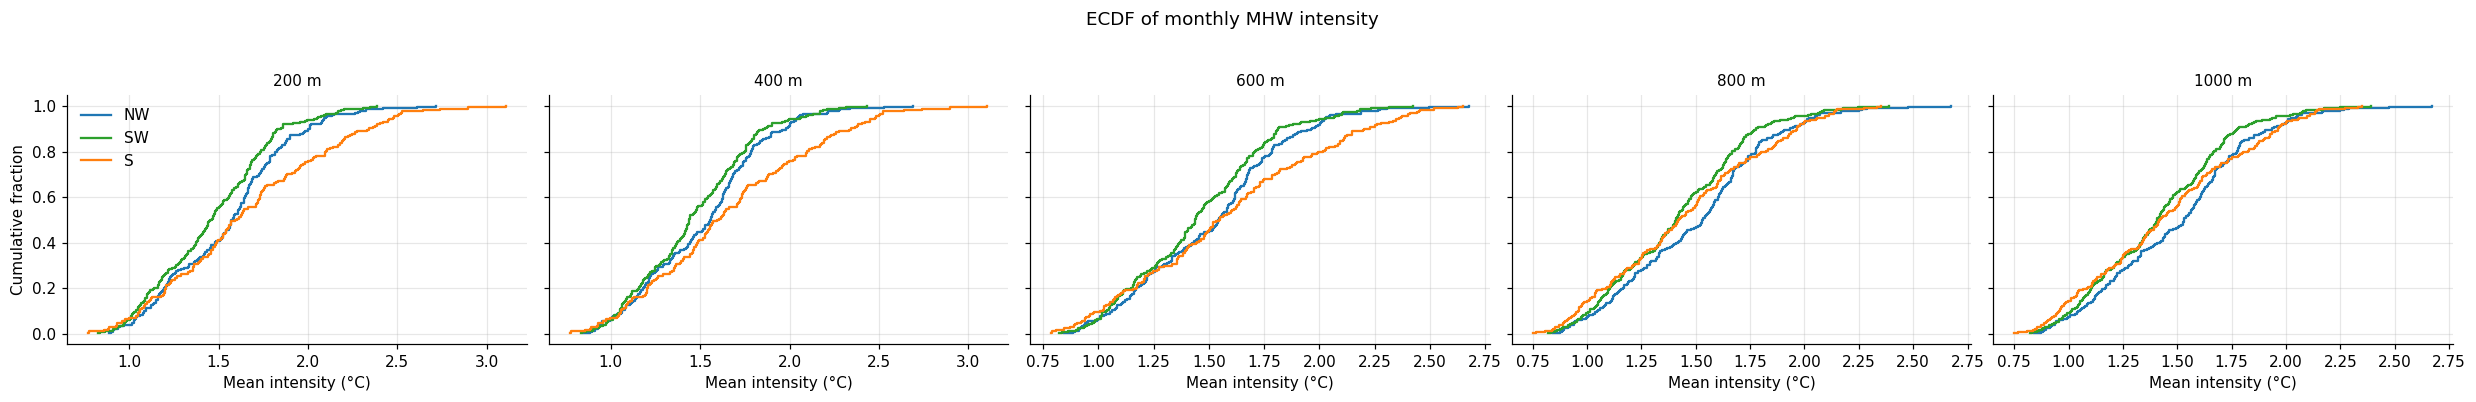

In [29]:
fig, axes = plt.subplots(1, len(iso_list), figsize=(4.5*len(iso_list), 3.5), squeeze=False, sharey=True)
for ax, iso in zip(axes[0], iso_list):
    for z in ZONES:
        s = np.sort(act[(act.Isobath == iso) & (act.Zone == z)].mean_intensity_degC.dropna())
        ax.step(s, np.arange(1, len(s)+1)/len(s), where="post", color=colors[z], label=z)
    ax.set_title(f"{iso} m", fontsize=10); ax.set_xlabel("Mean intensity (°C)")
axes[0, 0].set_ylabel("Cumulative fraction"); axes[0, 0].legend(frameon=False)
fig.suptitle("ECDF of monthly MHW intensity", y=1.03); fig.tight_layout()
fig.savefig(FIG / "ecdf_intensity.png", bbox_inches="tight"); plt.show()

### 7m. Annual bar charts
Annual values per zone, with the 1991–2020 mean (dashed).

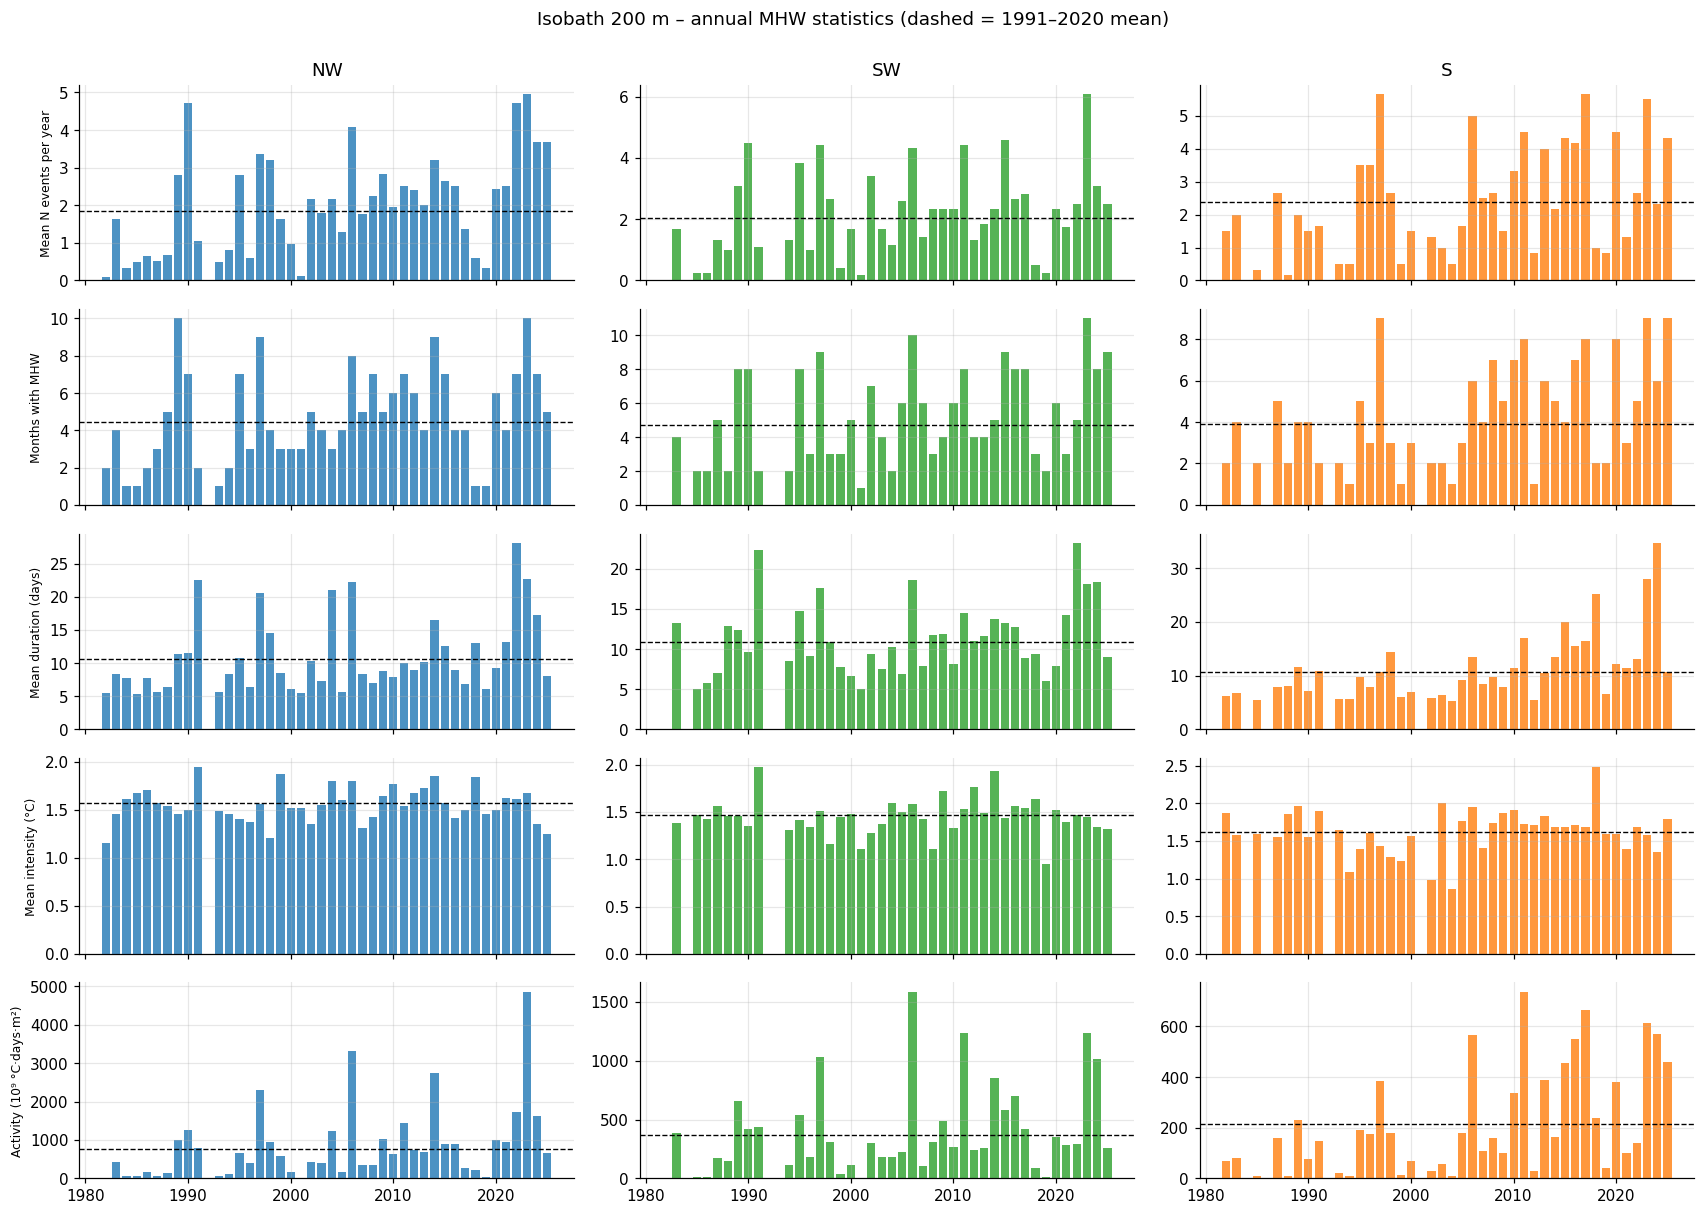

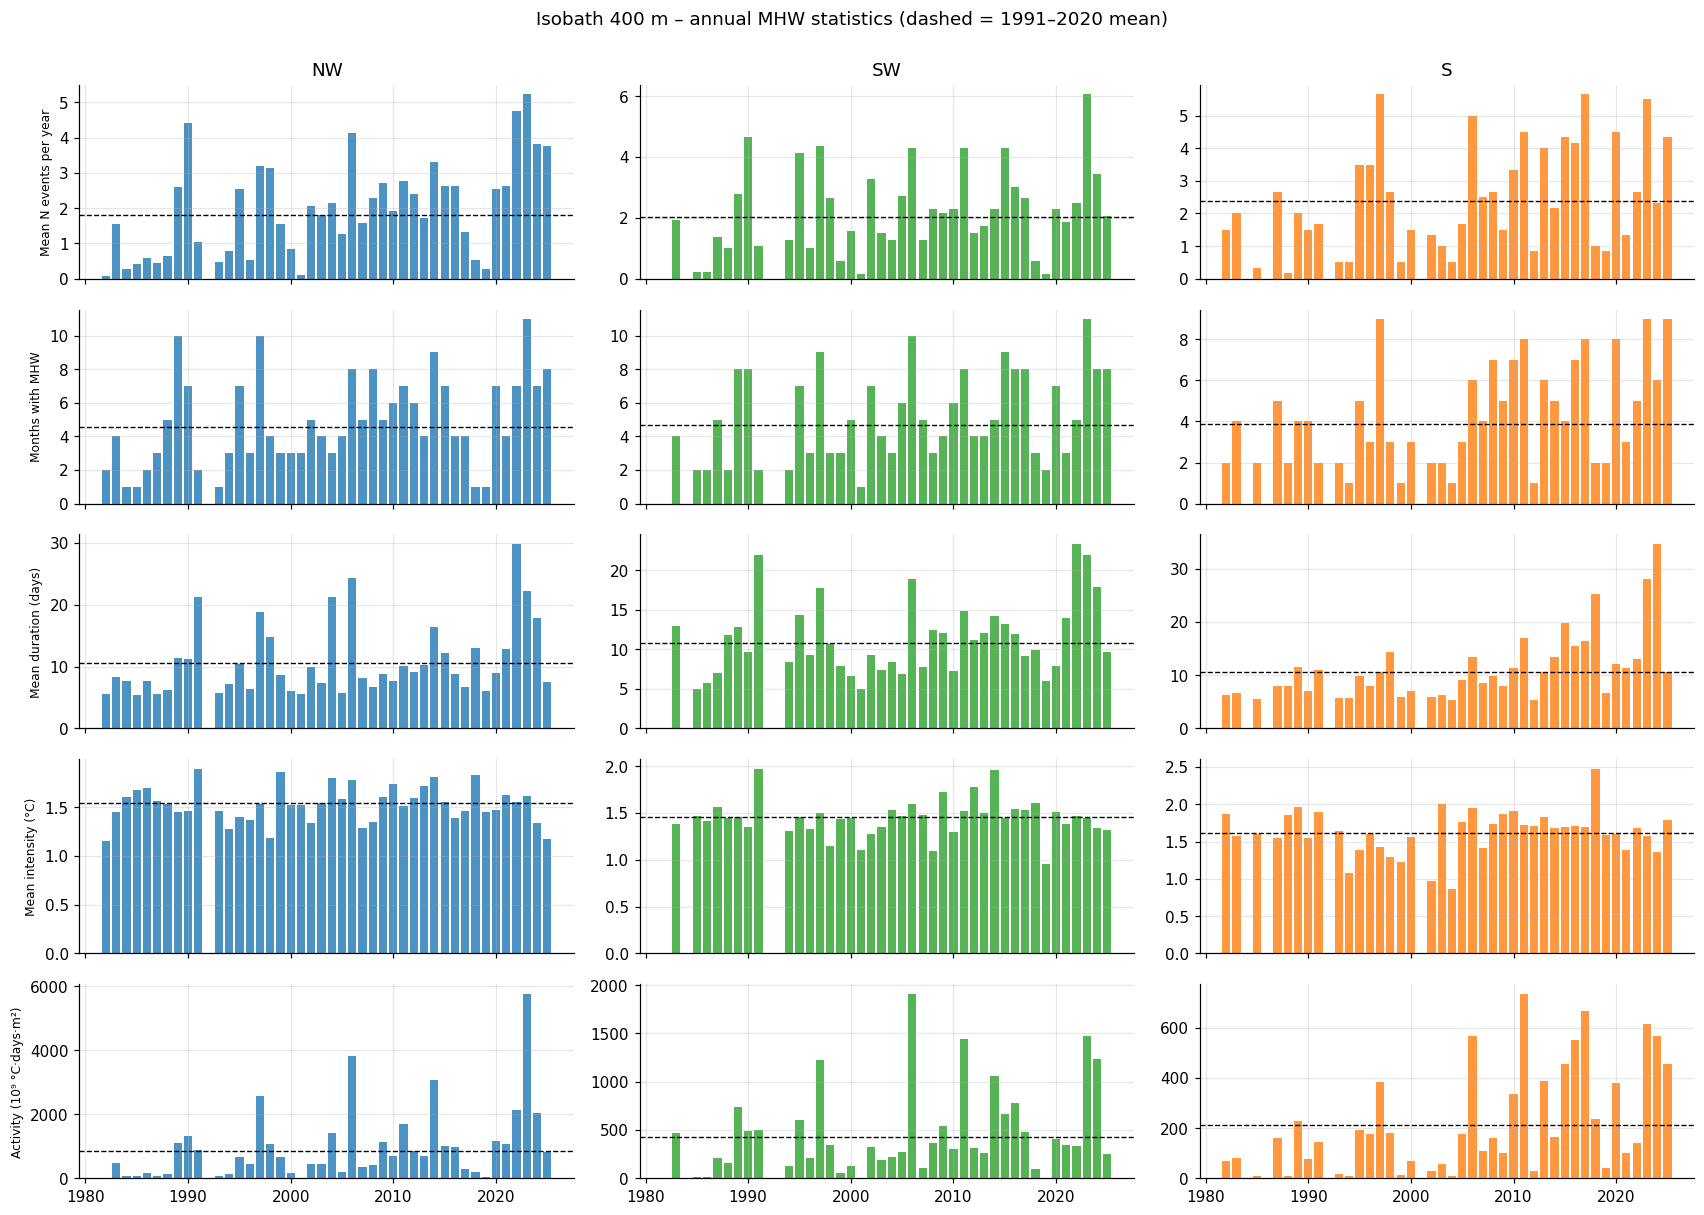

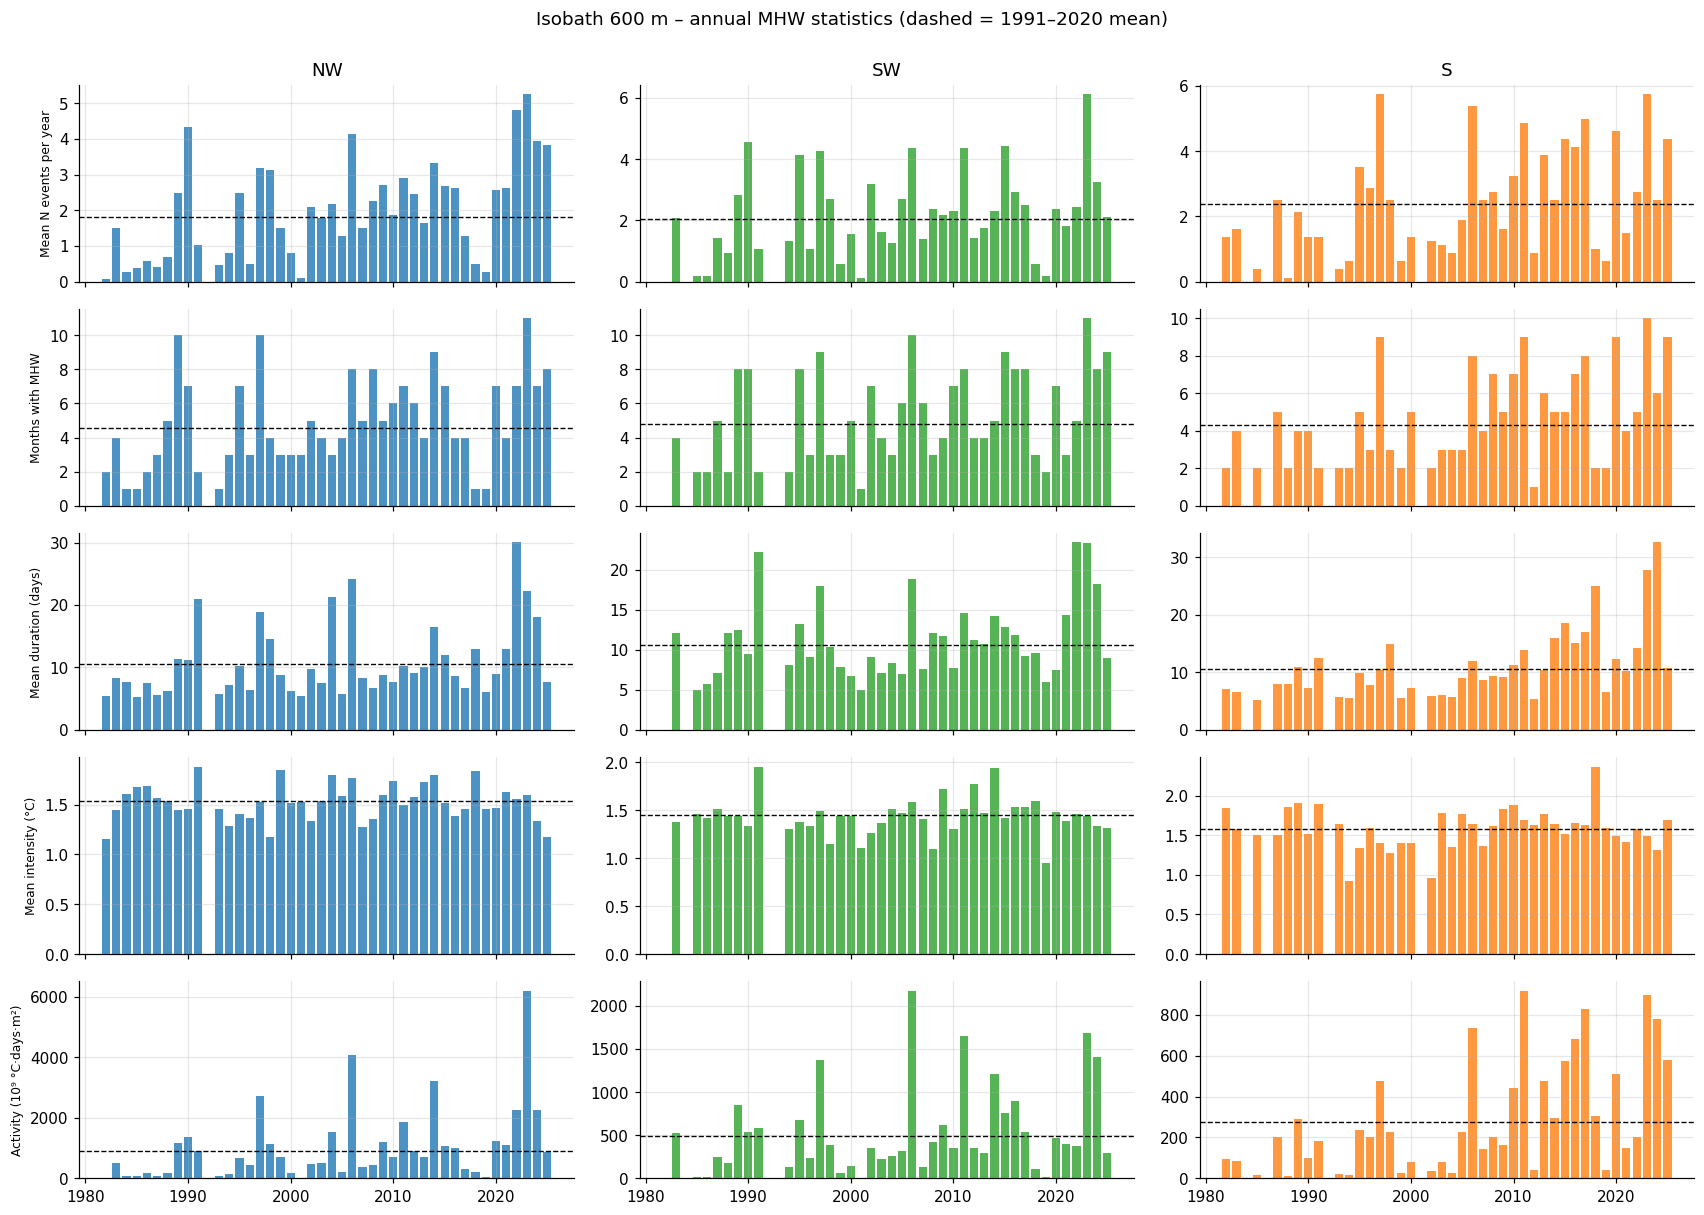

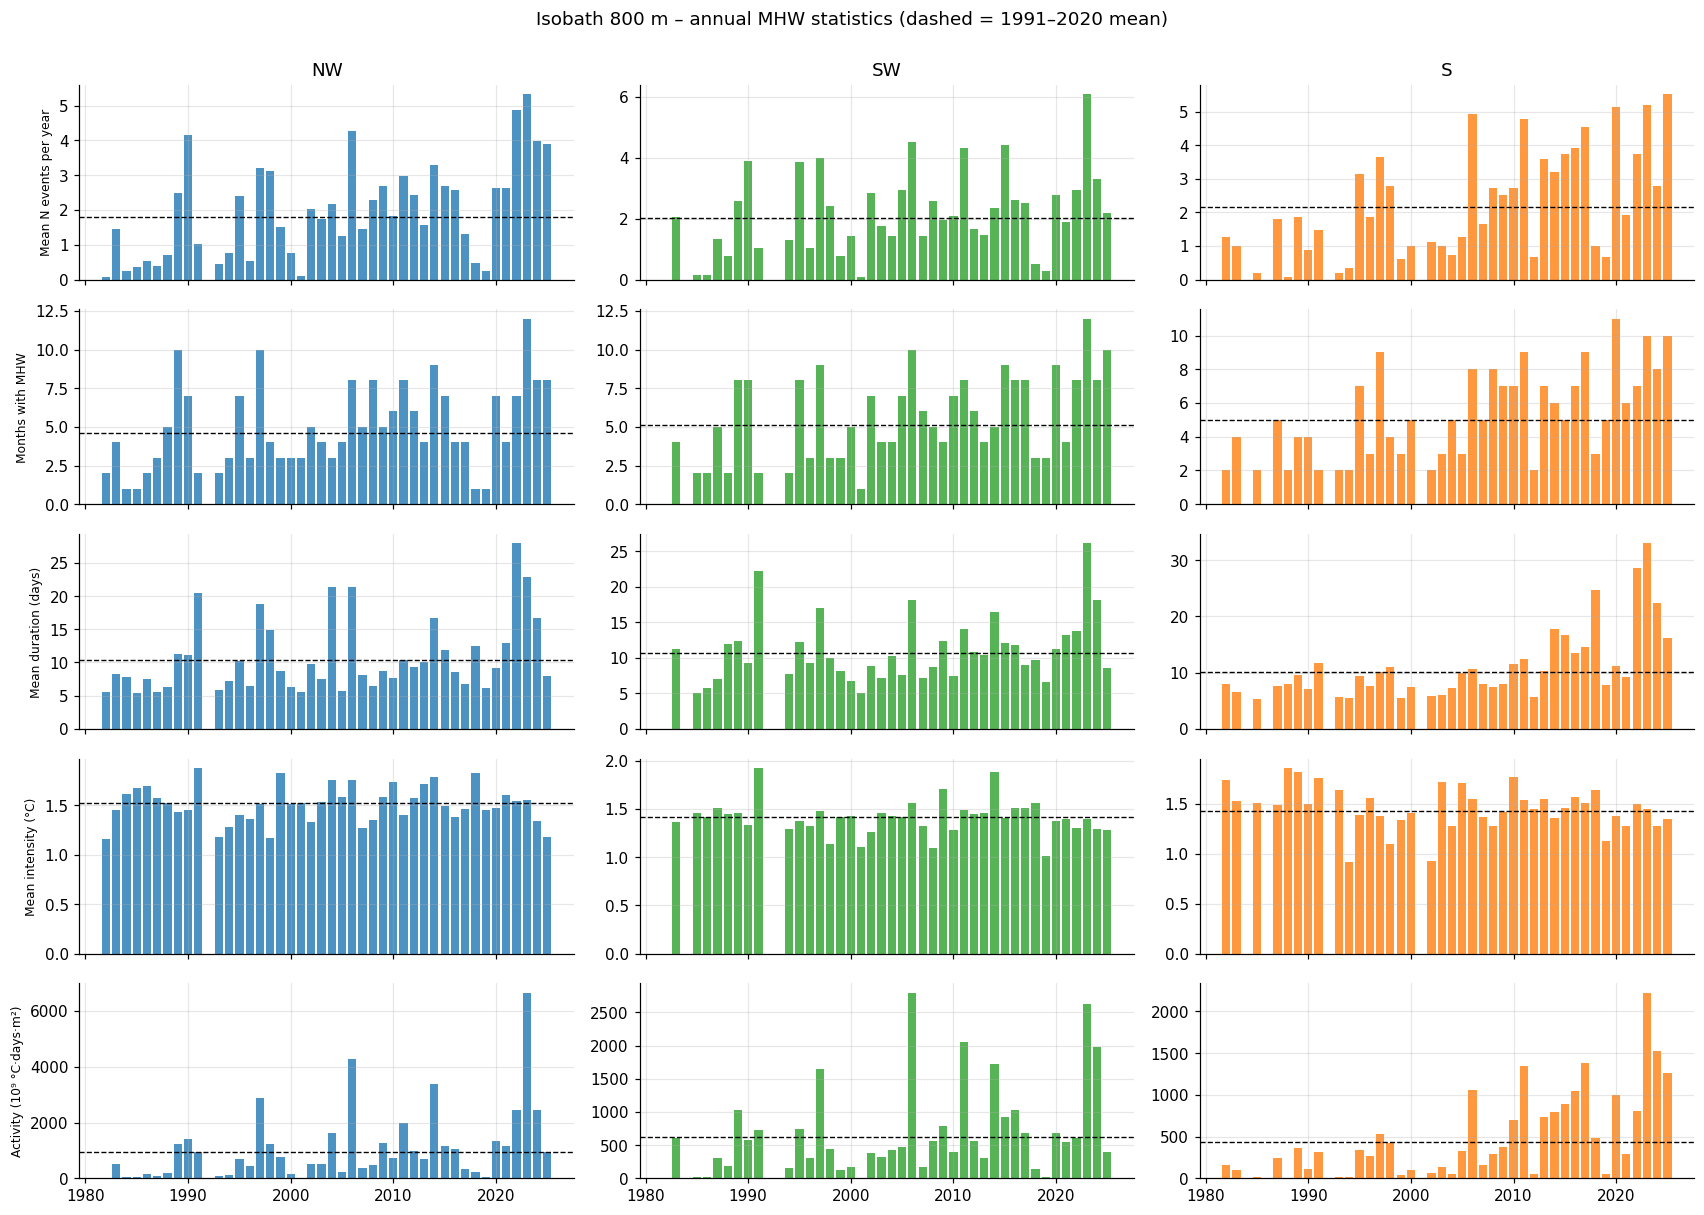

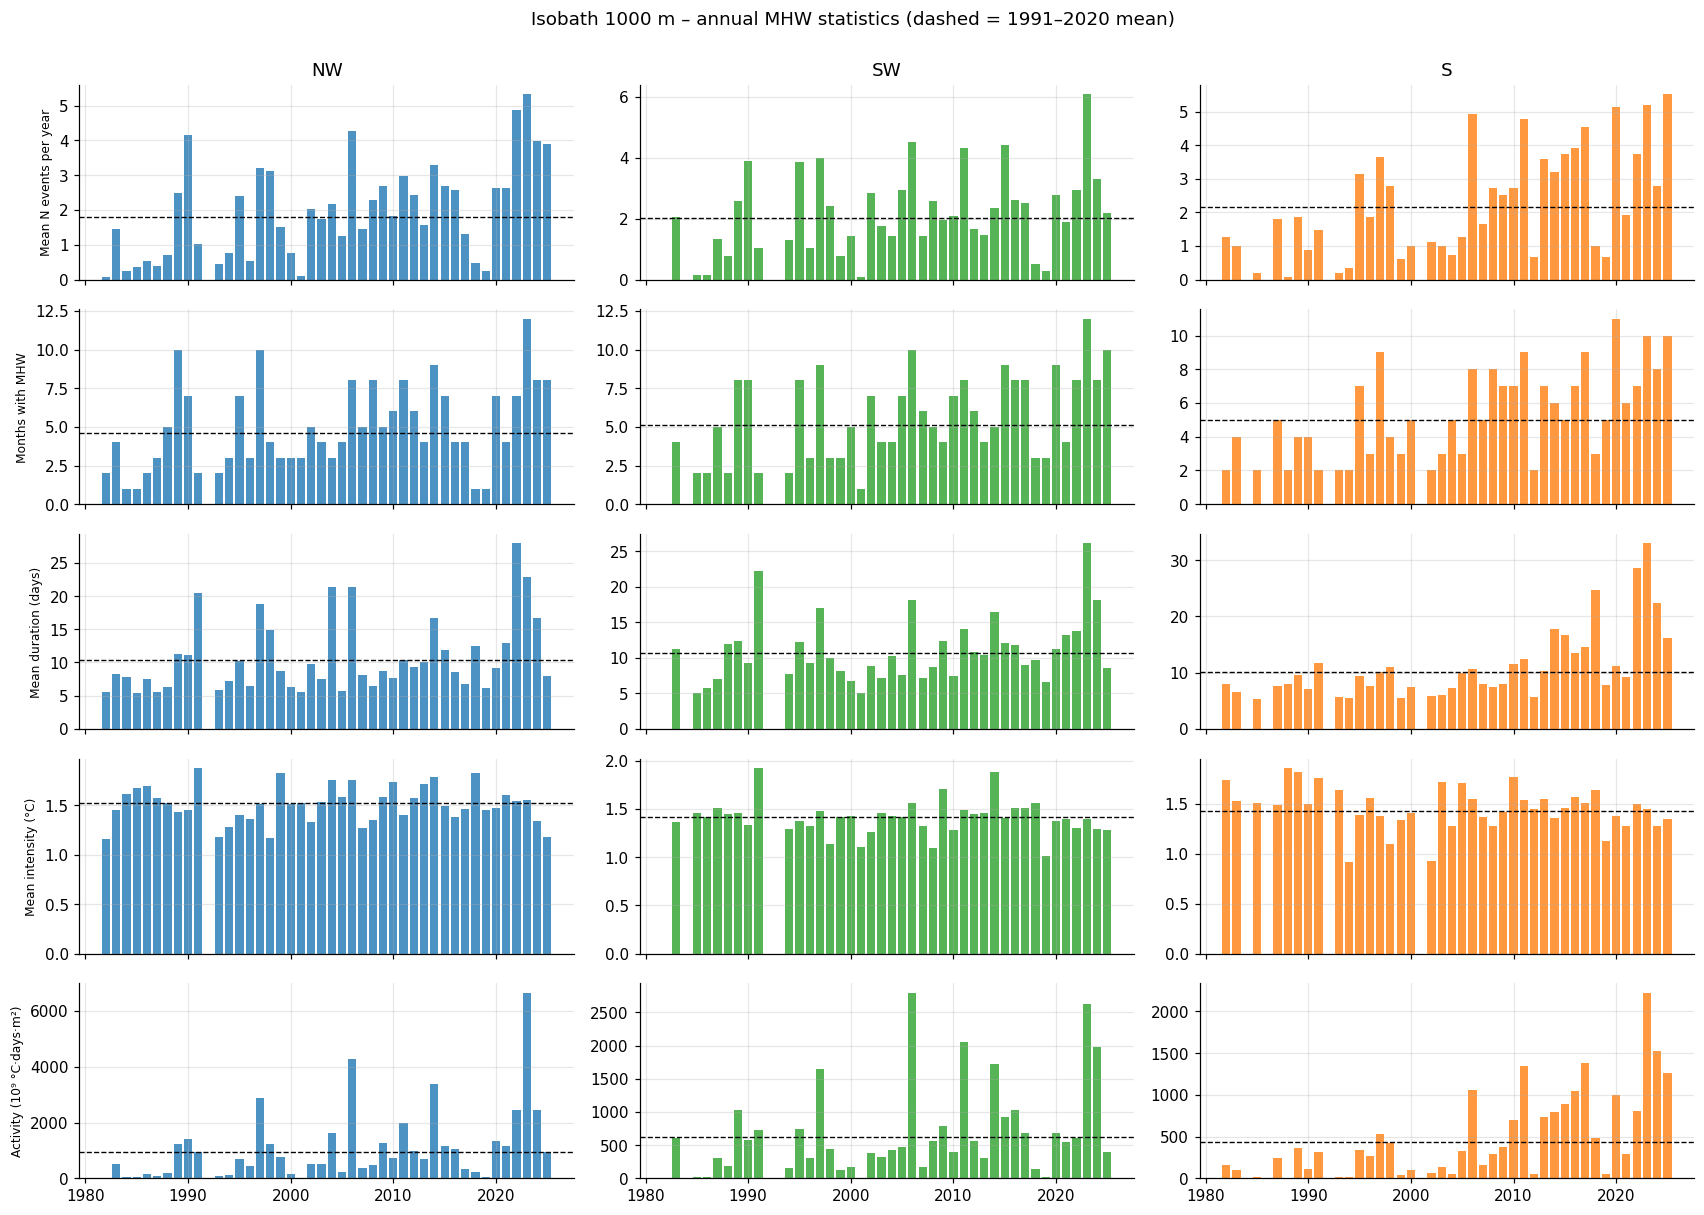

In [30]:
ann_panels = [("mean_n_events","Mean N events per year"), ("active_months","Months with MHW"),
              ("mean_duration_days","Mean duration (days)"), ("mean_intensity_degC","Mean intensity (°C)"),
              ("activity_1e9","Activity (10⁹ °C·days·m²)")]
for iso in iso_list:
    fig, axes = plt.subplots(len(ann_panels), len(ZONES), figsize=(5.2*len(ZONES), 2.2*len(ann_panels)),
                             sharex=True, squeeze=False)
    for j, z in enumerate(ZONES):
        g = annual[(annual.Isobath == iso) & (annual.Zone == z)]
        for r, (v, lab) in enumerate(ann_panels):
            ax = axes[r, j]
            ax.bar(g.Year, g[v], color=colors[z], alpha=.8, width=.8)
            ax.axhline(base.loc[(iso, z), v], color="k", ls="--", lw=.9)
            if j == 0: ax.set_ylabel(lab, fontsize=8)
            if r == 0: ax.set_title(z)
    fig.suptitle(f"Isobath {iso} m – annual MHW statistics (dashed = 1991–2020 mean)", y=1.0)
    fig.tight_layout(); fig.savefig(FIG / f"annual_bars_{iso}m.png", bbox_inches="tight"); plt.show()

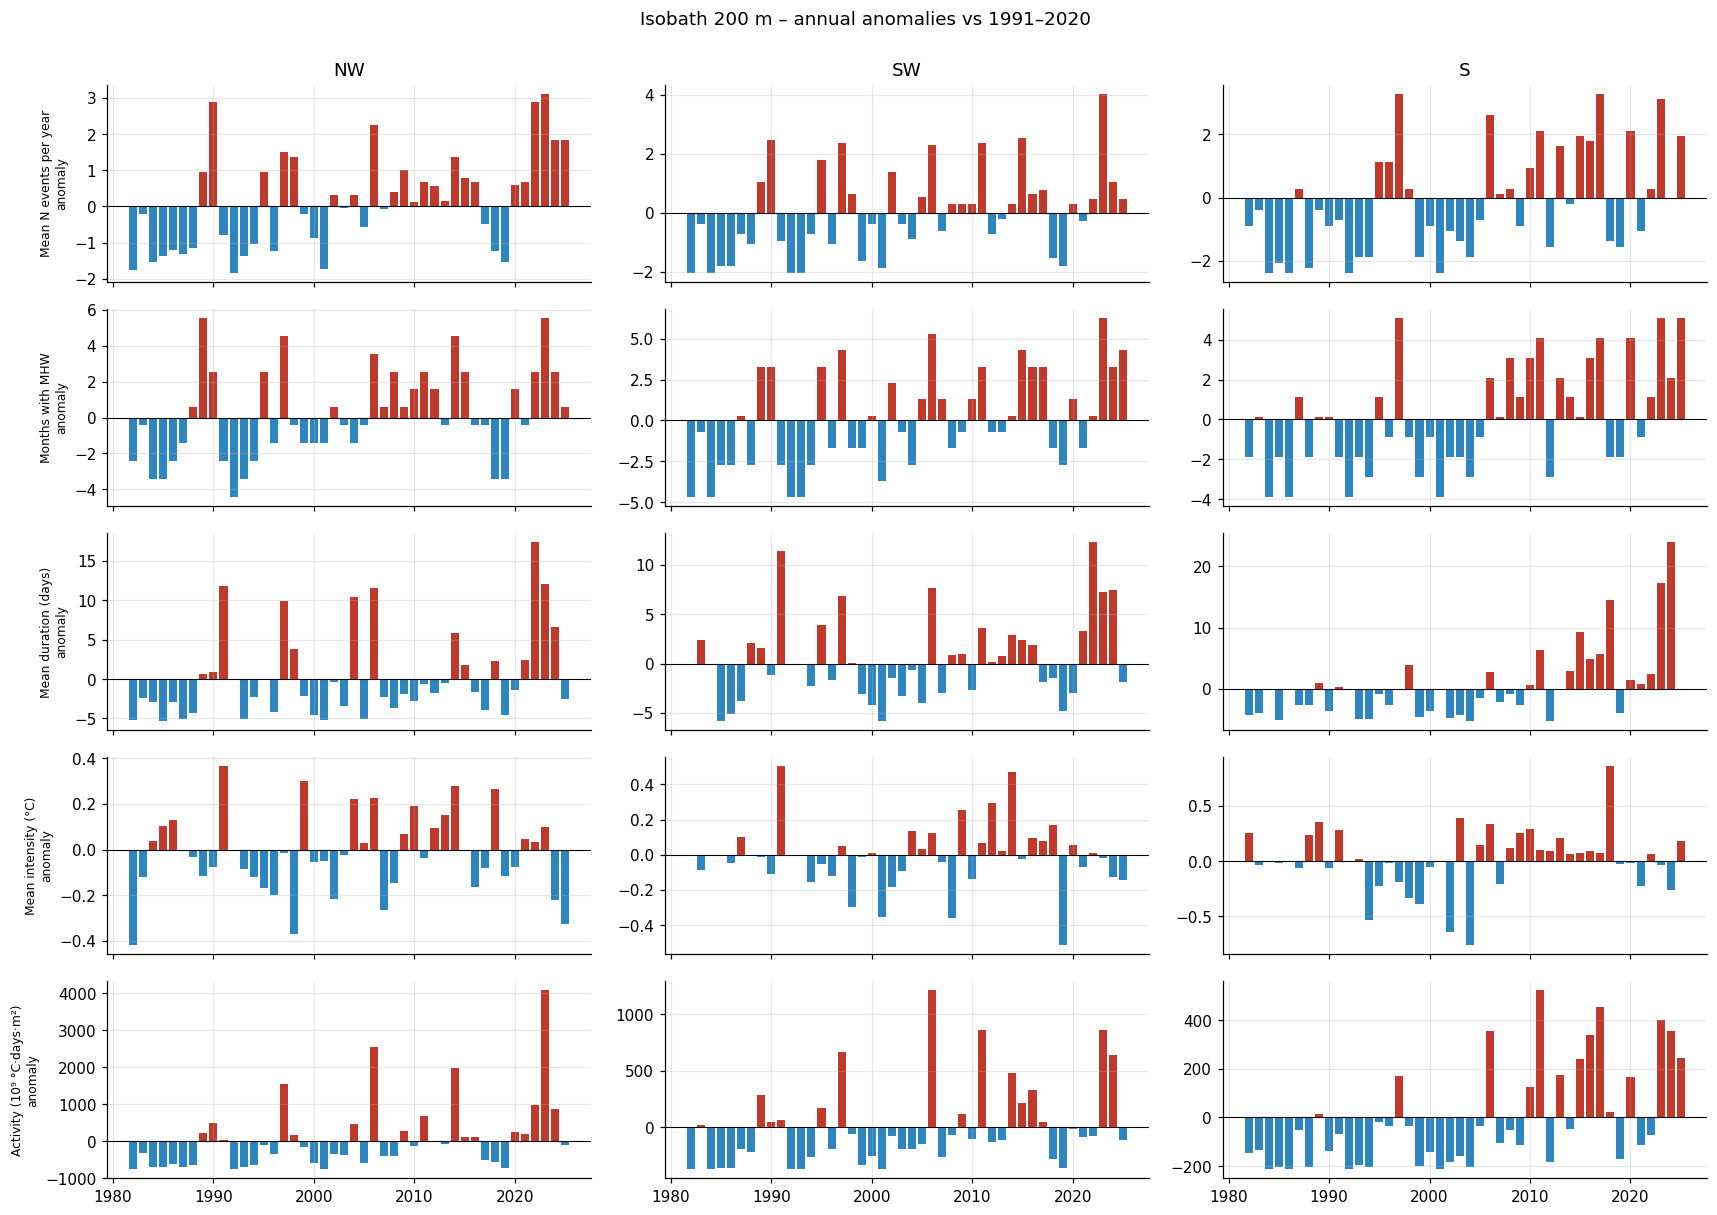

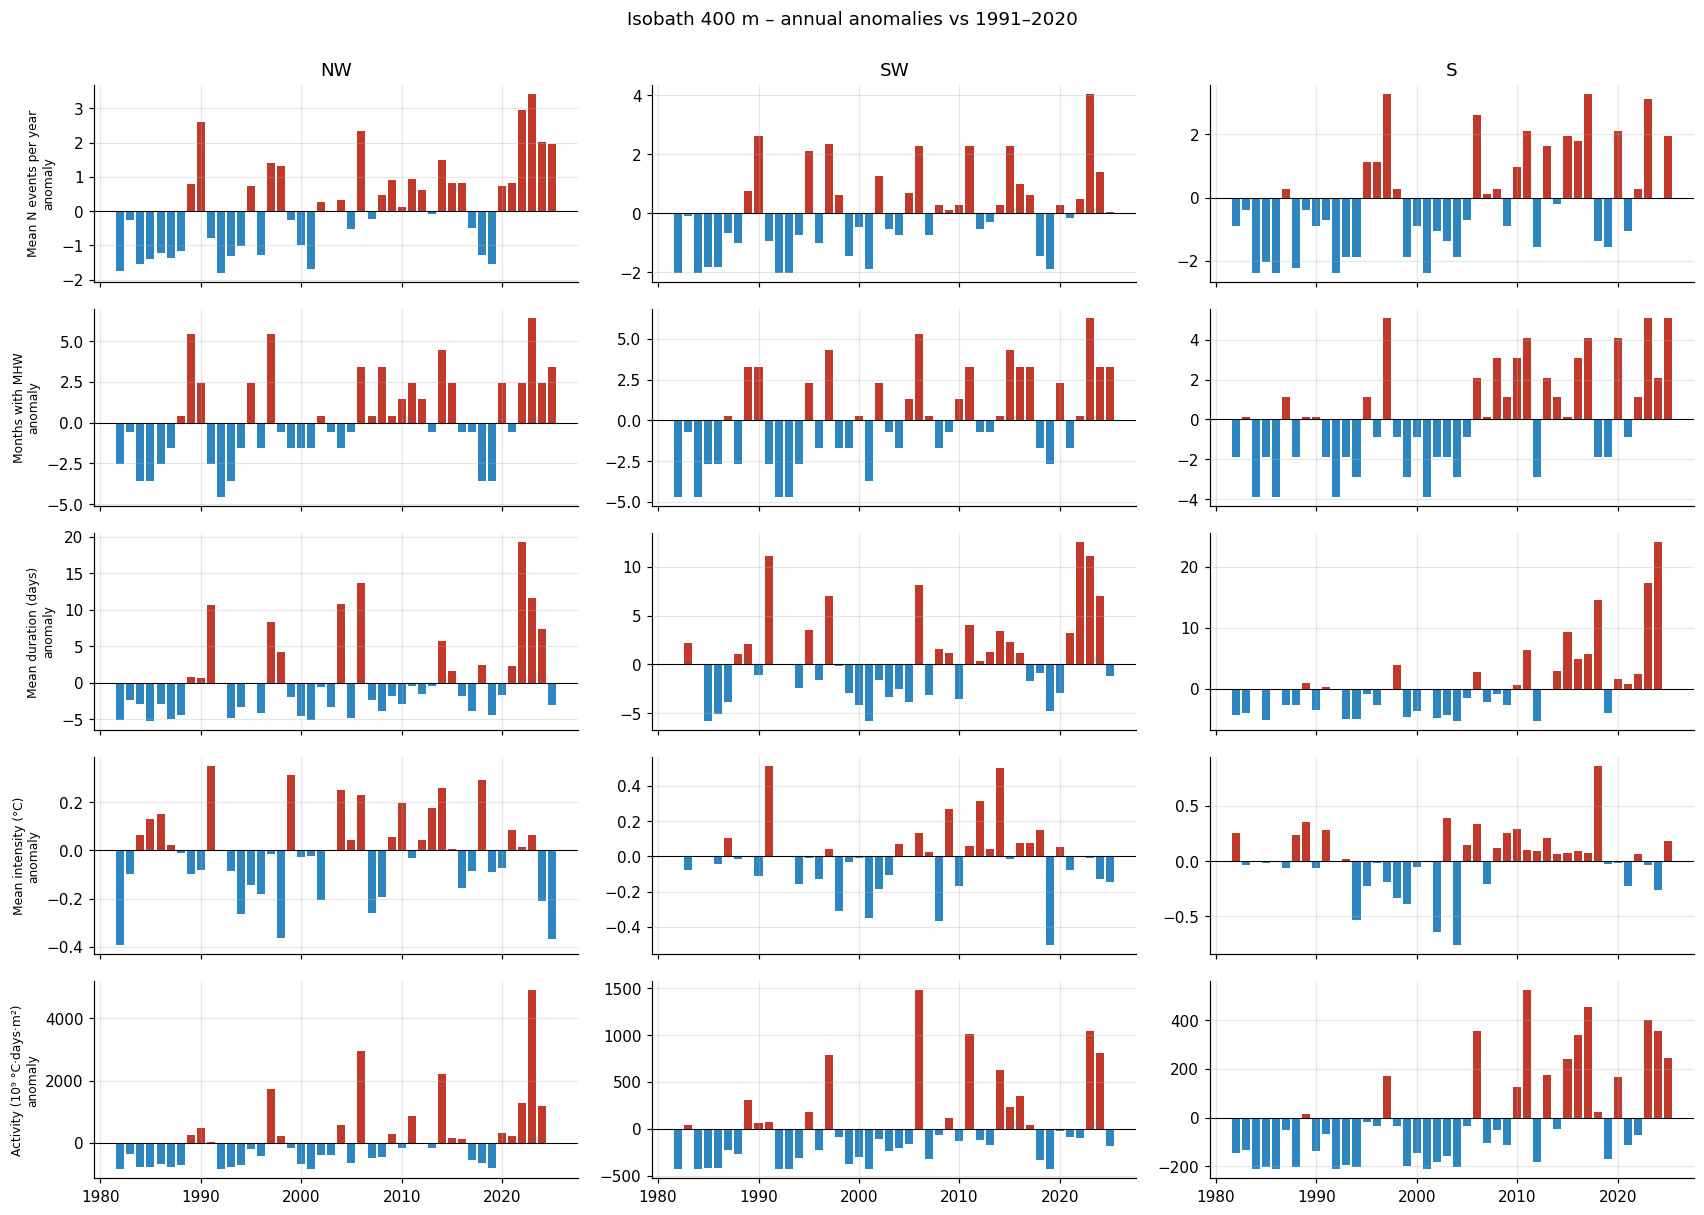

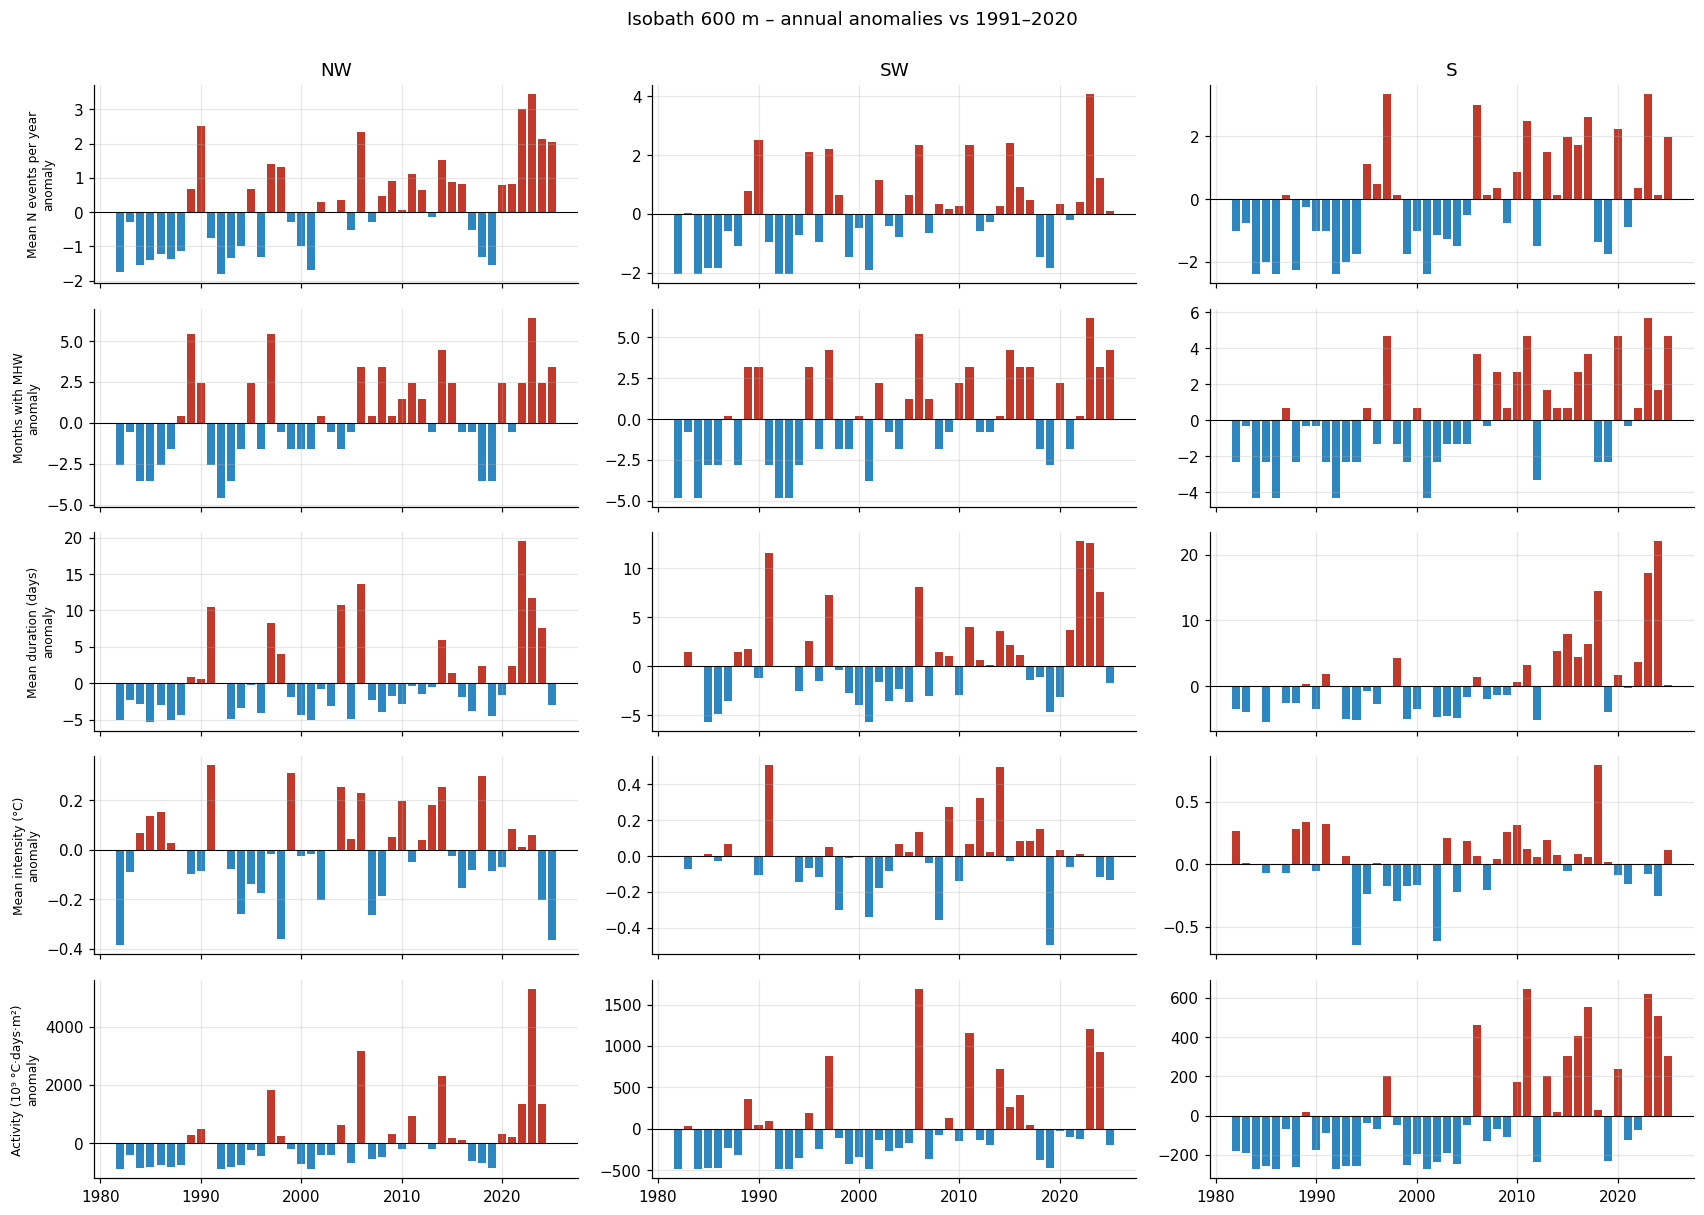

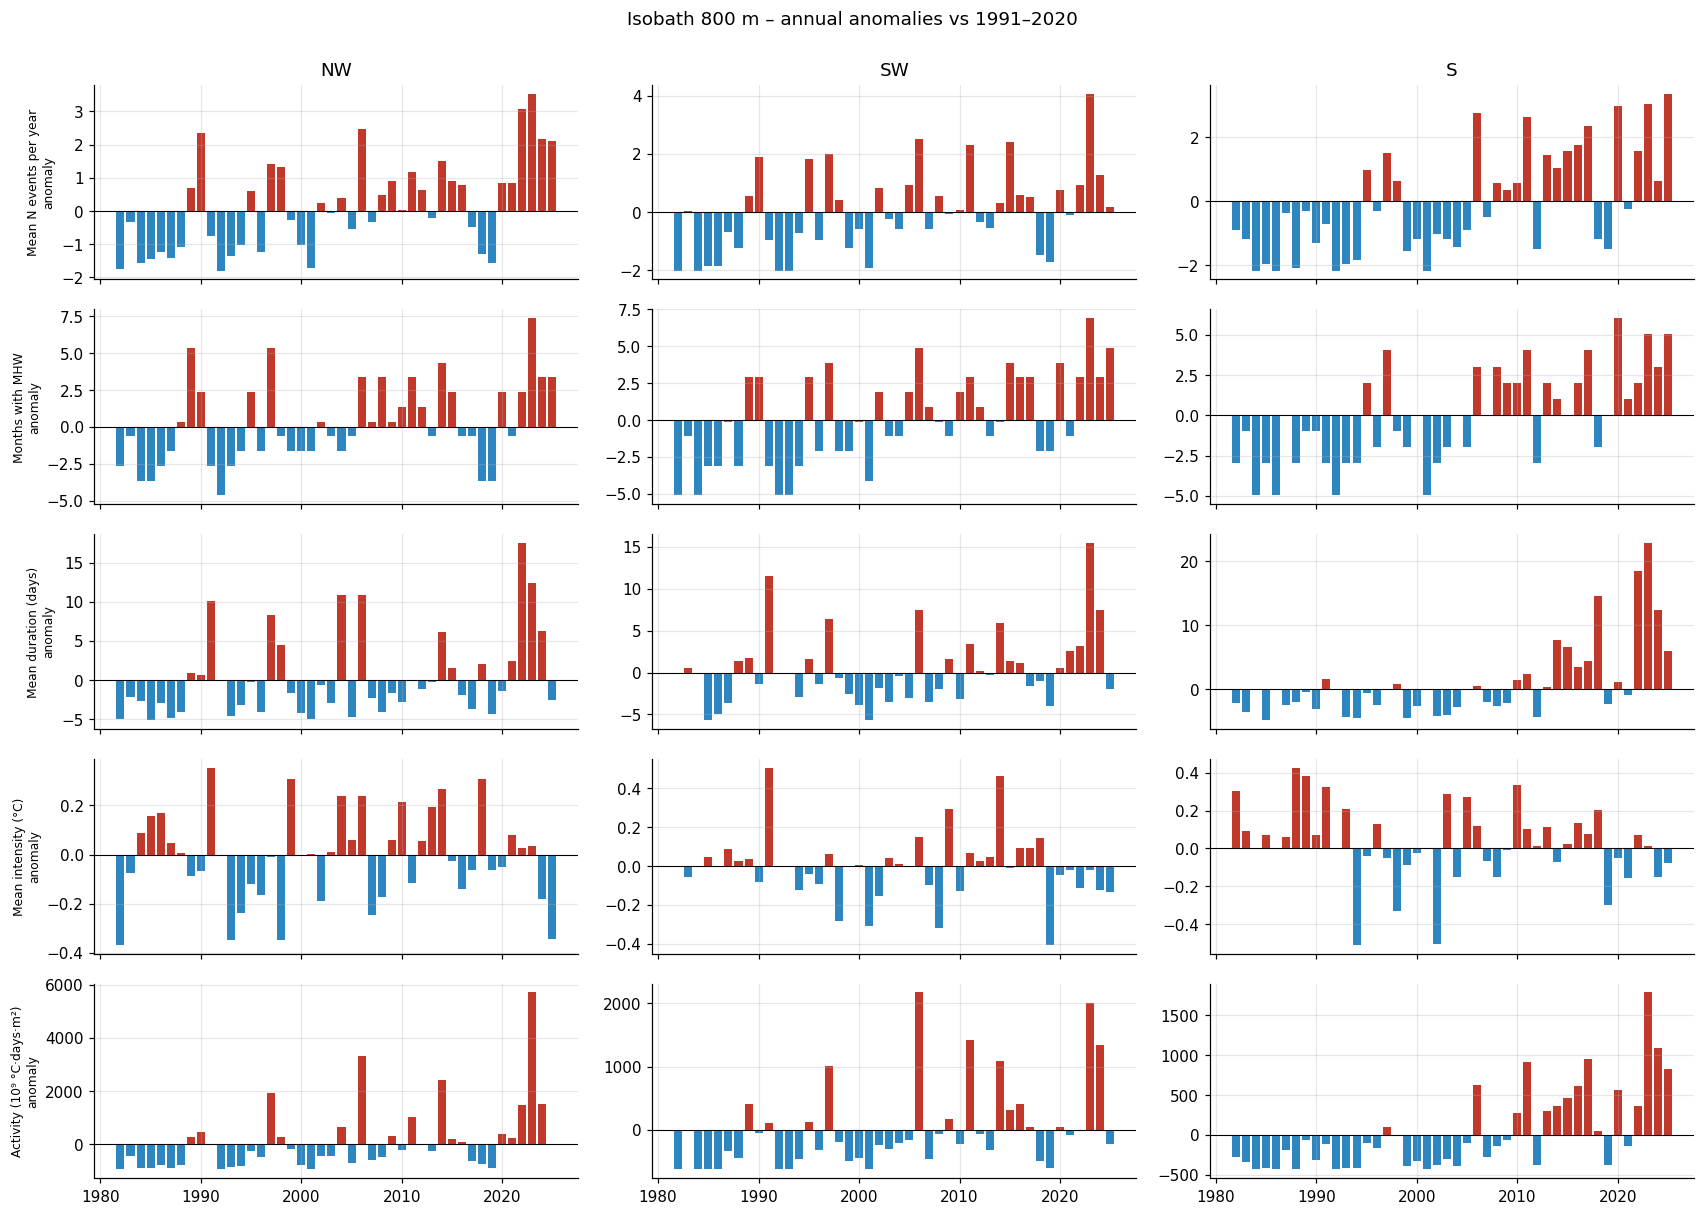

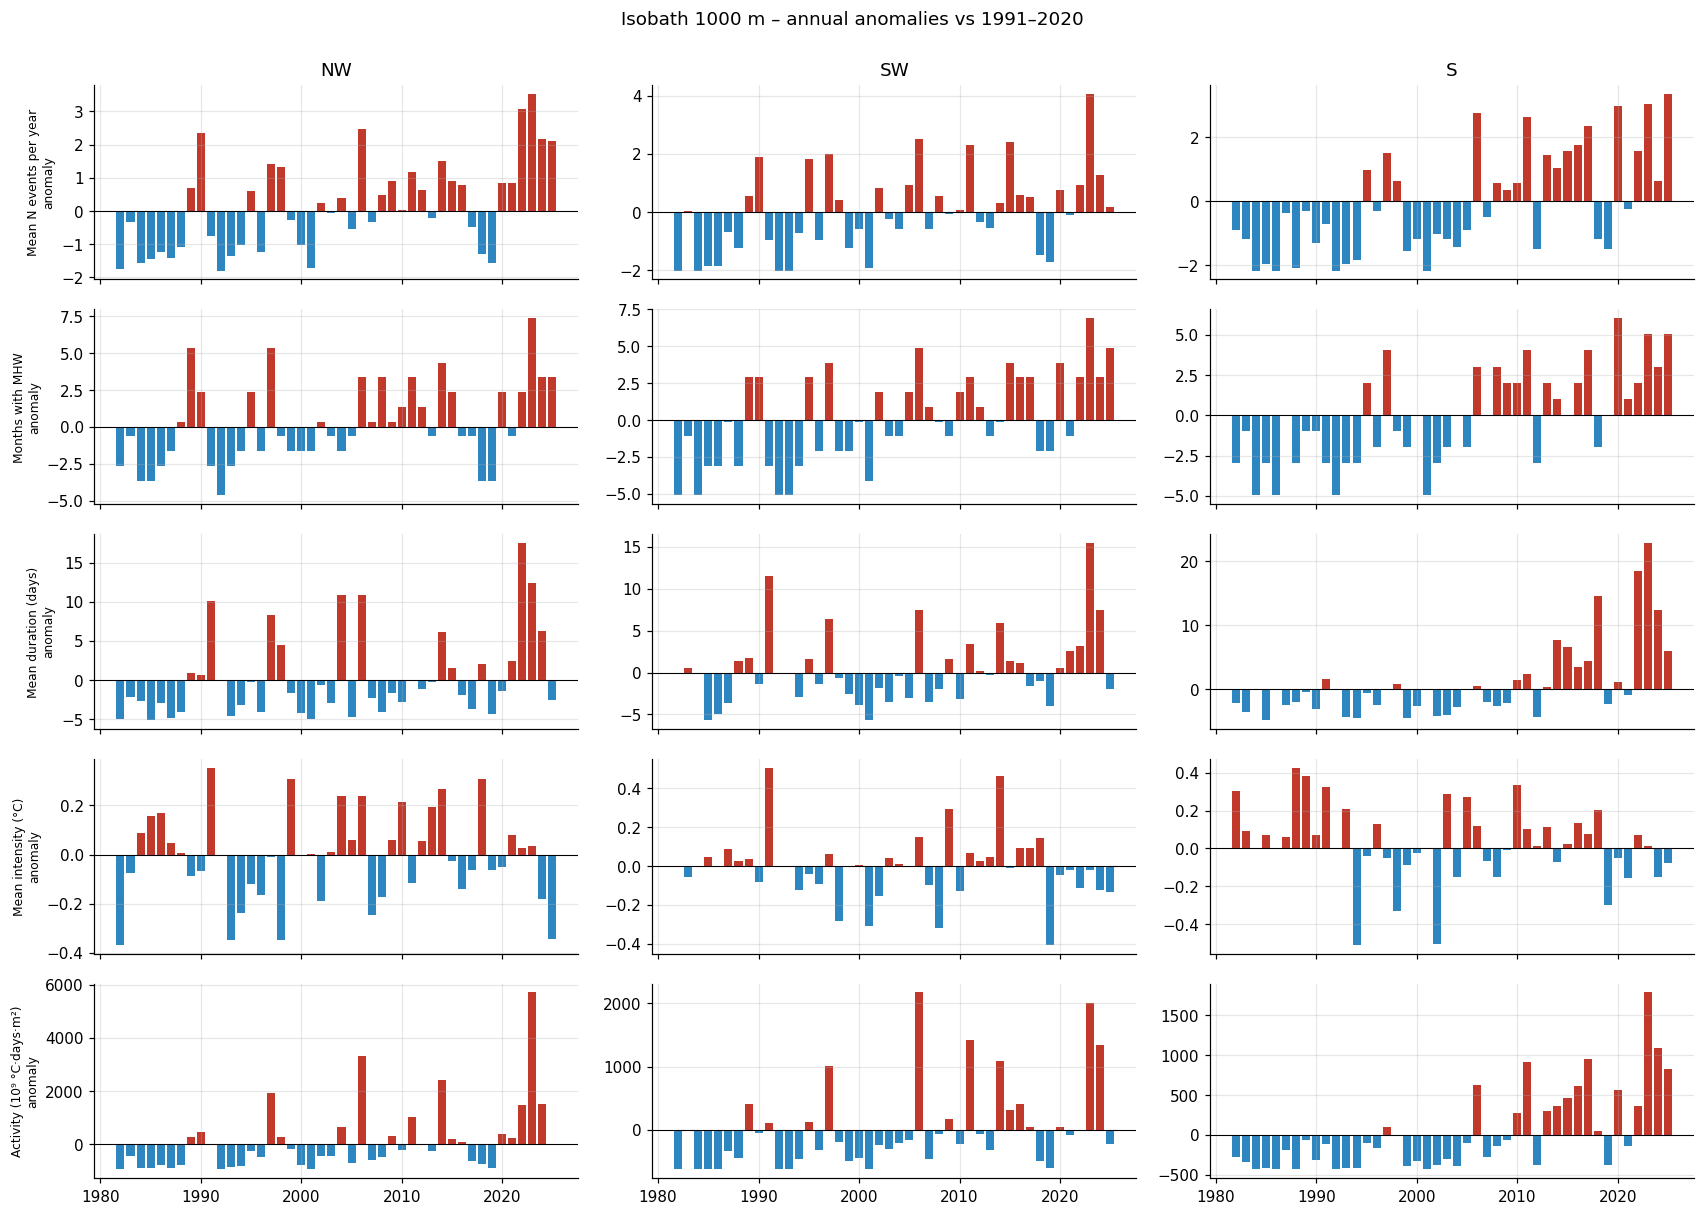

In [31]:
# Annual anomalies (relative to 1991–2020): red = above, blue = below
for iso in iso_list:
    fig, axes = plt.subplots(len(ann_panels), len(ZONES), figsize=(5.2*len(ZONES), 2.2*len(ann_panels)),
                             sharex=True, squeeze=False)
    for j, z in enumerate(ZONES):
        g = anom[(anom.Isobath == iso) & (anom.Zone == z)]
        for r, (v, lab) in enumerate(ann_panels):
            ax = axes[r, j]; y = g[v]
            ax.bar(g.Year, y, color=np.where(y >= 0, "#c0392b", "#2e86c1"), width=.8)
            ax.axhline(0, color="k", lw=.7)
            if j == 0: ax.set_ylabel(lab + "\nanomaly", fontsize=8)
            if r == 0: ax.set_title(z)
    fig.suptitle(f"Isobath {iso} m – annual anomalies vs 1991–2020", y=1.0)
    fig.tight_layout(); fig.savefig(FIG / f"annual_anomalies_{iso}m.png", bbox_inches="tight"); plt.show()

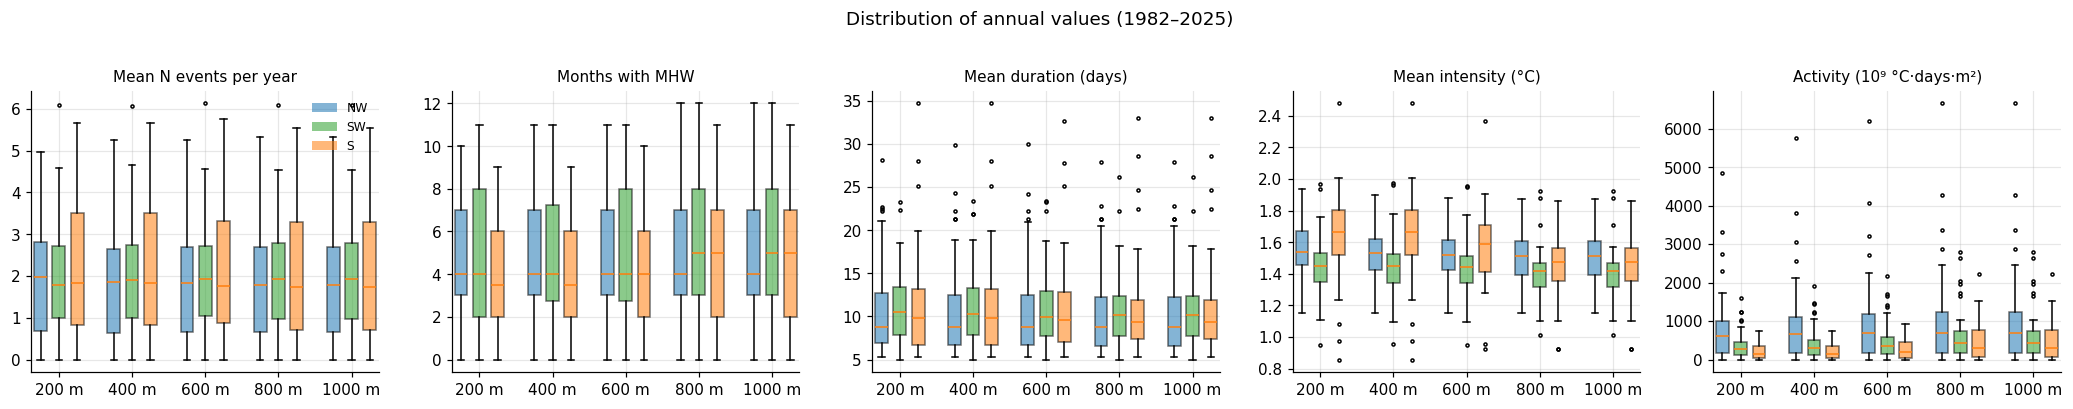

In [32]:
# Distribution of annual values (boxplot by zone and isobath)
fig, axes = plt.subplots(1, len(ann_panels), figsize=(3.8*len(ann_panels), 3.6))
for ax, (v, lab) in zip(axes, ann_panels):
    pos, data, cols, ticks = [], [], [], []
    for i, iso in enumerate(iso_list):
        for j, z in enumerate(ZONES):
            pos.append(i*(len(ZONES)+1) + j); cols.append(colors[z])
            data.append(annual[(annual.Isobath == iso) & (annual.Zone == z)][v].dropna())
        ticks.append(i*(len(ZONES)+1) + (len(ZONES)-1)/2)
    bp = ax.boxplot(data, positions=pos, widths=.7, patch_artist=True, flierprops=dict(markersize=2))
    for b, c in zip(bp["boxes"], cols): b.set(facecolor=c, alpha=.55)
    ax.set_xticks(ticks, [f"{i} m" for i in iso_list]); ax.set_title(lab, fontsize=10)
axes[0].legend([plt.Rectangle((0,0),1,1,fc=colors[z],alpha=.55) for z in ZONES], ZONES, frameon=False, fontsize=8)
fig.suptitle("Distribution of annual values (1982–2025)", y=1.02); fig.tight_layout()
fig.savefig(FIG / "annual_boxplots.png", bbox_inches="tight"); plt.show()

### 7n. Half-decade (5-year) statistics
Mean of annual values per 5-year period ± SD.

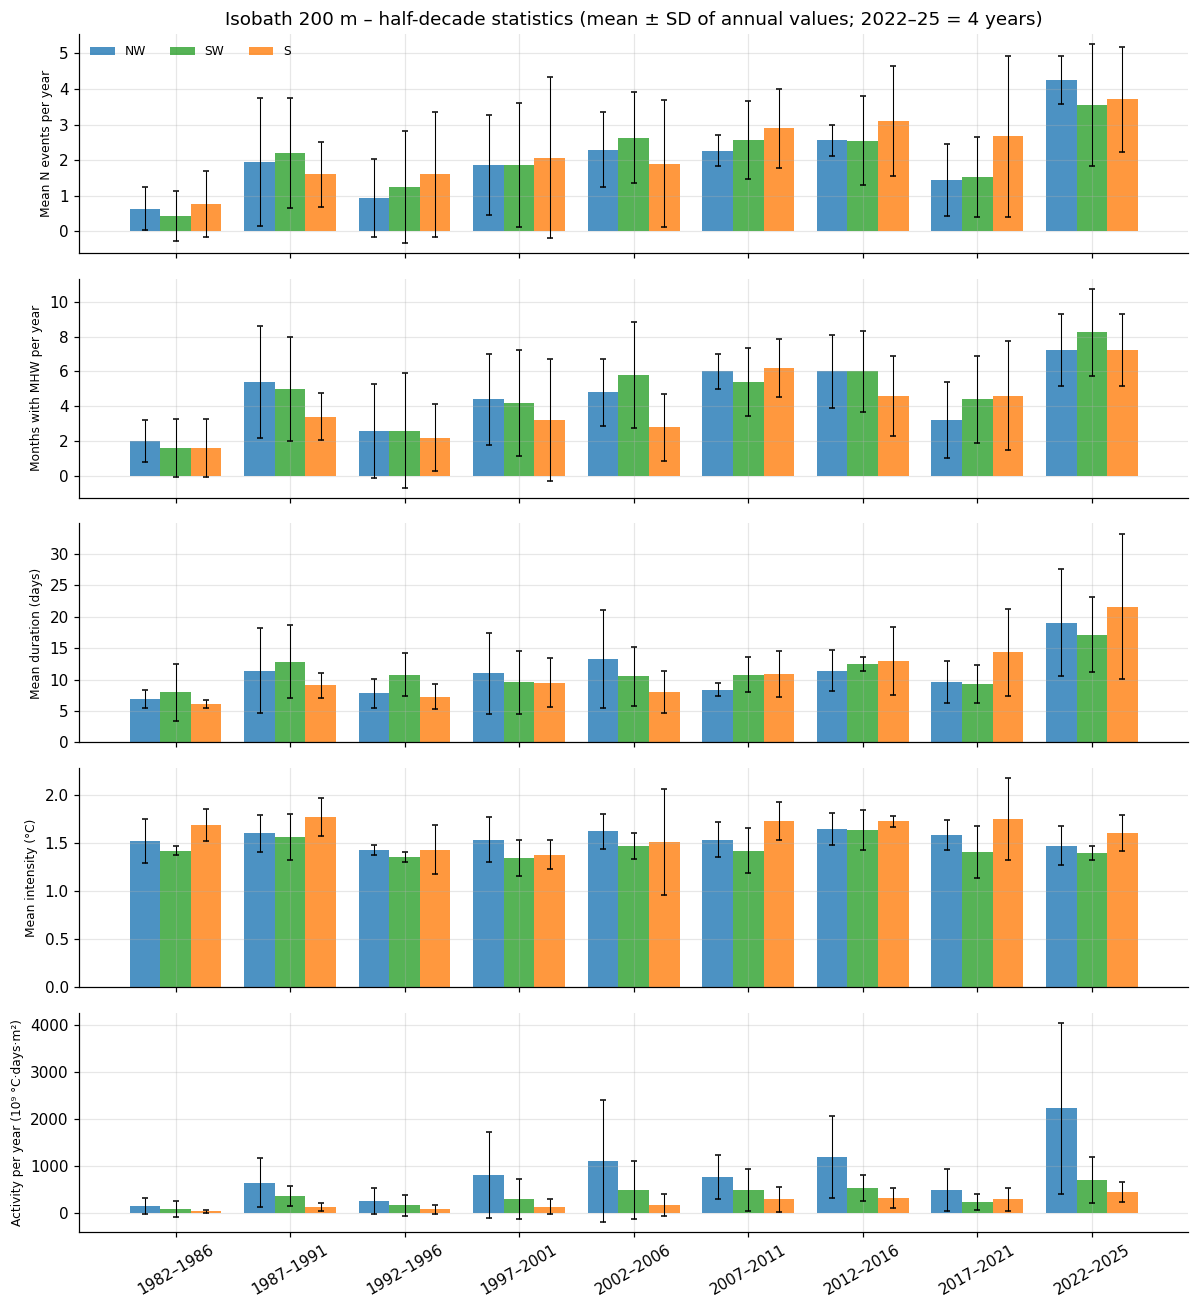

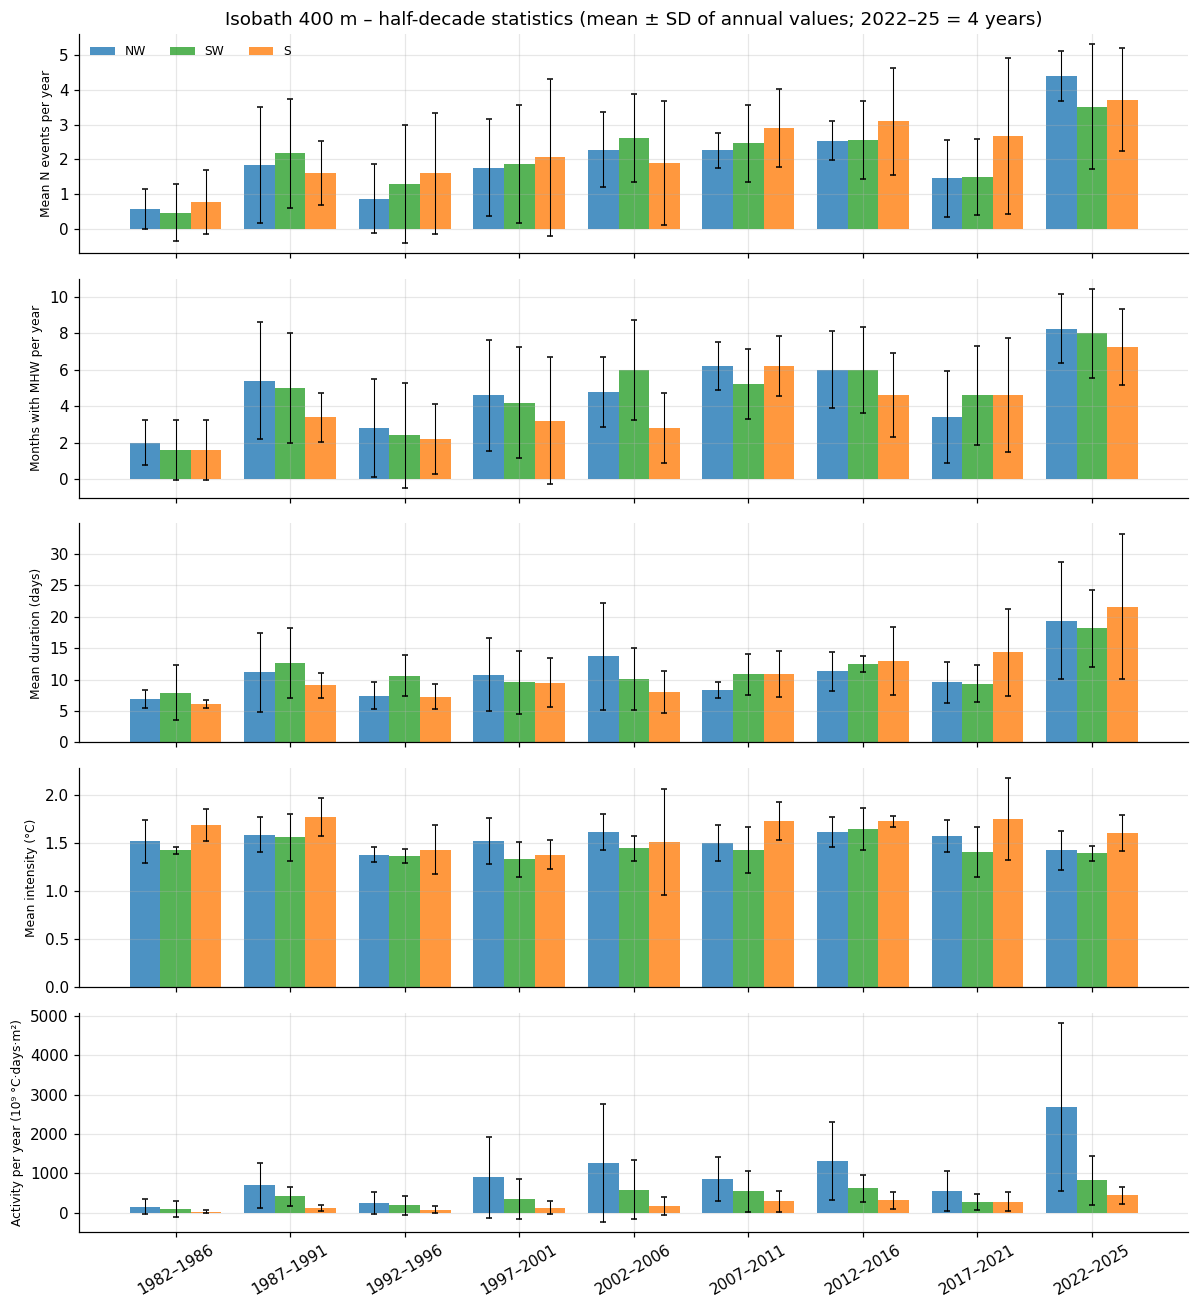

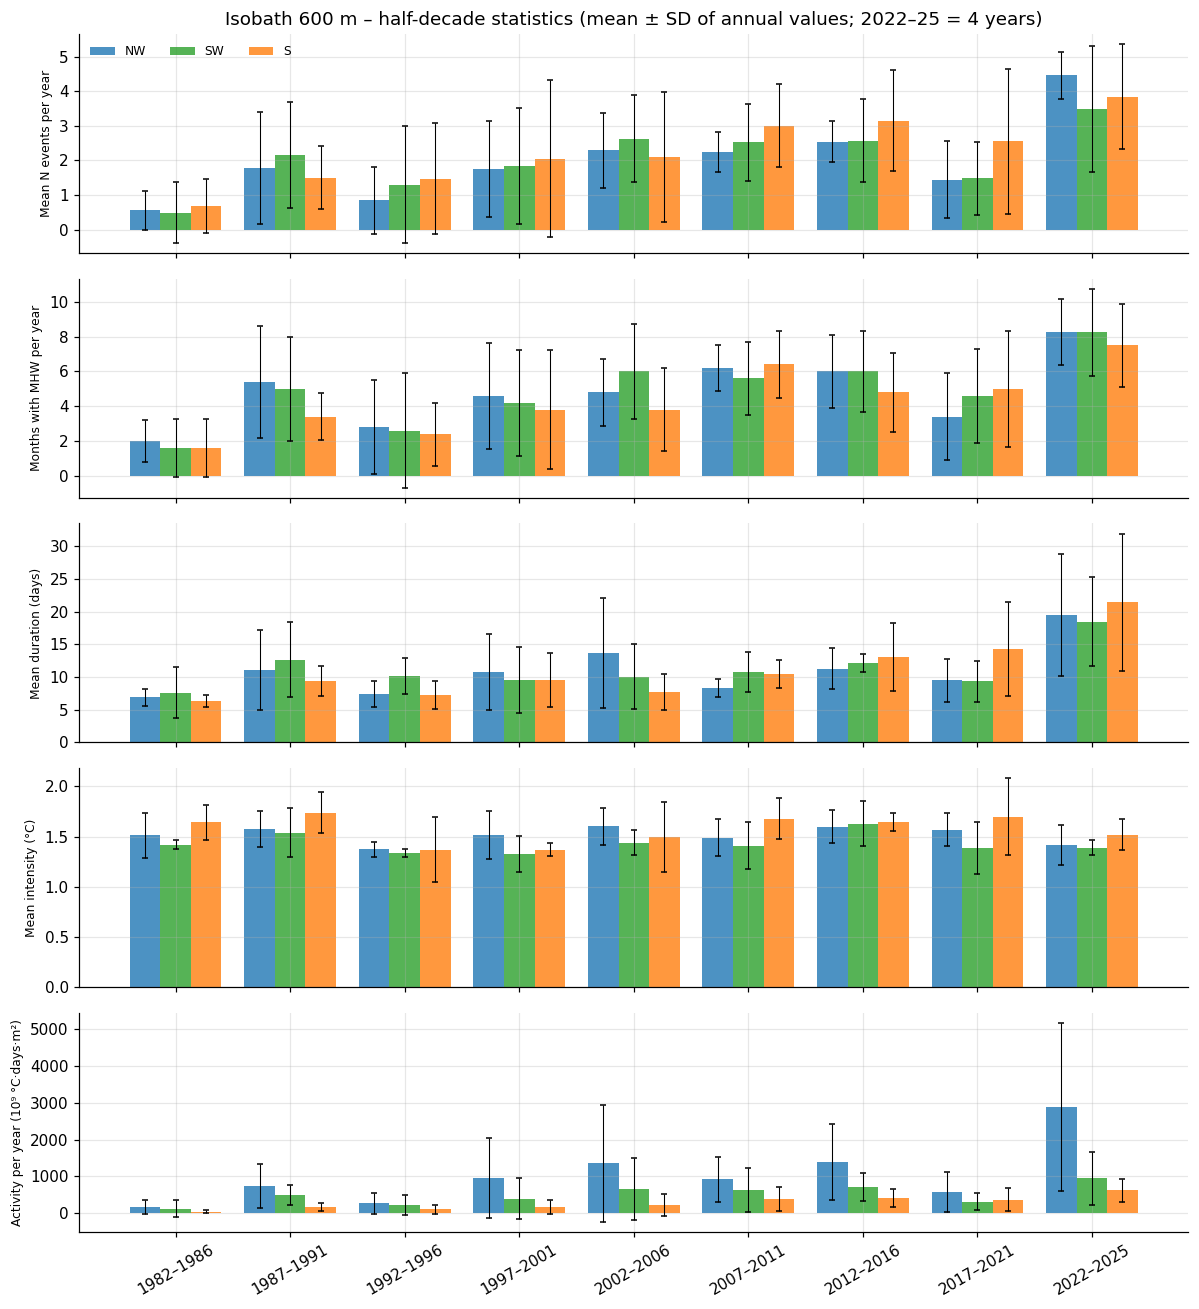

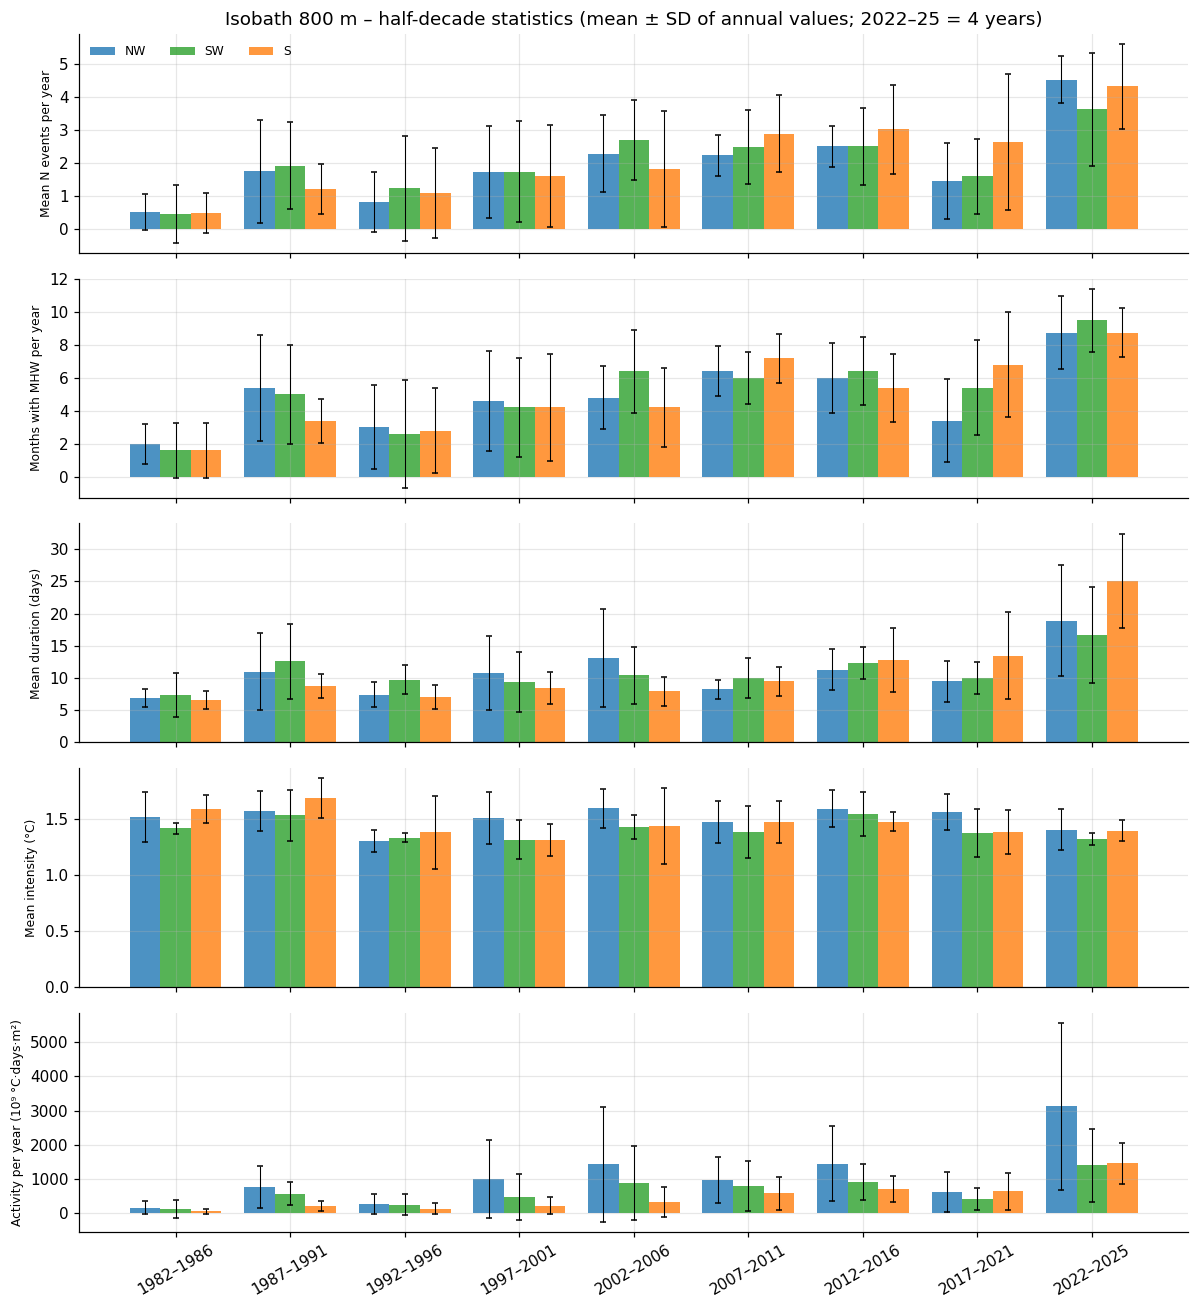

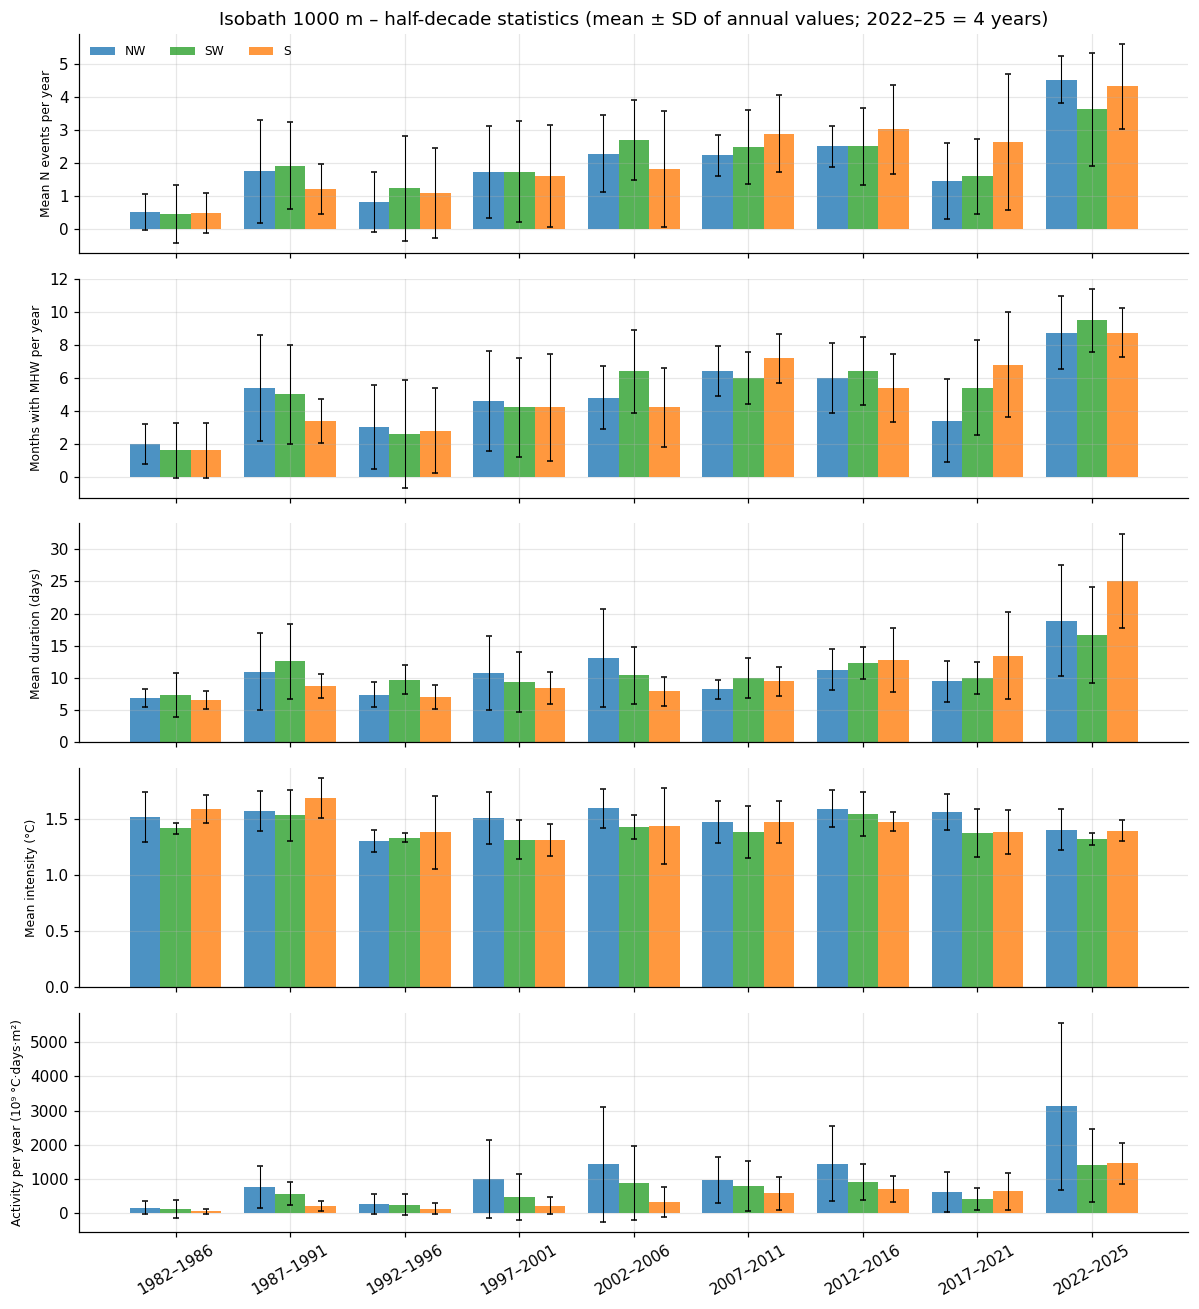

In [33]:
P = pentad.reset_index()
pent_panels = [("events_mean","events_sd","Mean N events per year"),
               ("active_months_mean","active_months_sd","Months with MHW per year"),
               ("duration_mean","duration_sd","Mean duration (days)"),
               ("intensity_mean","intensity_sd","Mean intensity (°C)"),
               ("activity_mean","activity_sd","Activity per year (10⁹ °C·days·m²)")]
w = 0.8 / len(ZONES)
for iso in iso_list:
    fig, axes = plt.subplots(len(pent_panels), 1, figsize=(11, 2.4*len(pent_panels)), sharex=True)
    for ax, (v, e, lab) in zip(axes, pent_panels):
        for j, z in enumerate(ZONES):
            g = P[(P.Isobath == iso) & (P.Zone == z)].set_index("Pentad").reindex(PENTADS)
            x = np.arange(len(PENTADS)) + (j-(len(ZONES)-1)/2)*w
            ax.bar(x, g[v], w, yerr=g[e], capsize=2, color=colors[z], alpha=.8, label=z, error_kw=dict(lw=.7))
        ax.set_ylabel(lab, fontsize=8)
    axes[-1].set_xticks(range(len(PENTADS)), PENTADS, rotation=30)
    axes[0].legend(frameon=False, ncol=3, fontsize=8)
    axes[0].set_title(f"Isobath {iso} m – half-decade statistics (mean ± SD of annual values; 2022–25 = 4 years)")
    fig.tight_layout(); fig.savefig(FIG / f"halfdecade_bars_{iso}m.png", bbox_inches="tight"); plt.show()

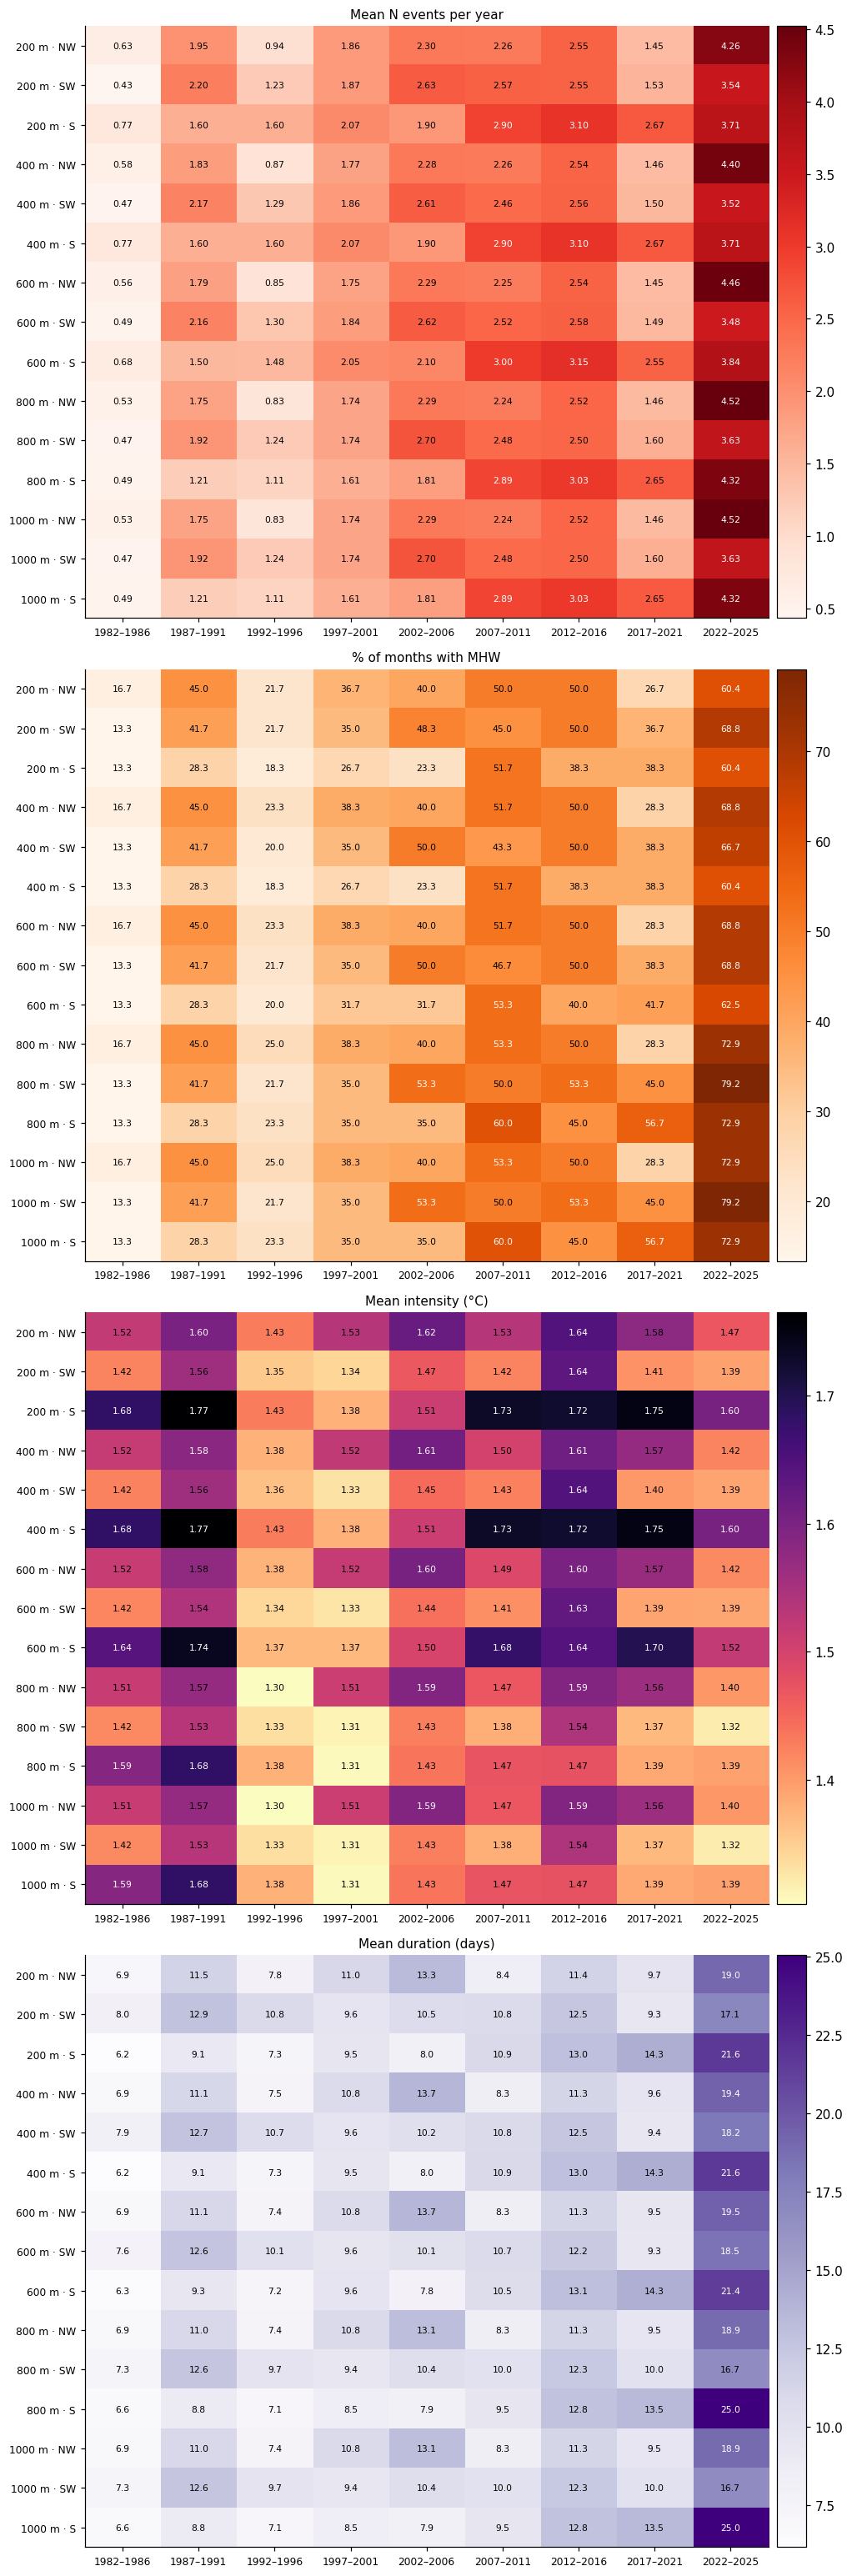

In [34]:
# Half-decade heatmap: rows = zone (× isobath), columns = 5-year period
hm = [("events_mean","Mean N events per year","Reds"), ("pct_active","% of months with MHW","Oranges"),
      ("intensity_mean","Mean intensity (°C)","magma_r"), ("duration_mean","Mean duration (days)","Purples")]
fig, axes = plt.subplots(len(hm), 1, figsize=(10, 1.2 + .45*len(iso_list)*len(ZONES)*len(hm)))
for ax, (v, lab, cm) in zip(axes, hm):
    M = P.pivot_table(index=["Isobath","Zone"], columns="Pentad", values=v).reindex(columns=PENTADS)
    im = ax.imshow(M, aspect="auto", cmap=cm)
    for (a, b), val in np.ndenumerate(M.values):
        if not np.isnan(val):
            dark = im.norm(val) > .6
            ax.text(b, a, f"{val:.2f}" if ("intensity" in v or "events" in v) else f"{val:.1f}", ha="center", va="center",
                    fontsize=7, color="white" if dark else "black")
    ax.set_yticks(range(len(M)), [f"{i} m · {z}" for i, z in M.index], fontsize=8)
    ax.set_xticks(range(len(PENTADS)), PENTADS, fontsize=8); ax.grid(False)
    ax.set_title(lab, fontsize=10); fig.colorbar(im, ax=ax, pad=.01)
fig.tight_layout(); fig.savefig(FIG / "halfdecade_heatmap.png", bbox_inches="tight"); plt.show()

## 8. Export tables

In [35]:
xlsx = OUT_DIR / "MHW_descriptive_statistics.xlsx"
with pd.ExcelWriter(xlsx) as w:
    check.to_excel(w, sheet_name="completeness")
    T_all.to_excel(w, sheet_name="monthly_all")
    T_mhw.to_excel(w, sheet_name="monthly_MHW_only")
    compact.to_excel(w, sheet_name="compact_MHW")
    T_annual.to_excel(w, sheet_name="annual_stats")
    anom.to_excel(w, sheet_name="annual_anomalies", index=False)
    pentad.to_excel(w, sheet_name="halfdecade_summary")
    T_pentad.to_excel(w, sheet_name="halfdecade_stats")
    annual.to_excel(w, sheet_name="annual_series", index=False)
    top.to_excel(w, sheet_name="top_years", index=False)
    T_trend.to_excel(w, sheet_name="trends")
    seasonal.to_excel(w, sheet_name="seasonal")
    decadal.to_excel(w, sheet_name="decadal")
    T_kw.to_excel(w, sheet_name="kruskal_wallis")
    pivot_iso.to_excel(w, sheet_name="isobath_pivot")
print("Saved:", xlsx, "and figures in", FIG)

Saved: outputs/MHW_descriptive_statistics.xlsx and figures in outputs/figures
